# 1. Data cleaning

### 1.1 Data Loading and Initial Inspection
Load the dataset and understand its size and structure (number of rows, columns, and general layout).

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor,GradientBoostingRegressor, AdaBoostRegressor
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import (
    LinearRegression,
    LogisticRegression,
    Ridge,
    Lasso,
    )
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.utils.class_weight import compute_class_weight
from scipy.optimize import minimize
from google.colab import files
from datetime import datetime
import time
import logging
import requests
import pandas as pd
import yfinance as yf
from tqdm import tqdm
import warnings


# Load dataset (update file name if needed)
df = pd.read_csv("adjprice.csv", index_col = False, sep = ',')

# Shape of dataset
print("Dataset shape:", df.shape)

# Preview data
df.head()

Dataset shape: (9459, 1200)


,Date,0111145D US Equity,0202445Q US Equity,0203524D US Equity,0226226D US Equity,0376152D US Equity,0440296D US Equity,0544749D US Equity,0574018D US Equity,0598884D US Equity,...,YNR US Equity,YRCW US Equity,YUM US Equity,YUMC US Equity,ZBH US Equity,ZETHQ US Equity,ZION US Equity,ZRN US Equity,ZTS US Equity,ZTS-W US Equity
0,19930907,13.2719,13.6829,8.4429,8.1042,11.000,57.3245,17.8887,6.8315,28.1246,...,NaN,144439.5121,NaN,NaN,NaN,6.875,7.1675,30.7970,NaN,NaN
1,19930908,13.3263,13.5315,8.2147,7.9590,11.000,57.2096,17.8064,6.8315,27.5051,...,NaN,143691.1208,NaN,NaN,NaN,6.750,6.9766,30.0188,NaN,NaN
2,19930909,13.7070,13.3800,8.7852,8.0627,11.125,59.1625,17.6831,6.8315,27.7529,...,NaN,143691.1208,NaN,NaN,NaN,6.625,6.9554,30.0188,NaN,NaN
3,19930910,13.3807,13.4810,9.4127,8.0368,11.125,59.6220,17.6420,6.8773,27.5051,...,NaN,145187.9033,NaN,NaN,NaN,6.750,7.2099,29.6852,NaN,NaN
4,19930911,13.3807,13.4810,9.4127,8.0368,11.125,59.6220,17.6420,6.8773,27.5051,...,NaN,145187.9033,NaN,NaN,NaN,6.750,7.2099,29.6852,NaN,NaN


The dataset contains 9459 rows (dates) and 1200 columns (assets).
Each column represents a financial asset, and each row corresponds to a trading day.

### 1.2 Date Conversion and Indexing
Convert the Date column into a proper datetime format and set it as the index for time series analysis.

In [ ]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y%m%d')

# Set Date as index
df = df.set_index('Date')

# Check result
df.head()

,0111145D US Equity,0202445Q US Equity,0203524D US Equity,0226226D US Equity,0376152D US Equity,0440296D US Equity,0544749D US Equity,0574018D US Equity,0598884D US Equity,0772031D US Equity,...,YNR US Equity,YRCW US Equity,YUM US Equity,YUMC US Equity,ZBH US Equity,ZETHQ US Equity,ZION US Equity,ZRN US Equity,ZTS US Equity,ZTS-W US Equity
Date,,,,,,,,,,,,,,,,,,,,,
1993-09-07,13.2719,13.6829,8.4429,8.1042,11.000,57.3245,17.8887,6.8315,28.1246,NaN,...,NaN,144439.5121,NaN,NaN,NaN,6.875,7.1675,30.7970,NaN,NaN
1993-09-08,13.3263,13.5315,8.2147,7.9590,11.000,57.2096,17.8064,6.8315,27.5051,NaN,...,NaN,143691.1208,NaN,NaN,NaN,6.750,6.9766,30.0188,NaN,NaN
1993-09-09,13.7070,13.3800,8.7852,8.0627,11.125,59.1625,17.6831,6.8315,27.7529,NaN,...,NaN,143691.1208,NaN,NaN,NaN,6.625,6.9554,30.0188,NaN,NaN
1993-09-10,13.3807,13.4810,9.4127,8.0368,11.125,59.6220,17.6420,6.8773,27.5051,NaN,...,NaN,145187.9033,NaN,NaN,NaN,6.750,7.2099,29.6852,NaN,NaN
1993-09-11,13.3807,13.4810,9.4127,8.0368,11.125,59.6220,17.6420,6.8773,27.5051,NaN,...,NaN,145187.9033,NaN,NaN,NaN,6.750,7.2099,29.6852,NaN,NaN


The dataset is now structured as a time series, with dates properly formatted, enabling chronological analysis.

### 1.3 Filtering Valid Equity Columns
Remove non-equity or irrelevant columns by keeping only those that contain 'US Equity'.

In [ ]:
# Keep only US Equity columns
cols = [c for c in df.columns if 'US Equity' in c]
df = df[cols]

print("Remaining columns:", len(df.columns))


Remaining columns: 1199


All columns are US Equities.

⚠️ Limitation of Initial Approach
🔹 Insight

Although all columns were labelled as “US Equity”, further inspection revealed that this category includes non-standard securities, such as:

Warrants (e.g., -W)
Distressed or delisted stocks (e.g., Q)
Irregular financial instruments

This means that the initial filtering approach was insufficient for ensuring data quality.

In [ ]:
# Investigate suspicious tickers

q_cols = [c for c in df.columns if 'Q' in c]
w_cols = [c for c in df.columns if '-W' in c]

print("Number of 'Q' columns:", len(q_cols))
print("Number of '-W' columns:", len(w_cols))

print("\nSample 'Q' columns:", q_cols[:5])
print("Sample '-W' columns:", w_cols[:5])

Number of 'Q' columns: 240
Number of '-W' columns: 2

Sample 'Q' columns: ['0202445Q US Equity', '1028411Q US Equity', '1166Q US Equity', '1199Q US Equity', '1237Q US Equity']
Sample '-W' columns: ['MJN-W US Equity', 'ZTS-W US Equity']


A significant number of columns contained identifiers such as “Q” and “-W”, confirming the presence of non-standard or irregular securities within the dataset.

### 1.3.1 Filtering Valid Equity Columns
Refine the filtering process by removing non-standard securities to retain only consistent and comparable stocks.

In [ ]:
# Improved filtering

cols = [c for c in df.columns if 'US Equity' in c]

clean_cols = [
    c for c in cols
    if ('-W' not in c) and ('Q' not in c)
]

df = df[clean_cols]

print("Remaining columns:", len(df.columns))

Remaining columns: 957


After applying stricter filtering, the number of assets reduced significantly to 957 , ensuring that only standard equity securities are retained for analysis.

### 1.4 Missing Data Analysis and Threshold Selection

Analyse the distribution of missing values across stocks to determine an appropriate filtering threshold.

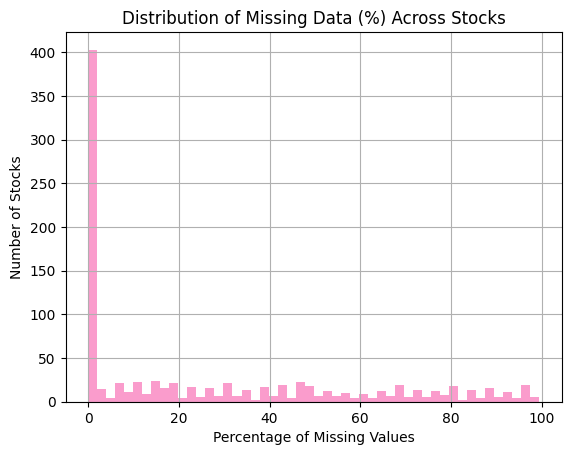

In [ ]:
import matplotlib.pyplot as plt

# Percentage of missing values
missing_pct = df.isnull().mean() * 100

# Plot distribution
missing_pct.hist(bins=50,color="#FA9CCC")
plt.title("Distribution of Missing Data (%) Across Stocks")
plt.xlabel("Percentage of Missing Values")
plt.ylabel("Number of Stocks")
plt.show()

The histogram shows a large concentration of stocks with near-zero missing values, while the remaining stocks are spread across higher missing percentages.
This supports the use of an 90% data availability threshold to retain reliable stocks and remove those with significant missing data.

=== Missing Data Summary (quote these in your report) ===
Total stocks assessed:                957
Stocks with <1%  missing:             393  (41.1%)
Stocks with <10% missing:             453  (47.3%)
Stocks with >50% missing:             229  (23.9%)
Stocks with >90% missing (removed):   43  (4.5%)
Median missingness:                   12.50%
Mean missingness:                     26.72%


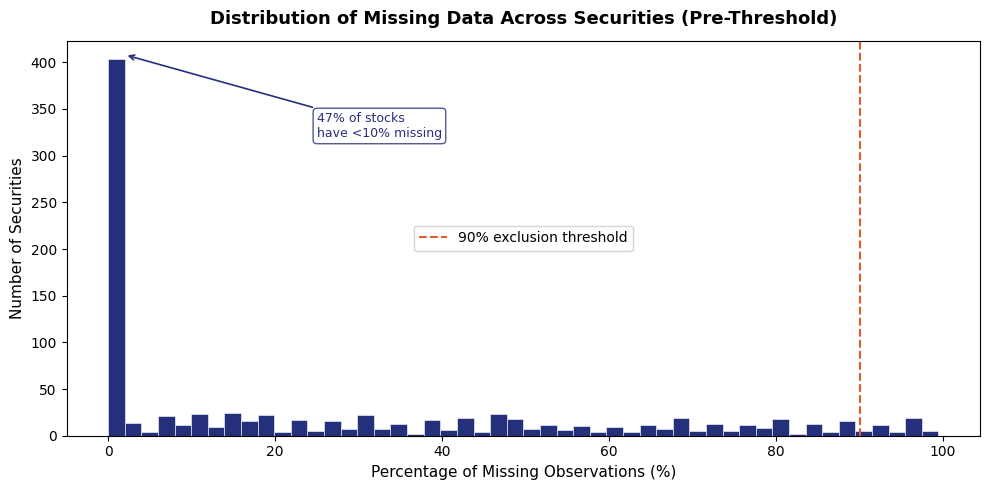

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Percentage of missing values per stock
missing_pct = df.isnull().mean() * 100

# ── Summary statistics for your report ──────────────────────────────────────
total_stocks = len(missing_pct)

pct_under_10   = (missing_pct < 10).sum() / total_stocks * 100
pct_under_1    = (missing_pct < 1).sum()  / total_stocks * 100
pct_over_50    = (missing_pct > 50).sum() / total_stocks * 100
pct_over_90    = (missing_pct > 90).sum() / total_stocks * 100  # would be removed by threshold
median_missing = missing_pct.median()
mean_missing   = missing_pct.mean()

print("=== Missing Data Summary (quote these in your report) ===")
print(f"Total stocks assessed:                {total_stocks}")
print(f"Stocks with <1%  missing:             {(missing_pct < 1).sum()}  ({pct_under_1:.1f}%)")
print(f"Stocks with <10% missing:             {(missing_pct < 10).sum()}  ({pct_under_10:.1f}%)")
print(f"Stocks with >50% missing:             {(missing_pct > 50).sum()}  ({pct_over_50:.1f}%)")
print(f"Stocks with >90% missing (removed):   {(missing_pct > 90).sum()}  ({pct_over_90:.1f}%)")
print(f"Median missingness:                   {median_missing:.2f}%")
print(f"Mean missingness:                     {mean_missing:.2f}%")

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(missing_pct, bins=50, color="#25307D", edgecolor="white", linewidth=0.4)

# Mark the 90% threshold you applied
ax.axvline(x=90, color="#E05C2A", linestyle="--", linewidth=1.5,
           label="90% exclusion threshold")

ax.set_title("Distribution of Missing Data Across Securities (Pre-Threshold)",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Percentage of Missing Observations (%)", fontsize=11)
ax.set_ylabel("Number of Securities", fontsize=11)
ax.legend(fontsize=10)

# Annotate the two clusters directly on the chart
ax.annotate(f"{pct_under_10:.0f}% of stocks\nhave <10% missing",
            xy=(2, 408),           # arrow tip → top of first bar
            xytext=(25, 320),      # text box position
            fontsize=9, color="#25307D",
            arrowprops=dict(arrowstyle="->", color="#25307D", lw=1.2),
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor="#25307D", alpha=0.8))

plt.tight_layout()
plt.savefig("missing_data_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
thresholds = range(50, 100, 5)
for t in thresholds:
    kept = (missing_pct < (100 - t)).sum()
# OR reframe it as: keep stocks where availability > threshold
availability_pct = (1 - df.isnull().mean()) * 100
kept = (availability_pct >= t).sum()

# Availability = inverse of missingness
availability_pct = (1 - df.isnull().mean()) * 100

print("=== Threshold Sensitivity (Data Availability) ===")
for t in range(50, 100, 5):
    kept = (availability_pct >= t).sum()
    removed = len(availability_pct) - kept
    print(f"Threshold {t}%: {kept} stocks retained, {removed} removed")

=== Threshold Sensitivity (Data Availability) ===
Threshold 50%: 728 stocks retained, 229 removed
Threshold 55%: 684 stocks retained, 273 removed
Threshold 60%: 658 stocks retained, 299 removed
Threshold 65%: 635 stocks retained, 322 removed
Threshold 70%: 600 stocks retained, 357 removed
Threshold 75%: 571 stocks retained, 386 removed
Threshold 80%: 547 stocks retained, 410 removed
Threshold 85%: 502 stocks retained, 455 removed
Threshold 90%: 453 stocks retained, 504 removed
Threshold 95%: 419 stocks retained, 538 removed


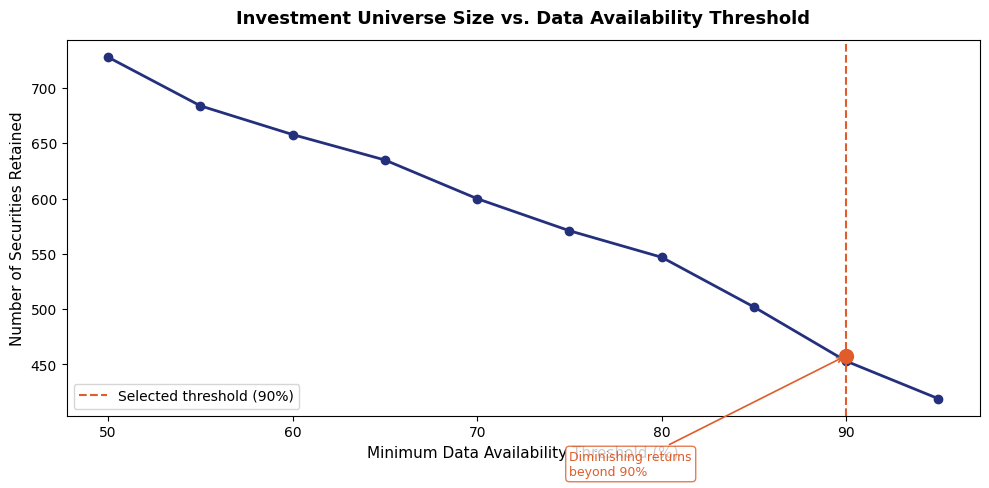

In [ ]:
thresholds = list(range(50, 100, 5))
retained = []

availability_pct = (1 - df.isnull().mean()) * 100
for t in thresholds:
    retained.append((availability_pct >= t).sum())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, retained, color="#25307D", marker="o", linewidth=2, markersize=6)

# Highlight the chosen threshold
ax.axvline(x=90, color="#E05C2A", linestyle="--", linewidth=1.5, label="Selected threshold (90%)")
ax.scatter([90], [458], color="#E05C2A", zorder=5, s=100)

# Annotate the elbow
ax.annotate("Diminishing returns\nbeyond 90%",
            xy=(90, 458), xytext=(75, 350),
            fontsize=9, color="#E05C2A",
            arrowprops=dict(arrowstyle="->", color="#E05C2A", lw=1.2),
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#E05C2A", alpha=0.8))

ax.set_title("Investment Universe Size vs. Data Availability Threshold",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Minimum Data Availability Threshold (%)", fontsize=11)
ax.set_ylabel("Number of Securities Retained", fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("threshold_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
print("Original shape:", df.shape)
# Keep stocks with at least 90% non-missing data

threshold = int(0.9 * len(df))
df = df.dropna(axis=1, thresh=threshold)


# Check new shape
print("Filtered shape:", df.shape)

Original shape: (9459, 957)
Filtered shape: (9459, 453)


Stocks with insufficient historical data are removed, resulting in a more stable and reliable dataset.

### 1.5. Filling Remaining Missing Values
Fill small gaps in data using forward fill.

In [ ]:
# Forward fill missing values
df = df.fillna(method='ffill')


/tmp/ipykernel_669/750233460.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill')


### 1.6.Converting Prices to Returns
🔹 What this step does

Transform price data into returns, which are required for portfolio optimisation.

In [ ]:
# Compute daily returns
returns = df.pct_change()

returns.head()

,1436513D US Equity,AA US Equity,AAPL US Equity,ABC US Equity,ABMD US Equity,ABT US Equity,ABX US Equity,ADBE US Equity,ADI US Equity,ADM US Equity,...,WY US Equity,X US Equity,XEL US Equity,XL US Equity,XLNX US Equity,XOM US Equity,XRAY US Equity,XRX US Equity,YRCW US Equity,ZION US Equity
Date,,,,,,,,,,,,,,,,,,,,,
1993-09-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993-09-08,-0.015126,-0.018836,0.019020,NaN,0.166667,-0.019045,0.005680,0.025641,-0.019691,-0.005289,...,-0.018937,-0.007813,0.000000,-0.005221,-0.023952,0.007693,-0.033788,0.000000,-0.005181,-0.026634
1993-09-09,0.019770,0.006985,-0.028059,NaN,0.000000,0.019415,0.005648,-0.050000,0.035177,-0.005318,...,-0.009636,0.003940,-0.005309,0.000000,0.042935,-0.009540,0.000000,-0.011985,0.000000,-0.003039
1993-09-10,0.000000,-0.005199,0.009665,NaN,-0.057143,0.000000,-0.033708,0.026316,0.033981,0.005346,...,0.016227,0.011763,0.010660,0.000000,0.050006,0.011556,0.034970,0.005201,0.010417,0.036590
1993-09-11,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


The dataset is converted into daily returns, which measure percentage changes in asset prices and are essential for risk-return analysis.

### 1.7 Reshaping Data
Convert the dataset from wide format to long format for easier analysis and visualization.

In [ ]:
long_df = df.reset_index().melt(
    id_vars='Date',
    var_name='Stock',
    value_name='Price'
)

long_df.head()

,Date,Stock,Price
0,1993-09-07,1436513D US Equity,3.0147
1,1993-09-08,1436513D US Equity,2.9691
2,1993-09-09,1436513D US Equity,3.0278
3,1993-09-10,1436513D US Equity,3.0278
4,1993-09-11,1436513D US Equity,3.0278


The dataset is transformed into a long format, making it
easier to group, filter, and visualise individual stock behaviour.

# 2. Exploratory Data Analysis (EDA)



### 2.1 Understanding Returns Distribution
To understand how individual stocks behave in terms of:

- average return
- variability (risk)
- distribution shape

In [ ]:
# Summary statistics of returns
returns.describe()

,1436513D US Equity,AA US Equity,AAPL US Equity,ABC US Equity,ABMD US Equity,ABT US Equity,ABX US Equity,ADBE US Equity,ADI US Equity,ADM US Equity,...,WY US Equity,X US Equity,XEL US Equity,XL US Equity,XLNX US Equity,XOM US Equity,XRAY US Equity,XRX US Equity,YRCW US Equity,ZION US Equity
count,9458.000000,9458.000000,9458.000000,8884.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,...,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000,9458.000000
mean,0.000404,0.000275,0.000863,0.000766,0.001088,0.000431,0.000183,0.000810,0.000675,0.000314,...,0.000277,0.000317,0.000313,0.000442,0.000740,0.000312,0.000348,0.000291,-0.000210,0.000433
std,0.015318,0.020981,0.023223,0.026028,0.035802,0.012798,0.021364,0.024369,0.023854,0.015770,...,0.016429,0.026281,0.012763,0.023724,0.025820,0.012281,0.013924,0.021975,0.042313,0.021874
min,-0.124902,-0.160537,-0.518696,-0.266899,-0.313320,-0.161375,-0.157005,-0.297580,-0.181487,-0.168282,...,-0.171609,-0.267761,-0.367681,-0.538021,-0.210900,-0.139525,-0.246699,-0.257482,-0.772080,-0.245441
25%,-0.002763,-0.006350,-0.005432,-0.003776,-0.008064,-0.003322,-0.006897,-0.005842,-0.005592,-0.004497,...,-0.005146,-0.008531,-0.002709,-0.003166,-0.006380,-0.003469,-0.003470,-0.005232,-0.009520,-0.004178
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.003554,0.006464,0.007160,0.005172,0.008651,0.004612,0.006107,0.006966,0.006672,0.005040,...,0.005459,0.008299,0.003812,0.003551,0.007098,0.004382,0.004415,0.005814,0.007028,0.005433
max,0.137014,0.232114,0.332103,1.840890,0.292778,0.124659,0.313105,0.296763,0.209137,0.173377,...,0.140386,0.244438,0.234661,0.613802,0.184365,0.171905,0.176484,0.390626,0.840693,0.275575


This gives key statistics for each stock:

- mean → average daily return
- std → volatility (risk)
- min / max → extreme movements

Interpretation:
- Most stocks have small average daily returns
- Standard deviation varies across stocks → some are more volatile
- Presence of extreme values (min/max) indicates market shocks

This shows:
- returns are not stable
- risk differs across assets

### 2.3 Mean Return of Each Stock

In [ ]:
mean_returns = returns.mean()
mean_returns.head()

,0
1436513D US Equity,0.000404
AA US Equity,0.000275
AAPL US Equity,0.000863
ABC US Equity,0.000766
ABMD US Equity,0.001088


Interpretation:
Stocks with higher mean is potentially more profitable. But high return often comes with high risk.

### 2.4 Volatility (Risk) of Each Stock

In [ ]:
volatility = returns.std()
volatility.head()

,0
1436513D US Equity,0.015318
AA US Equity,0.020981
AAPL US Equity,0.023223
ABC US Equity,0.026028
ABMD US Equity,0.035802


Interpretation:

 High volatility: risky & large price swings

 Low volatility: more stable & safer assets

### 2.5 Risk vs Return Relationship

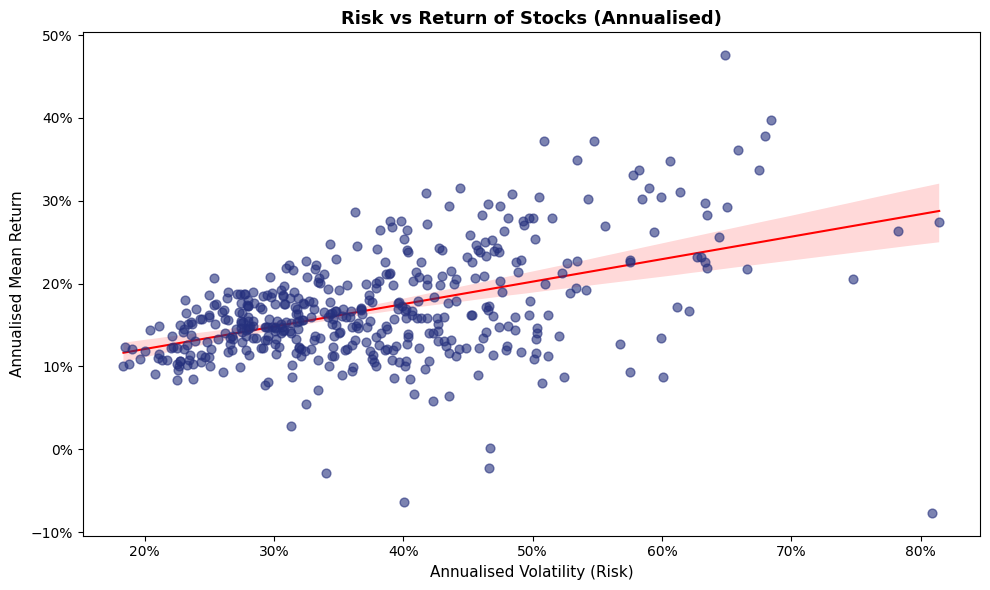

In [ ]:
# Annualise using empirical trading days
trading_days_per_year = returns.shape[0] / ((returns.index[-1] - returns.index[0]).days / 365.25)

mean_returns_annual = returns.mean() * trading_days_per_year
vol_annual = returns.std() * np.sqrt(trading_days_per_year)

# Apply mask on annualised values
mask = (vol_annual < 1.0) & (mean_returns_annual < 1.0)

fig, ax = plt.subplots(figsize=(10, 6))

# Dark blue scatter points
ax.scatter(vol_annual[mask], mean_returns_annual[mask],
           color="#25307D", alpha=0.6, s=40, zorder=3)

# Regression line only (no scatter from regplot)
sns.regplot(x=vol_annual[mask], y=mean_returns_annual[mask],
            ax=ax,
            scatter=False,           # don't plot dots again
            color="red",
            line_kws={"linewidth": 1.5},
            ci=95)

ax.set_xlabel("Annualised Volatility (Risk)", fontsize=11)
ax.set_ylabel("Annualised Mean Return", fontsize=11)
ax.set_title("Risk vs Return of Stocks (Annualised)", fontsize=13, fontweight="bold")

# Format axes as percentages
import matplotlib.ticker as mtick
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))

plt.tight_layout()
plt.savefig("risk_return_annualised.png", dpi=150, bbox_inches="tight")
plt.show()

Interpretation:

Most stocks are concentrated within a relatively narrow range of daily mean returns and volatility. While some higher-risk stocks achieve higher returns, the relationship is not perfectly linear, indicating that greater risk does not always guarantee proportionally greater return.

###2.6 Industry performance

In [ ]:

warnings.filterwarnings('ignore')

# Also suppress yfinance's own warnings:
import logging
logging.getLogger('yfinance').setLevel(logging.ERROR)

# ─ CONFIG ────────────────────────────────────────────
DATE_COLUMN      = "Date"                      # <- the date/index column name
OUTPUT_LOOKUP    = "classified_equities.csv"   # ticker -> sector lookup
OUTPUT_ANNOTATED = "original_with_sectors.csv" # original + sector row

# Get your free API key at https://www.openfigi.com/user/signup
# With a key: 250 requests/min, batch size 100
# Without a key: 5 requests/min, batch size 10
OPENFIGI_API_KEY = "1d0170e7-3d21-4511-aa12-2753950fa247"   # <- paste your key here, e.g. "abc123xyz..."

YAHOO_DELAY      = 0.5
YAHOO_RETRIES    = 3
# ─────────────────────────────────────────────

# Rate limit settings ─ automatically adjusted based on whether you have a key
if OPENFIGI_API_KEY:
    FIGI_BATCH_SIZE  = 100   # max allowed with API key
    FIGI_DELAY       = 0.5   # 250 req/min with key ─ very fast
    FIGI_RETRY_DELAY = 15.0
else:
    FIGI_BATCH_SIZE  = 5     # safe batch size without key
    FIGI_DELAY       = 12.0  # ~5 req/min without key
FIGI_MAX_RETRIES = 5

OPENFIGI_URL = "https://api.openfigi.com/v3/mapping"

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
log = logging.getLogger(__name__)

# ─ 11 GICS sector mapping ───────────────────────────────────
YAHOO_TO_GICS = {
    "technology":             "Information Technology",
    "financial services":     "Financials",
    "financial":              "Financials",
    "healthcare":             "Health Care",
    "health care":            "Health Care",
    "consumer cyclical":      "Consumer Discretionary",
    "consumer discretionary": "Consumer Discretionary",
    "communication services": "Communication Services",
    "industrials":            "Industrials",
    "consumer defensive":     "Consumer Staples",
    "consumer staples":       "Consumer Staples",
    "energy":                 "Energy",
    "utilities":              "Utilities",
    "real estate":            "Real Estate",
    "basic materials":        "Materials",
    "materials":              "Materials",
}
VALID_SECTORS = set(YAHOO_TO_GICS.values())


# ─ Step 1: Bloomberg code -> ticker via OpenFIGI ───────────────────

def extract_bloomberg_code(col_name: str) -> str:
    """'0376152D US Equity' -> '0376152D'"""
    return col_name.replace(" US Equity", "").replace(" Equity", "").strip()


def build_headers() -> dict:
    headers = {"Content-Type": "application/json"}
    if OPENFIGI_API_KEY:
        headers["X-OPENFIGI-APIKEY"] = OPENFIGI_API_KEY
    return headers


def batch_figi_lookup(codes: list) -> dict:
    """
    Send a batch of Bloomberg codes to OpenFIGI.
    Returns dict: { bloomberg_code: ticker_symbol or None }
    """
    # Try these in order - most specific first
    id_types_to_try = [
        # 8-character codes (like 0574018D) - try this FIRST
        {"idType": "ID_BB_8_CHR", "params": {"exchCode": "US"}},
        # Then try as ticker symbol directly
        {"idType": "TICKER", "params": {"exchCode": "US", "marketSecDes": "Equity"}},
        # Then try general Bloomberg ID
        {"idType": "ID_BB", "params": {"exchCode": "US", "marketSecDes": "Equity"}},
        # Last resort: global ID without restrictions
        {"idType": "ID_BB_GLOBAL", "params": {}},
    ]

    for config in id_types_to_try:
        id_type = config["idType"]
        extra_params = config["params"]

        payload = []
        for code in codes:
            request_item = {"idType": id_type, "idValue": code}
            request_item.update(extra_params)
            payload.append(request_item)

        for attempt in range(1, FIGI_MAX_RETRIES + 1):
            try:
                resp = requests.post(
                    OPENFIGI_URL,
                    json=payload,
                    headers=build_headers(),
                    timeout=20,
                )

                if resp.status_code == 429:
                    wait = FIGI_RETRY_DELAY * attempt
                    log.warning(
                        f"429 Too Many Requests (attempt {attempt}/{FIGI_MAX_RETRIES}). "
                        f"Waiting {wait:.0f}s... "
                        f"{'Tip: add a free API key to raise your limit!' if not OPENFIGI_API_KEY else ''}"
                    )
                    time.sleep(wait)
                    continue

                resp.raise_for_status()
                results = resp.json()
                break  # success ─ exit retry loop

            except requests.exceptions.RequestException as exc:
                log.warning(f"Network error attempt {attempt}: {exc}")
                time.sleep(FIGI_RETRY_DELAY)
                continue
        else:
            # All retries failed for this idType ─ continue to the next one
            log.warning(f"All retries failed for idType={id_type}.")
            continue

        # Parse results with better filtering
        mapping = {}
        any_found = False
        for code, result in zip(codes, results):
            if "error" in result:
                mapping[code] = None
                continue

            data = result.get("data", [])
            if not data:
                mapping[code] = None
                continue

            any_found = True
            ticker = None

            # Priority 1: Active US equity on major exchanges
            for entry in data:
                if (entry.get("exchCode") in ("US", "UN", "UQ", "UA", "UR") and
                    entry.get("marketSecDes") == "Equity" and
                    entry.get("securityType2") != "Defunct"):
                    ticker = entry.get("ticker")
                    break

            # Priority 2: Any US exchange
            if not ticker:
                for entry in data:
                    if entry.get("exchCode") in ("US", "UN", "UQ", "UA", "UR"):
                        ticker = entry.get("ticker")
                        break

            # Priority 3: First available ticker
            if not ticker:
                ticker = data[0].get("ticker")

            mapping[code] = ticker

        if any_found:
            return mapping

    # If no tickers found across all attempts
    return {code: None for code in codes}
def resolve_tickers(bloomberg_cols: list) -> dict:
    """
    Convert all Bloomberg column names to real tickers.
    Saves progress to figi_progress.csv after every batch ─ re-running
    the script will skip already-resolved codes automatically.
    Returns dict: { original_col_name: ticker or None }
    """
    PROGRESS_FILE = "figi_progress.csv"

    try:
        progress_df  = pd.read_csv(PROGRESS_FILE)
        already_done = dict(zip(progress_df["bloomberg_code"], progress_df["ticker"]))
        log.info(f"Resuming ─ {len(already_done)} codes already resolved from {PROGRESS_FILE}.")
    except FileNotFoundError:
        already_done = {}

    code_map     = {col: extract_bloomberg_code(col) for col in bloomberg_cols}
    unique_codes = list(set(code_map.values()))
    pending      = [c for c in unique_codes if c not in already_done]

    if OPENFIGI_API_KEY:
        log.info("API key detected ─ using high rate limit (250 req/min, batch size 100).")
    else:
        log.warning(
            "No API key set. Using free rate limit (5 req/min). "
            "Get a free key at https://www.openfigi.com/user/signup to run ~20x faster."
        )

    n_batches   = (len(pending) + FIGI_BATCH_SIZE - 1) // FIGI_BATCH_SIZE
    est_minutes = (n_batches * FIGI_DELAY) / 60
    log.info(
        f"{len(unique_codes)} total | {len(already_done)} cached | {len(pending)} to fetch. "
        f"Est. time: ~{est_minutes:.1f} min"
    )

    resolved_this_run = {}
    for i in tqdm(range(0, len(pending), FIGI_BATCH_SIZE),
                  desc="OpenFIGI lookup", unit="batch"):
        batch  = pending[i: i + FIGI_BATCH_SIZE]
        result = batch_figi_lookup(batch)
        resolved_this_run.update(result)

        # Save progress after every batch
        all_resolved = {**already_done, **resolved_this_run}
        pd.DataFrame(
            [{"bloomberg_code": k, "ticker": v} for k, v in all_resolved.items()]
        ).to_csv(PROGRESS_FILE, index=False)

        if i + FIGI_BATCH_SIZE < len(pending):
            time.sleep(FIGI_DELAY)

    already_done.update(resolved_this_run)

    col_to_ticker = {col: already_done.get(code) for col, code in code_map.items()}
    failed = [col for col, tk in col_to_ticker.items() if not tk]
    if failed:
        log.warning(f"{len(failed)} codes could not be resolved.")
    return col_to_ticker


# ─ Step 2: ticker -> GICS sector via yfinance ─────────────────────────────────

def normalise_sector(raw: str) -> str:
    if not raw:
        return "Unclassified"
    return YAHOO_TO_GICS.get(raw.strip().lower(), f"Other: {raw.strip()}")

def is_valid_ticker_format(ticker: str) -> bool:
    """Quick validation of ticker format"""
    if not ticker or ticker == "UNRESOLVED":
        return False
    if len(ticker) > 10:  # Suspiciously long
        return False
    # Add more validation as needed
    return True


def fetch_sector(ticker: str) -> dict:
    """Fetch sector info with better error handling"""
    # Clean ticker format - handle special cases
    clean_ticker = ticker.replace("/", ".")  # BRK/B → BRK.B

    for attempt in range(YAHOO_RETRIES + 1):
        try:
            stock = yf.Ticker(clean_ticker)
            info = stock.info

            # Check if we got valid data
            if not info or len(info) < 5:  # Too small = error response
                raise ValueError("Empty or invalid response")

            raw = info.get("sector", "") or ""
            return {
                "name":         info.get("longName", ""),
                "yahoo_sector": raw,
                "sector":       normalise_sector(raw),
                "industry":     info.get("industry", ""),
                "exchange":     info.get("exchange", ""),
            }

        except Exception as exc:
            if attempt < YAHOO_RETRIES:
                wait_time = 2.0 * (attempt + 1)  # Exponential backoff
                log.debug(f"[{ticker}] Attempt {attempt + 1} failed: {exc}. Retrying in {wait_time}s...")
                time.sleep(wait_time)
            else:
                log.warning(f"[{ticker}] All Yahoo lookup attempts failed: {type(exc).__name__}")
                return {
                    "name": "",
                    "yahoo_sector": "",
                    "sector": "Unclassified",
                    "industry": "",
                    "exchange": "",
                }

    # Fallback (should never reach here)
    return {
        "name": "", "yahoo_sector": "", "sector": "Unclassified",
        "industry": "", "exchange": "",
    }


# ─ Main ────────────────────────────────────────

def main(df_to_process: pd.DataFrame):
    log.info("Using the pre-processed DataFrame.")

    # The DATE_COLUMN is now the index after previous cleaning steps
    date_col = df_to_process.index.name

    # Exclude the index (Date) column when identifying Bloomberg columns
    bloomberg_cols = [c for c in df_to_process.columns if c != date_col]
    log.info(f"Found {len(bloomberg_cols)} Bloomberg-format columns in the provided DataFrame.")

    # Step 1: Bloomberg codes -> tickers
    col_to_ticker = resolve_tickers(bloomberg_cols)

    # Step 2: tickers -> GICS sectors
    log.info("Fetching sector data from Yahoo Finance ...")
    records = []
    for col, ticker in tqdm(col_to_ticker.items(), desc="Yahoo lookup", unit="ticker"):
      row = {
          "bloomberg_col":  col,
          "bloomberg_code": extract_bloomberg_code(col),
          "ticker":         ticker or "UNRESOLVED",
      }

      # Validate before attempting lookup
      if pd.notna(ticker) and isinstance(ticker, str) and is_valid_ticker_format(ticker):
          row.update(fetch_sector(ticker))
          time.sleep(YAHOO_DELAY)
      else:
          row.update({
              "name": "", "yahoo_sector": "", "sector": "Unclassified",
              "industry": "", "exchange": "",
          })
      records.append(row)

    lookup_df = pd.DataFrame(records)
    lookup_df.to_csv(OUTPUT_LOOKUP, index=False)
    log.info(f"Lookup table saved -> {OUTPUT_LOOKUP}")

    # Print resolved equities
    resolved_equities = lookup_df[lookup_df['ticker'] != 'UNRESOLVED']
    if not resolved_equities.empty:
        print("\n" + "=" * 56)
        print("  RESOLVED EQUITIES")
        print("=" * 56)
        display(resolved_equities[['bloomberg_col', 'ticker', 'sector', 'name']])
    else:
        print("\nNo equities were resolved to a ticker.")

    sector_map = dict(zip(lookup_df["bloomberg_col"], lookup_df["sector"]))

    # Prepare a Series with sectors, aligning with df_to_process columns
    sector_row_data = {col: sector_map.get(col, "Unclassified") for col in df_to_process.columns}
    # For this, we'll create a new DataFrame for annotation and concat
    sector_df = pd.DataFrame([sector_row_data], index=pd.Index(["SECTOR"], name="Annotation"))

    # Concatenate the sector DataFrame with the original df_to_process
    annotated = pd.concat([sector_df, df_to_process])
    annotated.to_csv(OUTPUT_ANNOTATED, index=False)
    log.info(f"Annotated original saved -> {OUTPUT_ANNOTATED}")

    # After your Yahoo lookup loop, check the failed ones:
    failed_yahoo = lookup_df[lookup_df['sector'] == 'Unclassified']
    unresolved_figi = lookup_df[lookup_df['ticker'] == 'UNRESOLVED']

    print("\n" + "=" * 56)
    print("  FAILURE ANALYSIS")
    print("=" * 56)
    print(f"  Failed at OpenFIGI stage:  {len(unresolved_figi)}")
    print(f"  Failed at Yahoo stage:     {len(failed_yahoo) - len(unresolved_figi)}")
    print(f"  Total Unclassified:        {len(failed_yahoo)}")

    if len(unresolved_figi) > 0:
        print("\n  Sample OpenFIGI failures (first 10):")
        print(unresolved_figi[['bloomberg_code', 'ticker']].head(10).to_string(index=False))

    yahoo_only_fails = failed_yahoo[failed_yahoo['ticker'] != 'UNRESOLVED']
    if len(yahoo_only_fails) > 0:
        print("\n  Sample Yahoo Finance failures (first 10):")
        print(yahoo_only_fails[['bloomberg_code', 'ticker', 'name']].head(10).to_string(index=False))

        # Check for patterns
        slash_tickers = yahoo_only_fails[yahoo_only_fails['ticker'].str.contains('/', na=False)]
        if len(slash_tickers) > 0:
            print(f"\n  ⚠️  Found {len(slash_tickers)} tickers with '/' character:")
            print("     " + ", ".join(slash_tickers['ticker'].head(10).tolist()))

    print("=" * 56 + "\n")
    # ═══════════════════════════════════════════════════════
    print("=" * 56 + "\n")
    counts = lookup_df ["sector"].value_counts()

    for sector in sorted (VALID_SECTORS):
        count = counts.get(sector, 0)
        print(f" {sector: <32} {count:>4} {'|' * (count // 3)}")

    print("=" * 56)
    print(f" Total processed: {len (lookup_df)}\n")

    return lookup_df


if __name__ == "__main__":
    # Pass the globally available 'df' to the main function
    # The 'df' in the global scope should already be cleaned by previous cells.
    lookup_df = main(df)


Yahoo lookup:  19%|█▉        | 87/453 [00:43<03:29,  1.74ticker/s]ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
Yahoo lookup:  70%|███████   | 319/453 [03:04<01:19,  1.69ticker/s]ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: PCH"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: PCH"}}}
ERROR:yfinance:HTTP E


  RESOLVED EQUITIES


,bloomberg_col,ticker,sector,name
1,AA US Equity,AA,Materials,Alcoa Corporation
2,AAPL US Equity,AAPL,Information Technology,Apple Inc.
5,ABT US Equity,ABT,Health Care,Abbott Laboratories
6,ABX US Equity,ABX,Financials,"Abacus Global Management, Inc."
7,ADBE US Equity,ADBE,Information Technology,Adobe Inc.
...,...,...,...,...
445,XEL US Equity,XEL,Utilities,Xcel Energy Inc.
448,XOM US Equity,XOM,Energy,Exxon Mobil Corporation
449,XRAY US Equity,XRAY,Health Care,DENTSPLY SIRONA Inc.
450,XRX US Equity,XRX,Industrials,Xerox Holdings Corporation



  FAILURE ANALYSIS
  Failed at OpenFIGI stage:  100
  Failed at Yahoo stage:     10
  Total Unclassified:        110

  Sample OpenFIGI failures (first 10):
bloomberg_code     ticker
      1436513D UNRESOLVED
           ABC UNRESOLVED
          ABMD UNRESOLVED
           AGN UNRESOLVED
           AKS UNRESOLVED
          ALXN UNRESOLVED
          ANDV UNRESOLVED
          ATGE UNRESOLVED
          ATVI UNRESOLVED
           AVP UNRESOLVED

  Sample Yahoo Finance failures (first 10):
bloomberg_code ticker                                                  name
          BBBY   BBBY                               Bed Bath & Beyond, Inc.
          BF/B   BF/B                                                      
           CMA    CMA                                                      
           CSC    CSC                           CSC Collective Holdings Ltd
           EMC    EMC          Global X Emerging Markets Great Consumer ETF
          FISV   FISV                                  

In [ ]:

print("\n--- Unclassified Equities Details ---")
unclassified_details = lookup_df[lookup_df['sector'] == 'Unclassified']
print(f"Total Unclassified: {len(unclassified_details)}")
display(unclassified_details.head())

print("\n--- Breakdown of Yahoo lookup failures ---")
failed_yahoo_lookup = lookup_df[lookup_df['sector'] == 'Unclassified']
# You might want to add more sophisticated filtering if 'Unclassified' is also used for OpenFIGI failures
# For now, let's assume 'Unclassified' coming from fetch_sector implies Yahoo failure if ticker is not 'UNRESOLVED'

# Let's inspect some of the tickers that couldn't be resolved by Yahoo Finance
problematic_tickers = failed_yahoo_lookup[failed_yahoo_lookup['ticker'] != 'UNRESOLVED']['ticker'].unique()
print(f"Sample of problematic tickers (Yahoo): {problematic_tickers[:10]}")



--- Unclassified Equities Details ---
Total Unclassified: 110


,bloomberg_col,bloomberg_code,ticker,name,yahoo_sector,sector,industry,exchange
0,1436513D US Equity,1436513D,UNRESOLVED,,,Unclassified,,
3,ABC US Equity,ABC,UNRESOLVED,,,Unclassified,,
4,ABMD US Equity,ABMD,UNRESOLVED,,,Unclassified,,
15,AGN US Equity,AGN,UNRESOLVED,,,Unclassified,,
19,AKS US Equity,AKS,UNRESOLVED,,,Unclassified,,



--- Breakdown of Yahoo lookup failures ---
Sample of problematic tickers (Yahoo): ['BBBY' 'BF/B' 'CMA' 'CSC' 'EMC' 'FISV' 'PCH' 'SPLS' 'TGNA' 'UTX']


In [ ]:
import os

progress_file = "figi_progress.csv"
if os.path.exists(progress_file):
    os.remove(progress_file)
    print(f"Removed {progress_file} to force re-lookup.")
else:
    print(f"{progress_file} not found, no need to remove.")

Removed figi_progress.csv to force re-lookup.


  CREATING INDUSTRY-BASED ANALYSIS

Working with 353 resolved equities across 12 sectors
  Communication Services               10 equities
  Consumer Discretionary               49 equities
  Consumer Staples                     29 equities
  Energy                               20 equities
  Financials                           46 equities
  Health Care                          38 equities
  Industrials                          56 equities
  Information Technology               34 equities
  Materials                            20 equities
  Real Estate                          18 equities
  Unclassified                         10 equities
  Utilities                            23 equities

  CALCULATING INDUSTRY AVERAGES

Created time series from 1993-09-07 00:00:00 to 2019-07-31 00:00:00
Total trading days: 9459

  INDUSTRY PERFORMANCE STATISTICS

Industry                            Start    End      Growth %     Volatility  
--------------------------------------------------------

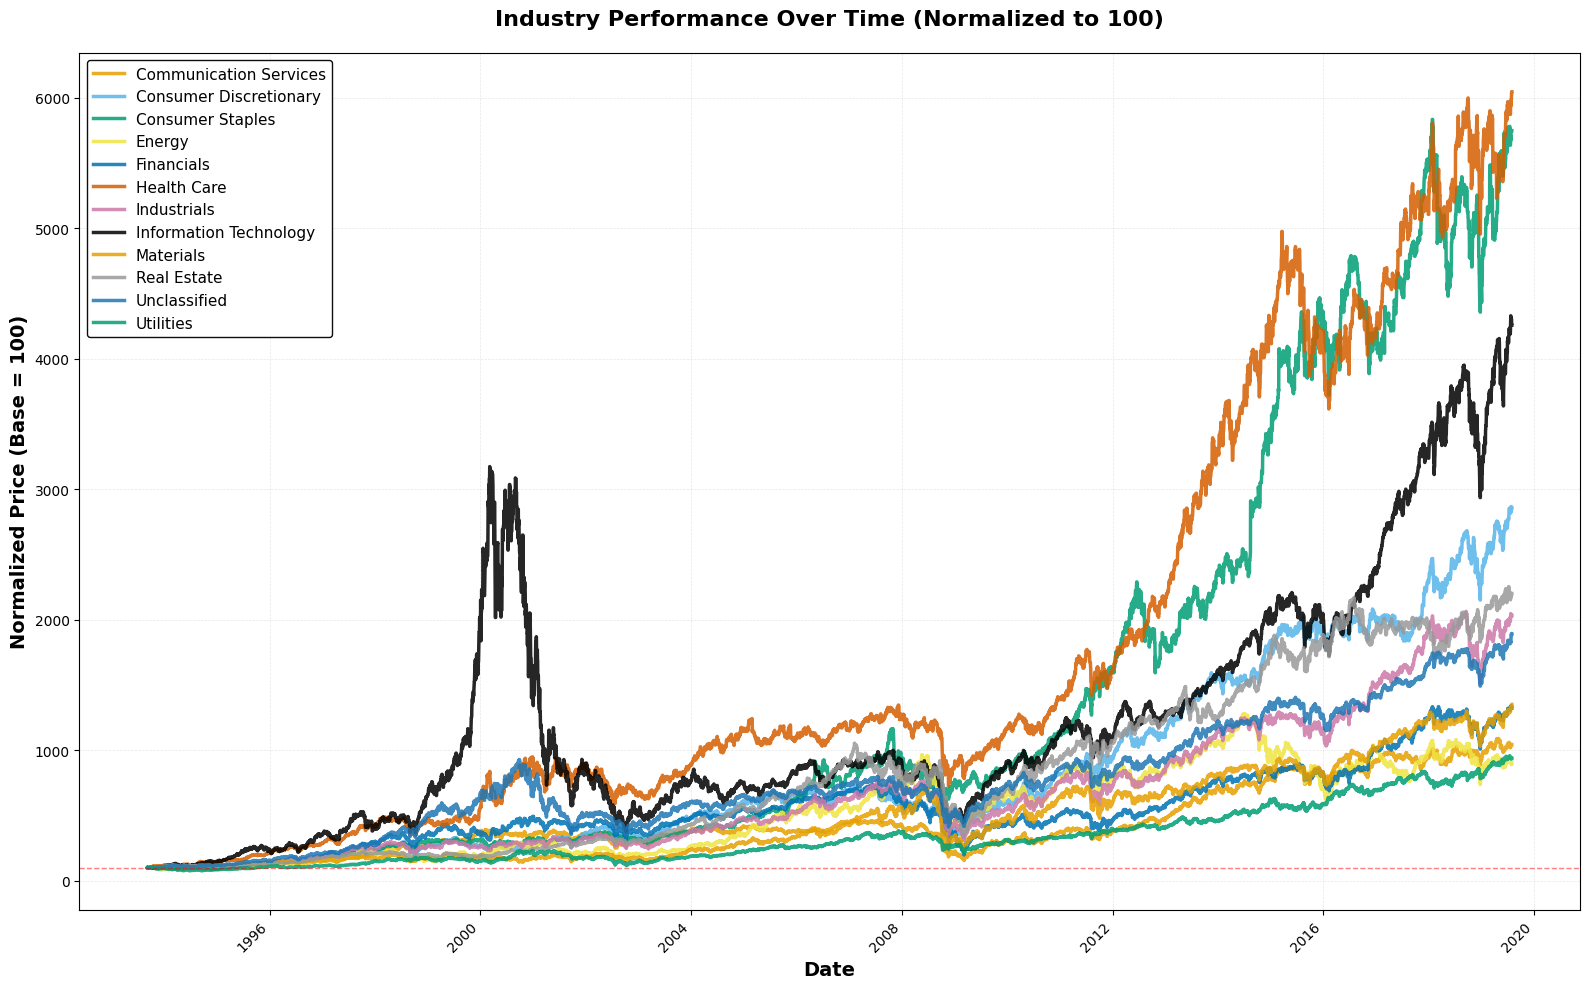


✓ Industry averages saved to 'industry_averages_normalized.csv'

  ANALYSIS COMPLETE!

Outputs created:
  1. industry_trends.png - Combined line graph
  2. industry_averages_normalized.csv - Time series data
  3. In-memory variables:
     - industry_data: Original prices by sector
     - industry_normalized: Normalized prices by sector
     - industry_averages: Average normalized price per sector
     - stats_df: Performance statistics


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

def create_industry_analysis(df_original, lookup_df):
    """
    Create industry-based dataframes and visualize trends over time.

    Parameters:
    - df_original: Your original DataFrame with Date index and Bloomberg columns
    - lookup_df: The classified_equities.csv output with sector mappings

    Returns:
    - industry_data: Dictionary of DataFrames, one per industry
    - industry_averages: DataFrame with average prices per industry over time
    """

    print("="*60)
    print("  CREATING INDUSTRY-BASED ANALYSIS")
    print("="*60)

    # Filter only resolved equities
    resolved = lookup_df[lookup_df['ticker'] != 'UNRESOLVED'].copy()
    print(f"\nWorking with {len(resolved)} resolved equities across {resolved['sector'].nunique()} sectors")

    # Create mapping: bloomberg_col -> sector
    col_to_sector = dict(zip(resolved['bloomberg_col'], resolved['sector']))

    # Initialize dictionary to store industry dataframes
    industry_data = {}
    industry_normalized = {}

    # Group columns by sector
    for sector in sorted(resolved['sector'].unique()):
        # Get all columns for this sector
        sector_cols = resolved[resolved['sector'] == sector]['bloomberg_col'].tolist()

        # Extract data for this sector
        sector_df = df_original[sector_cols].copy()

        # Store original data
        industry_data[sector] = sector_df

        # Normalize each column (standardize to base 100 at first date)
        # This allows fair comparison across different price ranges
        normalized_df = sector_df.copy()
        for col in sector_df.columns:
            first_valid = sector_df[col].first_valid_index()
            if first_valid is not None:
                base_value = sector_df.loc[first_valid, col]
                if base_value != 0 and not np.isnan(base_value):
                    normalized_df[col] = (sector_df[col] / base_value) * 100

        industry_normalized[sector] = normalized_df

        print(f"  {sector:<35} {len(sector_cols):>3} equities")

    print("\n" + "="*60)
    print("  CALCULATING INDUSTRY AVERAGES")
    print("="*60)

    # Calculate average normalized price for each industry over time
    industry_averages = pd.DataFrame(index=df_original.index)

    for sector, norm_df in industry_normalized.items():
        # Calculate mean across all equities in this sector for each date
        # Use nanmean to ignore NaN values
        industry_averages[sector] = norm_df.mean(axis=1)

    print(f"\nCreated time series from {industry_averages.index.min()} to {industry_averages.index.max()}")
    print(f"Total trading days: {len(industry_averages)}")

    return industry_data, industry_normalized, industry_averages


def plot_industry_trends(industry_averages, title="Industry Performance Over Time (Normalized to 100)"):
    """
    Plot all industries on a single line graph.

    Parameters:
    - industry_averages: DataFrame with Date index and industry columns
    """

    # Set up the plot with larger figure size
    fig, ax = plt.subplots(figsize=(16, 10))

    # Define colors for each sector (using a colorblind-friendly palette)
    colors = {
        'Communication Services': '#E69F00',    # Orange
        'Consumer Discretionary': '#56B4E9',    # Sky Blue
        'Consumer Staples': '#009E73',          # Bluish Green
        'Energy': '#F0E442',                     # Yellow
        'Financials': '#0072B2',                 # Blue
        'Health Care': '#D55E00',                # Vermillion
        'Industrials': '#CC79A7',                # Reddish Purple
        'Information Technology': '#000000',     # Black
        'Materials': '#E69F00',                  # Orange (lighter)
        'Real Estate': '#999999',                # Gray
        'Utilities': '#009E73'                   # Green (darker)
    }

    # Plot each industry
    for sector in industry_averages.columns:
        ax.plot(
            industry_averages.index,
            industry_averages[sector],
            label=sector,
            linewidth=2.5,
            color=colors.get(sector, None),
            alpha=0.85
        )

    # Formatting
    ax.set_xlabel('Date', fontsize=14, fontweight='bold')
    ax.set_ylabel('Normalized Price (Base = 100)', fontsize=14, fontweight='bold')
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)

    # Grid
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax.set_axisbelow(True)

    # Legend
    ax.legend(
        loc='upper left',
        fontsize=11,
        framealpha=0.95,
        edgecolor='black',
        ncol=1
    )

    # Add horizontal reference line at 100
    ax.axhline(y=100, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Base (100)')

    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')

    # Tight layout
    plt.tight_layout()

    # Save the figure
    plt.savefig('industry_trends.png', dpi=300, bbox_inches='tight')
    print("\n✓ Plot saved as 'industry_trends.png'")

    plt.show()

    return fig, ax


def get_industry_statistics(industry_averages):
    """
    Calculate and display statistics for each industry.
    """
    print("\n" + "="*80)
    print("  INDUSTRY PERFORMANCE STATISTICS")
    print("="*80)
    print(f"\n{'Industry':<35} {'Start':<8} {'End':<8} {'Growth %':<12} {'Volatility':<12}")
    print("-"*80)

    stats = []
    for sector in industry_averages.columns:
        series = industry_averages[sector].dropna()
        if len(series) > 0:
            start_val = series.iloc[0]
            end_val = series.iloc[-1]
            growth_pct = ((end_val - start_val) / start_val) * 100
            volatility = series.std()

            stats.append({
                'Industry': sector,
                'Start': start_val,
                'End': end_val,
                'Growth %': growth_pct,
                'Volatility': volatility
            })

            print(f"{sector:<35} {start_val:>7.1f} {end_val:>7.1f} {growth_pct:>11.1f}% {volatility:>11.2f}")

    print("="*80)

    # Convert to DataFrame for further analysis
    stats_df = pd.DataFrame(stats)

    # Rank by growth
    print("\n" + "="*60)
    print("  TOP PERFORMERS (by Growth %)")
    print("="*60)
    top_performers = stats_df.nlargest(5, 'Growth %')[['Industry', 'Growth %']]
    for idx, row in top_performers.iterrows():
        print(f"  {row['Industry']:<40} {row['Growth %']:>8.1f}%")

    return stats_df


def plot_industry_trends_separate(industry_averages):
    """
    Create separate subplots for each industry (alternative visualization).
    """
    n_industries = len(industry_averages.columns)
    n_cols = 3
    n_rows = (n_industries + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
    axes = axes.flatten()

    for idx, sector in enumerate(industry_averages.columns):
        ax = axes[idx]
        ax.plot(industry_averages.index, industry_averages[sector], linewidth=2)
        ax.set_title(sector, fontweight='bold', fontsize=12)
        ax.grid(True, alpha=0.3)
        ax.axhline(y=100, color='red', linestyle='--', linewidth=1, alpha=0.5)
        ax.set_ylabel('Normalized Price')

        # Rotate x-axis labels
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha('right')

    # Hide extra subplots
    for idx in range(n_industries, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig('industry_trends_separate.png', dpi=300, bbox_inches='tight')
    print("✓ Separate plots saved as 'industry_trends_separate.png'")
    plt.show()

    return fig, axes


# ═══════════════════════════════════════════════════════════════
# MAIN EXECUTION
# ═══════════════════════════════════════════════════════════════

# Step 1: Create industry analysis
industry_data, industry_normalized, industry_averages = create_industry_analysis(df, lookup_df)

# Step 2: Get statistics
stats_df = get_industry_statistics(industry_averages)

# Step 3: Plot all industries together
fig, ax = plot_industry_trends(industry_averages)

# Optional Step 4: Plot each industry separately
# Uncomment the line below if you want individual plots too
# plot_industry_trends_separate(industry_averages)

# Step 5: Save the industry averages data
industry_averages.to_csv('industry_averages_normalized.csv')
print("\n✓ Industry averages saved to 'industry_averages_normalized.csv'")

print("\n" + "="*60)
print("  ANALYSIS COMPLETE!")
print("="*60)
print(f"\nOutputs created:")
print(f"  1. industry_trends.png - Combined line graph")
print(f"  2. industry_averages_normalized.csv - Time series data")
print(f"  3. In-memory variables:")
print(f"     - industry_data: Original prices by sector")
print(f"     - industry_normalized: Normalized prices by sector")
print(f"     - industry_averages: Average normalized price per sector")
print(f"     - stats_df: Performance statistics")

###Data Visualisation:
1. General Trend:
    * Equities from all industries have shown positive growth over 16 years.
    * Health Care, Consumer Staples, Information Technology and Consumer Discretionary were leading industries from 1993 to 2018.
    * Global Financial Crisis/ 2008 Financial Crisis:
       * Mainly due to housing bubble & subprime loans,toxic assets (MBS), market collapse,Lehman Brothers & Bailouts.

2. Industry-specific Trends:

     1. IT Industry:
        * The Dot-com Bubble (The "New Economy" Regime)
          
          * IT equuities rose since 1998 then peaked during 2000 and plummeted afterwards until 2002
          * Mainly due to the euphoria around the Internet and technology, high capital availability and easy IPOs, media and investor hype.
           * Bubble burst during March 2000, due to the failure of companies to deliver profit, increase of interest rates, panic selling by big-tech companies and capital drying up.


    







               INDUSTRY CORRELATION ANALYSIS              
  CALCULATING INDUSTRY CORRELATIONS

Calculated correlations using 9459 data points
Date range: 1993-09-07 00:00:00 to 2013-01-01 00:00:00

✓ Correlation heatmap saved as 'industry_correlation_heatmap.png'


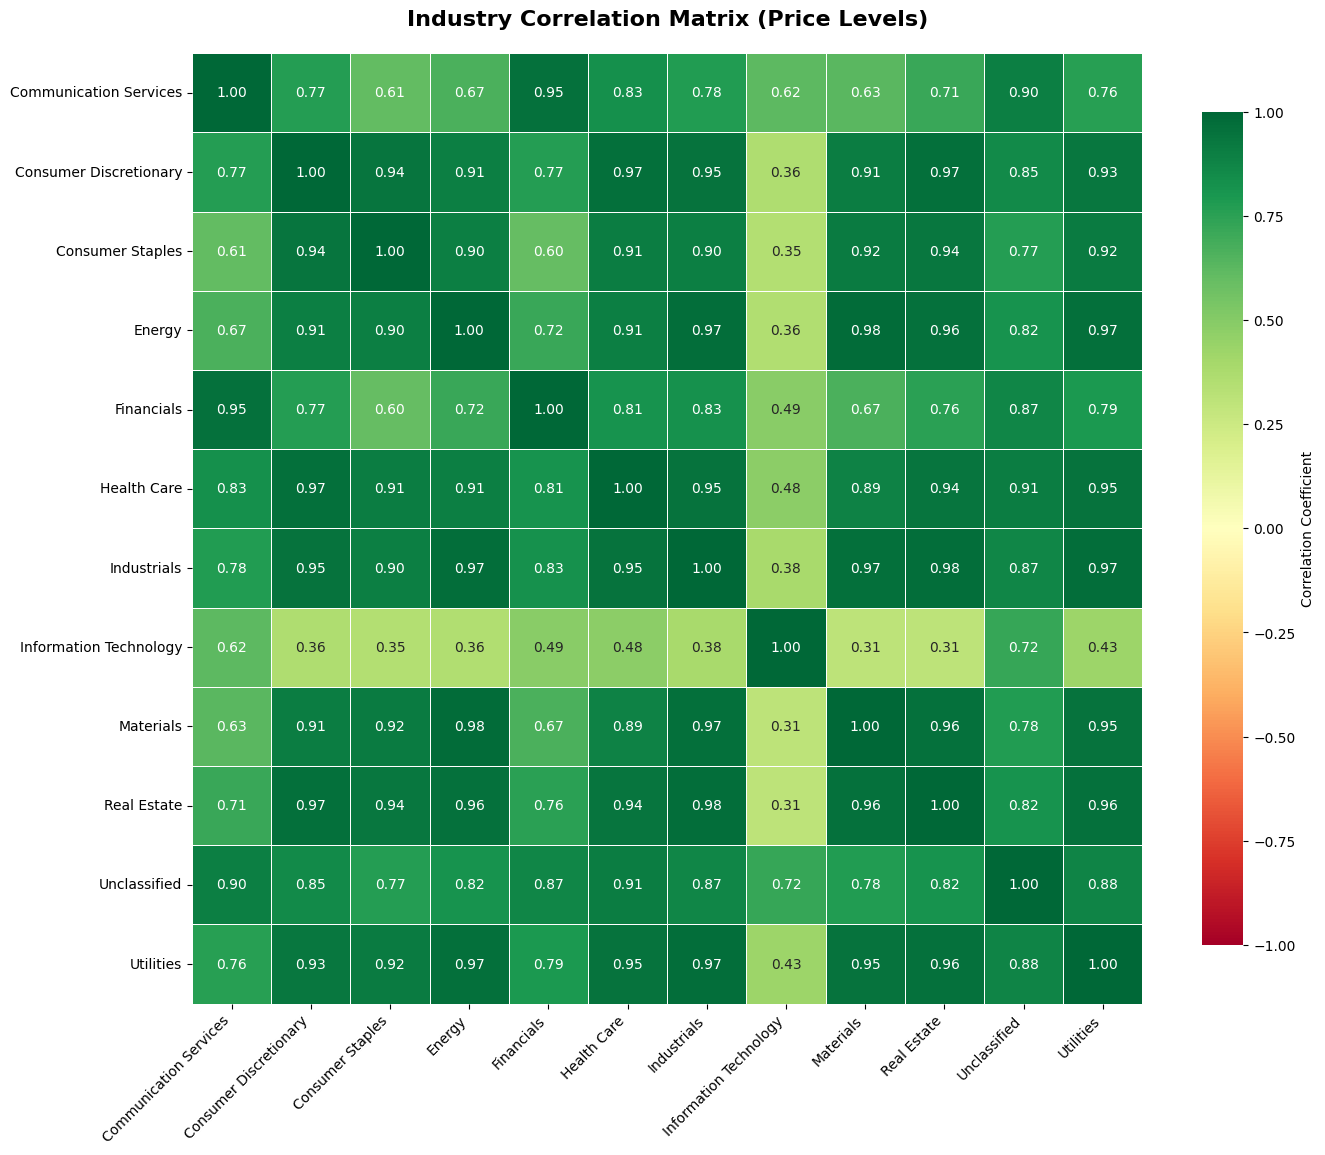

✓ Comparison heatmap saved as 'industry_correlation_comparison.png'


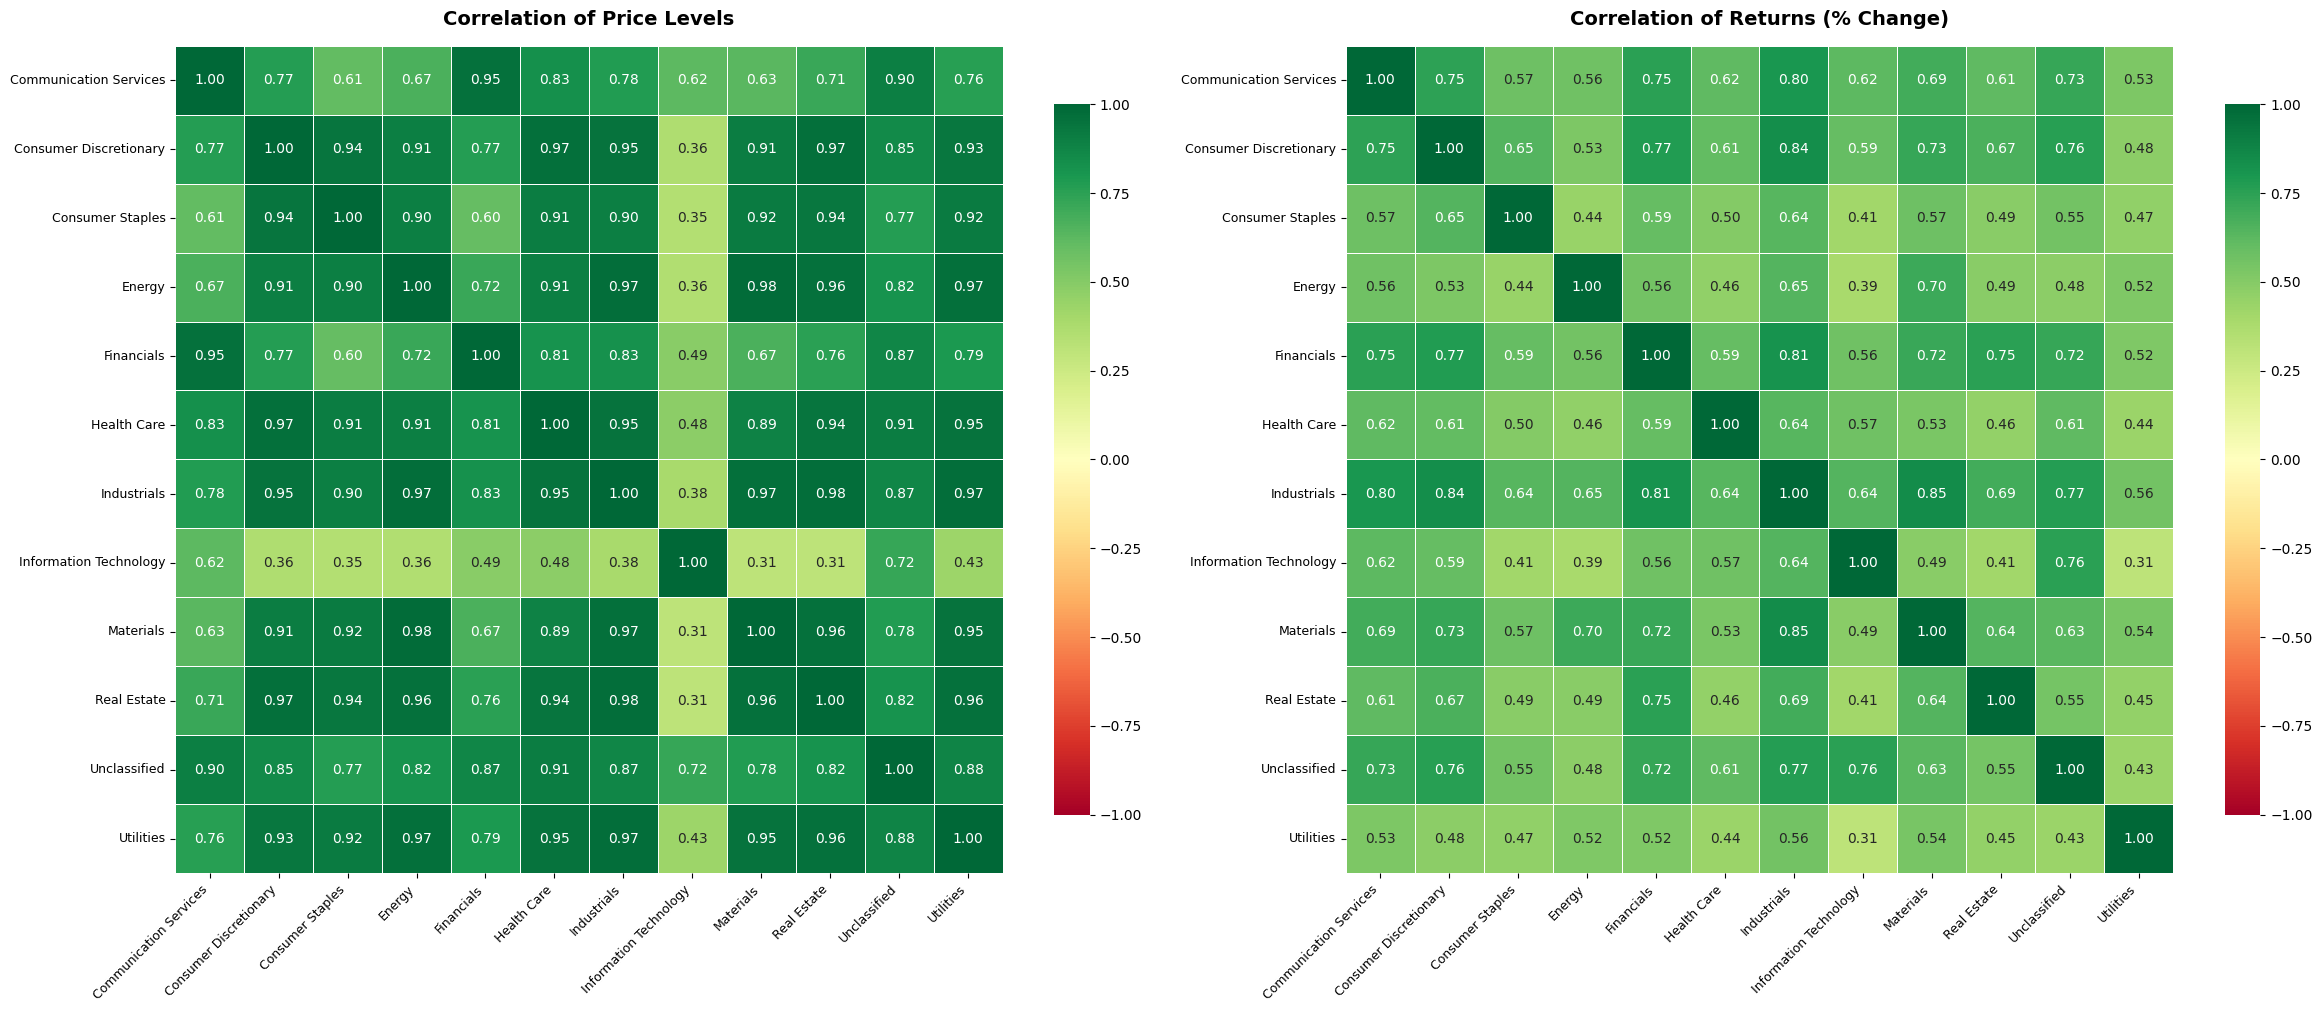


  CORRELATION INSIGHTS

┌─ MOST POSITIVELY CORRELATED INDUSTRIES (Price Levels) ─────────┐
Industry 1                     Industry 2                      Correlation
──────────────────────────────────────────────────────────────────────────
Energy                         Materials                            0.984
Industrials                    Real Estate                          0.976
Industrials                    Utilities                            0.973
Energy                         Industrials                          0.972
Consumer Discretionary         Health Care                          0.968
Consumer Discretionary         Real Estate                          0.967
Energy                         Utilities                            0.967
Industrials                    Materials                            0.966
Real Estate                    Utilities                            0.960
Materials                      Real Estate                          0.960
└─────────────────

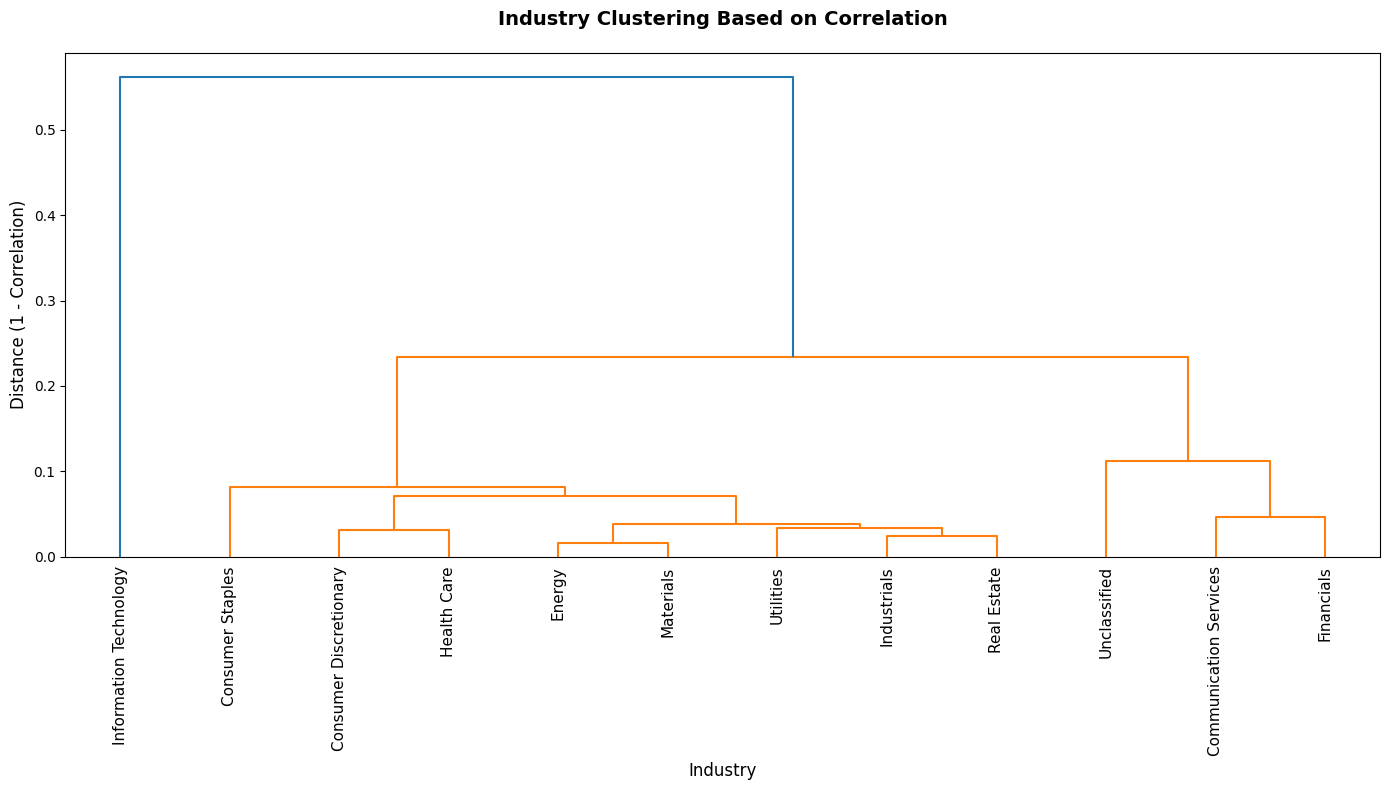

'\nprint("\n" + "="*60)\nprint("  ALL CORRELATION ANALYSES COMPLETE!")\nprint("="*60)\nprint("\nFiles created:")\nprint("  1. industry_correlation_heatmap.png")\nprint("  2. industry_correlation_comparison.png")\nprint("  3. industry_clustering.png")\nprint("  4. industry_correlation_matrix.csv")\nprint("  5. industry_returns_correlation_matrix.csv")\nprint("  6. industry_correlation_pairs.csv")\nprint("\nVariables created:")\nprint("  - correlation_matrix: Price level correlations")\nprint("  - returns_correlation: Returns correlations")\nprint("  - corr_pairs: All pairwise correlations")\nprint("  - avg_corr: Average correlation per industry")\nprint("="*60 + "\n")\n'

In [ ]:

def calculate_industry_correlations(industry_averages,start_date, end_date):
    """
    Calculate correlation matrix between industries.

    Parameters:
    - industry_averages: DataFrame with Date index and industry columns
    - start_date: Start date for analysis
    - end_date: End date for analysis

    Returns:
    - correlation_matrix: DataFrame with correlation coefficients
    - returns_correlation: DataFrame with correlation based on returns (not levels)
    """

    print("="*60)
    print("  CALCULATING INDUSTRY CORRELATIONS")
    print("="*60)

    filtered_industry_averages = industry_averages.loc[start_date:end_date]

    # Method 1: Correlation of price levels
    correlation_matrix = filtered_industry_averages.corr()

    # Method 2: Correlation of returns (more meaningful for financial analysis)
    # Calculate daily/periodic returns
    returns = filtered_industry_averages.pct_change().dropna()
    returns_correlation = returns.corr()

    print(f"\nCalculated correlations using {len(industry_averages)} data points")
    print(f"Date range: {filtered_industry_averages.index.min()} to {filtered_industry_averages.index.max()}")

    return correlation_matrix, returns_correlation, returns


def plot_correlation_heatmap(correlation_matrix, title="Industry Correlation Matrix",
                             filename="industry_correlation_heatmap.png"):
    """
    Create a beautiful heatmap of industry correlations.
    """

    fig, ax = plt.subplots(figsize=(14, 12))

    # Create heatmap
    sns.heatmap(
        correlation_matrix,
        annot=True,           # Show correlation values
        fmt='.2f',            # 2 decimal places
        cmap='RdYlGn',        # Red (negative) -> Yellow (neutral) -> Green (positive)
        center=0,             # Center colormap at 0
        square=True,          # Square cells
        linewidths=0.5,       # Lines between cells
        cbar_kws={
            "shrink": 0.8,
            "label": "Correlation Coefficient"
        },
        vmin=-1,              # Correlation ranges from -1 to 1
        vmax=1,
        ax=ax
    )

    # Formatting
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)

    # Rotate labels
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(rotation=0, fontsize=10)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"\n✓ Correlation heatmap saved as '{filename}'")
    plt.show()

    return fig, ax


def plot_correlation_heatmap_advanced(correlation_matrix, returns_correlation):
    """
    Create side-by-side comparison of price correlation vs returns correlation.
    """

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10))

    # Plot 1: Price levels correlation
    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt='.2f',
        cmap='RdYlGn',
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        vmin=-1,
        vmax=1,
        ax=ax1
    )
    ax1.set_title('Correlation of Price Levels', fontsize=14, fontweight='bold', pad=15)
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=9)

    # Plot 2: Returns correlation
    sns.heatmap(
        returns_correlation,
        annot=True,
        fmt='.2f',
        cmap='RdYlGn',
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        vmin=-1,
        vmax=1,
        ax=ax2
    )
    ax2.set_title('Correlation of Returns (% Change)', fontsize=14, fontweight='bold', pad=15)
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0, fontsize=9)

    plt.tight_layout()
    plt.savefig('industry_correlation_comparison.png', dpi=300, bbox_inches='tight')
    print("✓ Comparison heatmap saved as 'industry_correlation_comparison.png'")
    plt.show()

    return fig, (ax1, ax2)


def analyze_correlation_insights(correlation_matrix, returns_correlation):
    """
    Extract and display key insights from correlation analysis.
    """

    print("\n" + "="*80)
    print("  CORRELATION INSIGHTS")
    print("="*80)

    # Get upper triangle (avoid duplicates)
    mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

    # Extract correlations
    correlations = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i+1, len(correlation_matrix.columns)):
            correlations.append({
                'Industry 1': correlation_matrix.columns[i],
                'Industry 2': correlation_matrix.columns[j],
                'Price Correlation': correlation_matrix.iloc[i, j],
                'Returns Correlation': returns_correlation.iloc[i, j]
            })

    corr_df = pd.DataFrame(correlations)

    # 1. HIGHEST CORRELATIONS
    print("\n┌─ MOST POSITIVELY CORRELATED INDUSTRIES (Price Levels) ─────────┐")
    print(f"{'Industry 1':<30} {'Industry 2':<30} {'Correlation':>12}")
    print("─"*74)
    top_corr = corr_df.nlargest(10, 'Price Correlation')
    for _, row in top_corr.iterrows():
        print(f"{row['Industry 1']:<30} {row['Industry 2']:<30} {row['Price Correlation']:>11.3f}")
    print("└" + "─"*73 + "┘")

    # 2. LOWEST CORRELATIONS (most diversified)
    print("\n┌─ LEAST CORRELATED INDUSTRIES (Best for Diversification) ───────┐")
    print(f"{'Industry 1':<30} {'Industry 2':<30} {'Correlation':>12}")
    print("─"*74)
    bottom_corr = corr_df.nsmallest(10, 'Price Correlation')
    for _, row in bottom_corr.iterrows():
        print(f"{row['Industry 1']:<30} {row['Industry 2']:<30} {row['Price Correlation']:>11.3f}")
    print("└" + "─"*73 + "┘")

    # 3. RETURNS CORRELATION ANALYSIS
    print("\n┌─ MOST POSITIVELY CORRELATED (Returns) ─────────────────────────┐")
    print(f"{'Industry 1':<30} {'Industry 2':<30} {'Correlation':>12}")
    print("─"*74)
    top_ret_corr = corr_df.nlargest(10, 'Returns Correlation')
    for _, row in top_ret_corr.iterrows():
        print(f"{row['Industry 1']:<30} {row['Industry 2']:<30} {row['Returns Correlation']:>11.3f}")
    print("└" + "─"*73 + "┘")

    # 4. AVERAGE CORRELATION PER INDUSTRY
    print("\n┌─ AVERAGE CORRELATION WITH OTHER INDUSTRIES ─────────────────────┐")
    print(f"{'Industry':<40} {'Avg Price Corr':>15} {'Avg Return Corr':>15}")
    print("─"*72)

    avg_correlations = []
    for industry in correlation_matrix.columns:
        # Get correlations with all other industries (exclude self)
        price_corrs = correlation_matrix[industry].drop(industry)
        return_corrs = returns_correlation[industry].drop(industry)

        avg_correlations.append({
            'Industry': industry,
            'Avg Price Correlation': price_corrs.mean(),
            'Avg Return Correlation': return_corrs.mean()
        })

    avg_corr_df = pd.DataFrame(avg_correlations).sort_values('Avg Price Correlation', ascending=False)

    for _, row in avg_corr_df.iterrows():
        print(f"{row['Industry']:<40} {row['Avg Price Correlation']:>14.3f} {row['Avg Return Correlation']:>14.3f}")
    print("└" + "─"*71 + "┘")

    # 5. SUMMARY STATISTICS
    print("\n┌─ SUMMARY STATISTICS ────────────────────────────────────────────┐")
    print(f"  Overall average correlation (prices):  {corr_df['Price Correlation'].mean():>6.3f}")
    print(f"  Overall average correlation (returns): {corr_df['Returns Correlation'].mean():>6.3f}")
    print(f"  Highest correlation:                   {corr_df['Price Correlation'].max():>6.3f}")
    print(f"  Lowest correlation:                    {corr_df['Price Correlation'].min():>6.3f}")
    print(f"  Standard deviation:                    {corr_df['Price Correlation'].std():>6.3f}")
    print("└" + "─"*67 + "┘")

    return corr_df, avg_corr_df



def plot_correlation_clusters(correlation_matrix):
    """
    Use hierarchical clustering to group similar industries.
    """
    from scipy.cluster.hierarchy import dendrogram, linkage
    from scipy.spatial.distance import squareform

    # Convert correlation to distance
    distance_matrix = 1 - correlation_matrix

    # Perform hierarchical clustering
    condensed_dist = squareform(distance_matrix)
    linkage_matrix = linkage(condensed_dist, method='average')

    # Plot dendrogram
    fig, ax = plt.subplots(figsize=(14, 8))

    dendrogram(
        linkage_matrix,
        labels=correlation_matrix.columns,
        leaf_rotation=90,
        leaf_font_size=11,
        ax=ax
    )

    ax.set_title('Industry Clustering Based on Correlation',
                 fontsize=14, fontweight='bold', pad=20)
    ax.set_ylabel('Distance (1 - Correlation)', fontsize=12)
    ax.set_xlabel('Industry', fontsize=12)

    plt.tight_layout()
    plt.savefig('industry_clustering.png', dpi=300, bbox_inches='tight')
    print("✓ Clustering dendrogram saved as 'industry_clustering.png'")
    plt.show()

    return fig, ax


# ═══════════════════════════════════════════════════════════════
# MAIN EXECUTION
# ═══════════════════════════════════════════════════════════════


print("  INDUSTRY CORRELATION ANALYSIS".center(58))

# Step 1: Calculate correlations
correlation_matrix, returns_correlation, returns = calculate_industry_correlations(industry_averages,start_date='1993-09-07', end_date='2013-01-01')

# Step 2: Create basic heatmap
plot_correlation_heatmap(
    correlation_matrix,
    title="Industry Correlation Matrix (Price Levels)",
    filename="industry_correlation_heatmap.png"
)

# Step 3: Create comparison heatmap (price vs returns)
plot_correlation_heatmap_advanced(correlation_matrix, returns_correlation)

# Step 4: Analyze and display insights
corr_pairs, avg_corr = analyze_correlation_insights(correlation_matrix, returns_correlation)

# Step 5: Create clustering dendrogram
plot_correlation_clusters(correlation_matrix)

# Step 6: Save correlation data to CSV
correlation_matrix.to_csv('industry_correlation_matrix.csv')
returns_correlation.to_csv('industry_returns_correlation_matrix.csv')
corr_pairs.to_csv('industry_correlation_pairs.csv', index=False)

"""
print("\n" + "="*60)
print("  ALL CORRELATION ANALYSES COMPLETE!")
print("="*60)
print("\nFiles created:")
print("  1. industry_correlation_heatmap.png")
print("  2. industry_correlation_comparison.png")
print("  3. industry_clustering.png")
print("  4. industry_correlation_matrix.csv")
print("  5. industry_returns_correlation_matrix.csv")
print("  6. industry_correlation_pairs.csv")
print("\nVariables created:")
print("  - correlation_matrix: Price level correlations")
print("  - returns_correlation: Returns correlations")
print("  - corr_pairs: All pairwise correlations")
print("  - avg_corr: Average correlation per industry")
print("="*60 + "\n")
"""

# 3. Portfolio Construction
### **Research Question:** How do different portfolio construction strategies compare in terms of return, risk, and Sharpe ratio?

# 3.1 Minimum variance portfolio

## MVP Stock Screening

This section calculates annualized expected return and volatility for each stock during the training period. The MVP candidate pool keeps stocks with annualized volatility below the selected threshold and expected annual return of at least 6%.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Global settings
TRAIN_START = '1993-09-07'
TRAIN_END = '2013-01-01'
TEST_START = '2013-01-02'
TEST_END = '2019-07-31'

INITIAL_CAPITAL = 100000
VOLATILITY_THRESHOLD = 25
MINIMUM_RETURN = 6
MAX_STOCK_WEIGHT = 0.10
MAX_SECTOR_WEIGHT = 0.30

In [ ]:
def calculate_stock_metrics_for_mvp(df_original, lookup_df):
    """Calculate expected annual return and annualized volatility for each stock."""

    resolved = lookup_df[lookup_df['ticker'] != 'UNRESOLVED'].copy()
    metrics = []

    for _, row in resolved.iterrows():
        bloomberg_col = row['bloomberg_col']
        sector = row['sector']
        ticker = row['ticker']

        if bloomberg_col in df_original.columns:
            prices = df_original[bloomberg_col].dropna()

            if len(prices) > 1:
                returns = prices.pct_change().dropna()

                if len(returns) > 0 and (returns + 1).prod() > 0:
                    geometric_mean = (returns + 1).prod() ** (252 / len(returns)) - 1
                    geometric_mean_pct = geometric_mean * 100
                else:
                    geometric_mean_pct = np.nan

                std_dev = returns.std() * np.sqrt(252) * 100

                metrics.append({
                    'bloomberg_col': bloomberg_col,
                    'ticker': ticker,
                    'sector': sector,
                    'name': row['name'],
                    'expected_return_%': geometric_mean_pct,
                    'volatility_%': std_dev
                })

    metrics_df = pd.DataFrame(metrics)
    metrics_df = metrics_df.dropna(subset=['expected_return_%', 'volatility_%'])

    return metrics_df


def plot_mvp_risk_return_scatterplot(metrics_df, volatility_threshold=25, minimum_return=6):
    """Create a risk-return scatterplot for stock screening."""

    fig, ax = plt.subplots(figsize=(16, 10))

    for sector in metrics_df['sector'].unique():
        sector_data = metrics_df[metrics_df['sector'] == sector]
        ax.scatter(
            sector_data['volatility_%'],
            sector_data['expected_return_%'],
            label=sector,
            alpha=0.6,
            s=70,
            edgecolors='black',
            linewidth=0.4
        )

    ax.axhline(
        y=minimum_return,
        color='red',
        linestyle='--',
        linewidth=1.5,
        alpha=0.7,
        label=f'Minimum Expected Return: {minimum_return}%'
    )

    ax.axvline(
        x=volatility_threshold,
        color='blue',
        linestyle='--',
        linewidth=1.5,
        alpha=0.7,
        label=f'Volatility Screening Threshold: {volatility_threshold}%'
    )

    ax.set_xlabel('Annualized Volatility (%)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Expected Annual Return (%)', fontsize=12, fontweight='bold')
    ax.set_title('MVP Stock Screening: Risk-Return Profile by Sector', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)

    plt.tight_layout()
    plt.savefig('mvp_risk_return_scatterplot.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, ax

def get_mvp_candidate_stocks_by_sector(metrics_df, volatility_threshold=25, minimum_return=6, top_n=10):
    """Select low-risk MVP candidate stocks by sector."""

    filtered = metrics_df[
        (metrics_df['volatility_%'] < volatility_threshold) &
        (metrics_df['expected_return_%'] >= minimum_return)
    ].copy()

    results = {}

    for sector in sorted(filtered['sector'].unique()):
        sector_stocks = filtered[filtered['sector'] == sector].copy()
        sector_stocks = sector_stocks.sort_values('volatility_%', ascending=True)
        results[sector] = sector_stocks.head(top_n)

    return results


def create_mvp_summary_statistics(metrics_df, candidate_stocks_dict, volatility_threshold=25, minimum_return=6):
    """Create sector-level summary statistics for MVP screening."""

    summary = []

    for sector in sorted(metrics_df['sector'].unique()):
        sector_data = metrics_df[metrics_df['sector'] == sector]

        candidate_data = sector_data[
            (sector_data['volatility_%'] < volatility_threshold) &
            (sector_data['expected_return_%'] >= minimum_return)
        ]

        if len(candidate_data) > 0:
            lowest_risk_stock = candidate_data.nsmallest(1, 'volatility_%')
            best_low_risk_ticker = lowest_risk_stock['ticker'].values[0]
            best_low_risk_vol = lowest_risk_stock['volatility_%'].values[0]
            best_low_risk_return = lowest_risk_stock['expected_return_%'].values[0]
        else:
            best_low_risk_ticker = 'N/A'
            best_low_risk_vol = np.nan
            best_low_risk_return = np.nan

        summary.append({
            'Sector': sector,
            'Total Stocks': len(sector_data),
            'MVP Candidate Stocks': len(candidate_data),
            'Lowest Risk Candidate': best_low_risk_ticker,
            'Candidate Return %': best_low_risk_return,
            'Candidate Volatility %': best_low_risk_vol
        })

    return pd.DataFrame(summary)


def display_mvp_candidate_stocks(candidate_stocks_dict, volatility_threshold=25, minimum_return=6):
    """Display MVP candidate stocks by sector."""

    print("\n" + "="*110)
    print("MVP CANDIDATE STOCKS BY SECTOR")
    print("="*110)
    print(f"Selection rule: volatility < {volatility_threshold}%, expected return >= {minimum_return}%")
    print("Ranked by lowest volatility")

    for sector in sorted(candidate_stocks_dict.keys()):
        stocks = candidate_stocks_dict[sector]

        if len(stocks) == 0:
            print(f"\n{sector}: No suitable stocks found")
            continue

        print(f"\n{sector} ({len(stocks)} stocks)")
        print("-"*110)
        print(f"{'Rank':<6} {'Ticker':<12} {'Name':<35} {'Expected Return %':<20} {'Volatility %':<15}")
        print("-"*110)

        for rank, (_, row) in enumerate(stocks.iterrows(), 1):
            print(
                f"{rank:<6} "
                f"{row['ticker']:<12} "
                f"{row['name'][:34]:<35} "
                f"{row['expected_return_%']:>17.2f} "
                f"{row['volatility_%']:>15.2f}"
            )

    print("="*110)


Calculating MVP stock metrics...
Calculated metrics for 353 stocks across 12 sectors


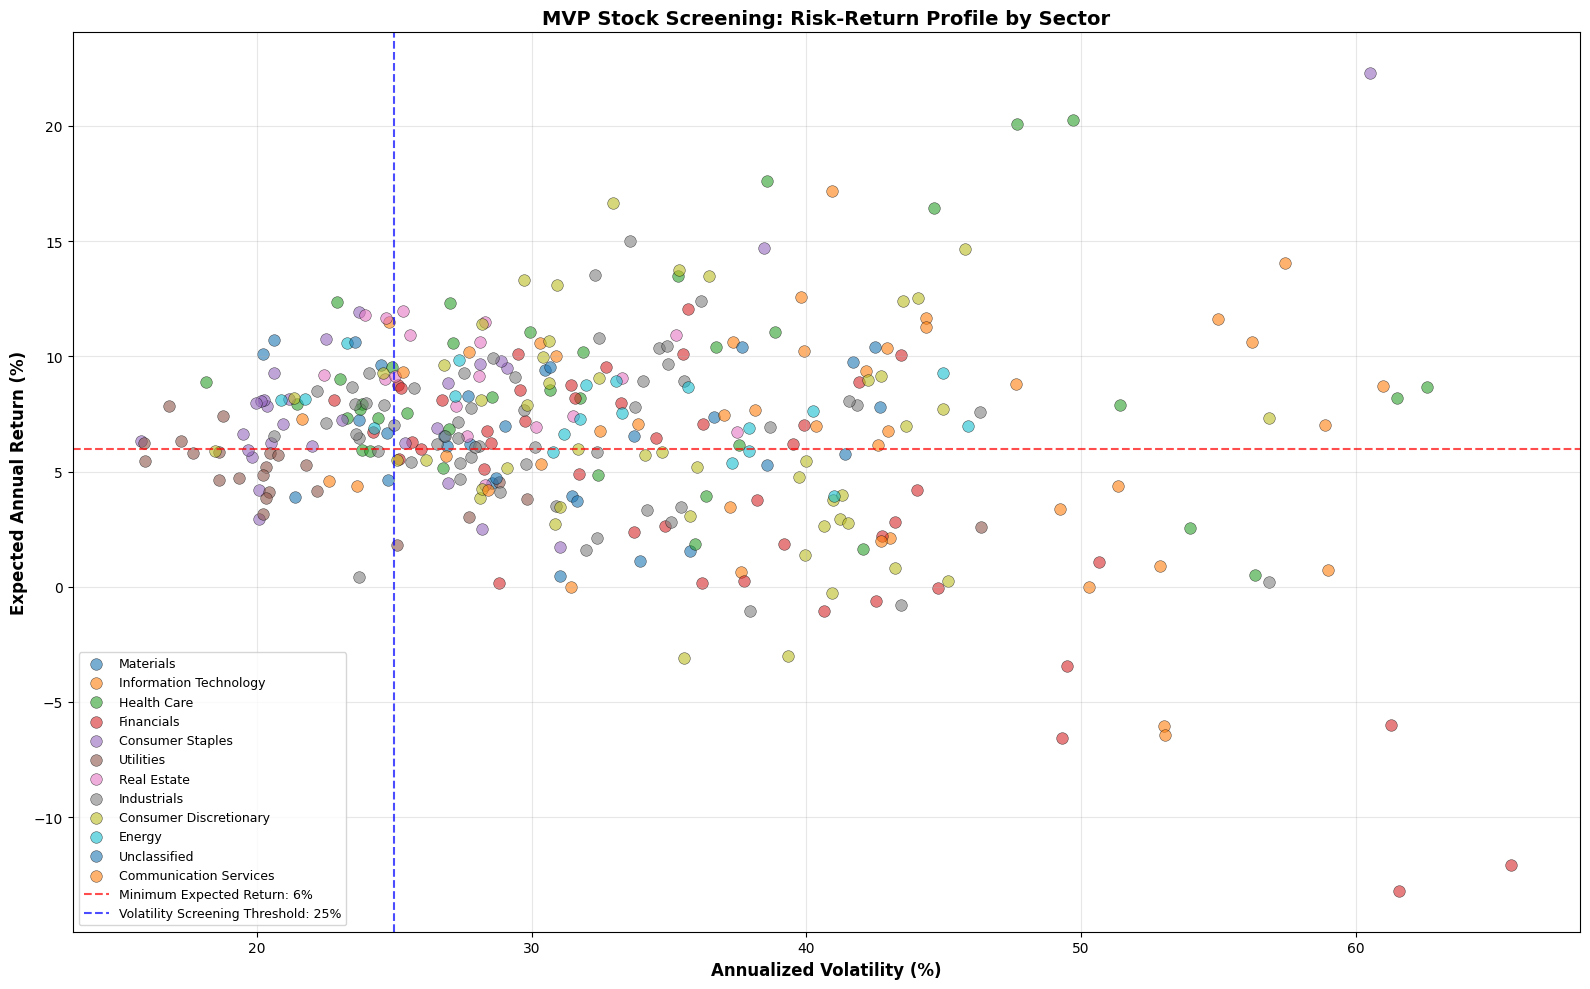


MVP CANDIDATE STOCKS BY SECTOR
Selection rule: volatility < 25%, expected return >= 6%
Ranked by lowest volatility

Consumer Discretionary (2 stocks)
--------------------------------------------------------------------------------------------------------------
Rank   Ticker       Name                                Expected Return %    Volatility %   
--------------------------------------------------------------------------------------------------------------
1      MCD          McDonald's Corporation                           8.17           21.35
2      VFC          V.F. Corporation                                 9.27           24.59

Consumer Staples (10 stocks)
--------------------------------------------------------------------------------------------------------------
Rank   Ticker       Name                                Expected Return %    Volatility %   
--------------------------------------------------------------------------------------------------------------
1      GI

,Sector,Total Stocks,MVP Candidate Stocks,Lowest Risk Candidate,Candidate Return %,Candidate Volatility %
0,Communication Services,10,0,N/A,NaN,NaN
1,Consumer Discretionary,49,2,MCD,8.172111,21.347305
2,Consumer Staples,29,14,GIS,6.311782,15.772766
3,Energy,20,4,XOM,8.087211,20.860275
4,Financials,46,2,AJG,8.092115,22.789540
5,Health Care,38,9,JNJ,8.872613,18.154362
6,Industrials,56,11,MMM,6.525019,20.626874
7,Information Technology,34,2,ADP,7.279684,21.632435
8,Materials,20,4,ECL,10.729416,20.612621
9,Real Estate,18,4,WELL,9.203652,22.434282


In [ ]:
# Training period for stock screening
df_train = df.loc[TRAIN_START:TRAIN_END].copy()

print('Calculating MVP stock metrics...')
mvp_metrics_df = calculate_stock_metrics_for_mvp(df_train, lookup_df)

print(f"Calculated metrics for {len(mvp_metrics_df)} stocks across {mvp_metrics_df['sector'].nunique()} sectors")

plot_mvp_risk_return_scatterplot(
    mvp_metrics_df,
    volatility_threshold=VOLATILITY_THRESHOLD,
    minimum_return=MINIMUM_RETURN
)

mvp_candidate_stocks_dict = get_mvp_candidate_stocks_by_sector(
    mvp_metrics_df,
    volatility_threshold=VOLATILITY_THRESHOLD,
    minimum_return=MINIMUM_RETURN,
    top_n=10
)

display_mvp_candidate_stocks(
    mvp_candidate_stocks_dict,
    volatility_threshold=VOLATILITY_THRESHOLD,
    minimum_return=MINIMUM_RETURN
)

mvp_summary_df = create_mvp_summary_statistics(
    mvp_metrics_df,
    mvp_candidate_stocks_dict,
    volatility_threshold=VOLATILITY_THRESHOLD,
    minimum_return=MINIMUM_RETURN
)

display(mvp_summary_df)

mvp_metrics_df.to_csv('mvp_stock_risk_return_metrics.csv', index=False)
mvp_summary_df.to_csv('mvp_stock_screening_summary.csv', index=False)


## MVP Portfolio Size Optimisation

This section tests different candidate portfolio sizes from 10 to 29 stocks. For each size, the optimiser minimises portfolio variance subject to the constraints. The final MVP size is selected by the lowest feasible annualized volatility.

In [ ]:
from scipy.optimize import minimize

# ═══════════════════════════════════════════════════════════════
# PORTFOLIO SIZE OPTIMISATION
# ═══════════════════════════════════════════════════════════════

def select_mvp_candidate_stocks(metrics_df, n_stocks, volatility_threshold=25, minimum_return=6):
    """
    Select candidate stocks for MVP.

    For MVP, we do not select stocks mainly by highest return.
    Instead, we select lower-risk stocks that still meet the minimum return requirement.
    """

    # This version uses the original column names from your Max Sharpe code:
    # geometric_mean = expected annual return
    # std_dev = annualized volatility

    eligible = metrics_df[
        (metrics_df['std_dev'] < volatility_threshold) &
        (metrics_df['geometric_mean'] >= minimum_return)
    ].copy()

    # MVP focuses on risk minimisation, so sort by lowest volatility
    eligible = eligible.sort_values('std_dev', ascending=True)

    selected = eligible.head(n_stocks)

    return selected

def get_selected_returns(selected_stocks, df_original):
    """
    Create a daily returns DataFrame for selected stocks.
    """

    returns_data = {}

    for _, stock in selected_stocks.iterrows():

        bloomberg_col = stock['bloomberg_col']
        ticker = stock['ticker']

        if bloomberg_col in df_original.columns:

            prices = df_original[bloomberg_col].dropna()
            returns = prices.pct_change().dropna()

            returns_data[ticker] = returns

    returns_df = pd.DataFrame(returns_data)
    returns_df = returns_df.dropna()

    return returns_df

def portfolio_return(weights, expected_returns):
    """
    Calculate portfolio expected annual return.
    """

    return np.sum(weights * expected_returns)


def portfolio_variance(weights, covariance_matrix):
    """
    Calculate portfolio variance.

    MVP minimises this value.
    """

    return weights.T @ covariance_matrix @ weights


def portfolio_volatility(weights, covariance_matrix):
    """
    Calculate portfolio annualized volatility.
    """

    return np.sqrt(portfolio_variance(weights, covariance_matrix))

def optimise_mvp_weights(selected_stocks, df_original, minimum_return=0.06):
    """
    Optimise MVP weights for a selected group of stocks.

    Constraints:
    - weights sum to 1
    - min 1% allocation per stock
    - max 10% allocation per stock
    - max 30% allocation per sector
    - minimum expected annual return of 6%
    - long-only portfolio
    """

    returns_df = get_selected_returns(selected_stocks, df_original)

    if len(returns_df) == 0:
        return None

    n_assets = len(returns_df.columns)

    # Feasibility check: n * min_weight must not exceed 100%
    if n_assets * 0.01 > 1.0:
        return None

    # Expected annual return for each stock
    expected_returns = []

    for col in returns_df.columns:
        stock_returns = returns_df[col]
        geometric_return = (1 + stock_returns).prod() ** (252 / len(stock_returns)) - 1
        expected_returns.append(geometric_return)

    expected_returns = np.array(expected_returns)

    # Annualized covariance matrix
    covariance_matrix = returns_df.cov().values * 252

    # Initial equal weights
    initial_weights = np.ones(n_assets) / n_assets

    # ── CHANGED: min 1%, max 10% per stock ──────────────────
    bounds = tuple((0.01, 0.10) for _ in range(n_assets))

    # Constraint 1: weights sum to 1
    weight_constraint = {
        'type': 'eq',
        'fun': lambda w: np.sum(w) - 1
    }

    # Constraint 2: expected annual return >= 6%
    return_constraint = {
        'type': 'ineq',
        'fun': lambda w: portfolio_return(w, expected_returns) - minimum_return
    }

    # Constraint 3: max 30% per sector
    sector_constraints = []
    selected_sectors = selected_stocks.set_index('ticker').loc[
        returns_df.columns, 'sector'
    ].tolist()

    unique_sectors = sorted(set(selected_sectors))

    for sector in unique_sectors:
        sector_indices = [i for i, s in enumerate(selected_sectors) if s == sector]
        sector_constraint = {
            'type': 'ineq',
            'fun': lambda w, idx=sector_indices: 0.30 - np.sum(w[idx])
        }
        sector_constraints.append(sector_constraint)

    constraints = [weight_constraint, return_constraint] + sector_constraints

    # Optimise
    result = minimize(
        portfolio_variance,
        initial_weights,
        args=(covariance_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'maxiter': 1000}
    )

    if not result.success:
        return None

    mvp_weights = result.x
    mvp_return = portfolio_return(mvp_weights, expected_returns)
    mvp_volatility_val = portfolio_volatility(mvp_weights, covariance_matrix)
    mvp_sharpe = mvp_return / mvp_volatility_val if mvp_volatility_val > 0 else 0

    return {
        'weights':             mvp_weights,
        'expected_returns':    expected_returns,
        'covariance_matrix':   covariance_matrix,
        'returns_df':          returns_df,
        'portfolio_return':    mvp_return * 100,
        'portfolio_volatility': mvp_volatility_val * 100,
        'sharpe_ratio':        mvp_sharpe
    }

def optimise_mvp_portfolio_size(
    metrics_df,
    df_original,
    portfolio_sizes,
    volatility_threshold=25,
    minimum_return=6
):
    """
    Test different portfolio sizes and choose the portfolio with the lowest volatility.

    Feasible portfolios satisfy all MVP constraints.
    Infeasible portfolios are shown using diagnostic equal-weight results only.
    """

    results = []

    print("\n" + "="*110)
    print("MVP PORTFOLIO SIZE OPTIMISATION")
    print("="*110)

    print(
        f"{'N Stocks':<12} "
        f"{'Expected Return %':<22} "
        f"{'Portfolio Volatility %':<25} "
        f"{'Sharpe Ratio':<15} "
        f"{'Status':<30}"
    )

    print("-"*110)

    for n in portfolio_sizes:

        selected = select_mvp_candidate_stocks(
            metrics_df,
            n_stocks=n,
            volatility_threshold=volatility_threshold,
            minimum_return=minimum_return
        )

        if len(selected) < n:

            print(
                f"{n:<12} "
                f"{'N/A':<22} "
                f"{'N/A':<25} "
                f"{'N/A':<15} "
                f"{'Not enough eligible stocks':<30}"
            )

            continue

        mvp_result = optimise_mvp_weights(
            selected,
            df_original,
            minimum_return=minimum_return / 100
        )

        # Case 1: optimisation failed / infeasible
        if mvp_result is None:

            # Diagnostic only: calculate equal-weight return and volatility
            returns_df = get_selected_returns(selected, df_original)

            if len(returns_df) > 0:

                n_assets = len(returns_df.columns)
                equal_weights = np.ones(n_assets) / n_assets

                expected_returns = []

                for col in returns_df.columns:
                    stock_returns = returns_df[col]

                    geometric_return = (
                        (1 + stock_returns).prod()
                        ** (252 / len(stock_returns))
                        - 1
                    )

                    expected_returns.append(geometric_return)

                expected_returns = np.array(expected_returns)

                covariance_matrix = returns_df.cov().values * 252

                diagnostic_return = (
                    portfolio_return(equal_weights, expected_returns)
                    * 100
                )

                diagnostic_volatility = (
                    portfolio_volatility(equal_weights, covariance_matrix)
                    * 100
                )

                diagnostic_sharpe = (
                    diagnostic_return / diagnostic_volatility
                    if diagnostic_volatility > 0 else 0
                )

                print(
                    f"{n:<12} "
                    f"{diagnostic_return:>18.2f} "
                    f"{diagnostic_volatility:>23.2f} "
                    f"{diagnostic_sharpe:>14.3f} "
                    f"{'Infeasible*':<30}"
                )

                results.append({
                    'n_stocks': n,
                    'portfolio_return': diagnostic_return,
                    'portfolio_volatility': diagnostic_volatility,
                    'sharpe_ratio': diagnostic_sharpe,
                    'selected_stocks': selected,
                    'weights': equal_weights,
                    'returns_df': returns_df,
                    'status': 'Infeasible - diagnostic only'
                })

            else:

                print(
                    f"{n:<12} "
                    f"{'N/A':<22} "
                    f"{'N/A':<25} "
                    f"{'N/A':<15} "
                    f"{'Infeasible':<30}"
                )

            continue

        # Case 2: optimisation successful / feasible
        results.append({
            'n_stocks': n,
            'portfolio_return': mvp_result['portfolio_return'],
            'portfolio_volatility': mvp_result['portfolio_volatility'],
            'sharpe_ratio': mvp_result['sharpe_ratio'],
            'selected_stocks': selected,
            'weights': mvp_result['weights'],
            'returns_df': mvp_result['returns_df'],
            'status': 'Feasible'
        })

        print(
            f"{n:<12} "
            f"{mvp_result['portfolio_return']:>18.2f} "
            f"{mvp_result['portfolio_volatility']:>23.2f} "
            f"{mvp_result['sharpe_ratio']:>14.3f} "
            f"{'Feasible':<30}"
        )

    print("="*110)

    results_df = pd.DataFrame([
        {
            'n_stocks': r['n_stocks'],
            'portfolio_return': r['portfolio_return'],
            'portfolio_volatility': r['portfolio_volatility'],
            'sharpe_ratio': r['sharpe_ratio'],
            'status': r['status']
        }
        for r in results
    ])

    return results, results_df

def plot_mvp_size_optimisation_results(results_df):
    """
    Plot MVP portfolio size optimisation results.
    """

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Plot 1: Expected return
    ax1 = axes[0, 0]

    ax1.plot(
        results_df['n_stocks'],
        results_df['portfolio_return'],
        marker='o',
        linewidth=2,
        markersize=8
    )

    ax1.axhline(
        y=6,
        linestyle='--',
        alpha=0.6,
        label='Minimum Return: 6%'
    )

    ax1.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Expected Return (%)', fontsize=12, fontweight='bold')
    ax1.set_title('MVP Expected Return vs Portfolio Size', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    # Plot 2: Volatility
    ax2 = axes[0, 1]

    ax2.plot(
        results_df['n_stocks'],
        results_df['portfolio_volatility'],
        marker='o',
        linewidth=2,
        markersize=8
    )

    min_vol_idx = results_df['portfolio_volatility'].idxmin()
    min_vol_n = results_df.loc[min_vol_idx, 'n_stocks']
    min_vol_value = results_df.loc[min_vol_idx, 'portfolio_volatility']

    ax2.scatter(
        [min_vol_n],
        [min_vol_value],
        color='red',
        s=300,
        marker='*',
        edgecolors='black',
        linewidth=1.2,
        zorder=5,
        label=f'Min Volatility: {int(min_vol_n)} stocks'
    )

    ax2.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax2.set_title('MVP Volatility vs Portfolio Size', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    # Plot 3: Sharpe ratio
    ax3 = axes[1, 0]

    ax3.plot(
        results_df['n_stocks'],
        results_df['sharpe_ratio'],
        marker='o',
        linewidth=2,
        markersize=8
    )

    ax3.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Sharpe Ratio', fontsize=12, fontweight='bold')
    ax3.set_title('Sharpe Ratio vs Portfolio Size', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)

    # Plot 4: Return vs Volatility
    ax4 = axes[1, 1]

    scatter = ax4.scatter(
        results_df['portfolio_volatility'],
        results_df['portfolio_return'],
        c=results_df['n_stocks'],
        s=200,
        cmap='viridis',
        edgecolors='black',
        linewidth=1.5,
        alpha=0.8
    )

    for _, row in results_df.iterrows():

        ax4.annotate(
            f"{int(row['n_stocks'])}",
            (row['portfolio_volatility'], row['portfolio_return']),
            fontsize=10,
            ha='center',
            va='center',
            fontweight='bold'
        )
    ax4.scatter(
      [min_vol_value],
      [results_df.loc[min_vol_idx, 'portfolio_return']],
      color='red',
      s=300,
      marker='*',
      edgecolors='black',
      linewidth=1.2,
      zorder=5,
      label=f'MVP: {int(min_vol_n)} stocks'
    )

    ax4.set_xlabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Expected Return (%)', fontsize=12, fontweight='bold')
    ax4.set_title('MVP Trade-off', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, ax=ax4)
    cbar.set_label('Number of Stocks', fontsize=11, fontweight='bold')

    plt.tight_layout()

    plt.savefig(
        'mvp_portfolio_size_optimisation.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    return fig, axes


In [ ]:
def find_optimal_mvp_portfolio(results, results_df):
    """Choose the feasible portfolio with the minimum volatility."""

    print("\n" + "="*100)
    print("MVP OPTIMAL PORTFOLIO RECOMMENDATION")
    print("="*100)

    feasible_df = results_df[results_df['status'] == 'Feasible'].copy()

    if len(feasible_df) == 0:
        raise ValueError('No feasible MVP portfolios found.')

    min_vol_idx = feasible_df['portfolio_volatility'].idxmin()
    optimal_mvp = results_df.loc[min_vol_idx]

    print("\nMINIMUM VARIANCE PORTFOLIO:")
    print(f"   Optimal Candidate Stocks: {int(optimal_mvp['n_stocks'])}")
    print(f"   Expected Annual Return:   {optimal_mvp['portfolio_return']:.2f}%")
    print(f"   Portfolio Volatility:     {optimal_mvp['portfolio_volatility']:.2f}%")
    print(f"   Sharpe Ratio:             {optimal_mvp['sharpe_ratio']:.3f}")

    print("\n" + "="*100)
    print("RECOMMENDATION: Use the feasible portfolio with the LOWEST VOLATILITY")
    print(f"                ({int(optimal_mvp['n_stocks'])} candidate stocks)")
    print("="*100)

    optimal_result = results[min_vol_idx]

    optimal_stocks = optimal_result['selected_stocks'].copy()
    optimal_weights = optimal_result['weights']

    return optimal_stocks, optimal_weights, optimal_mvp


def display_optimal_mvp_portfolio(optimal_stocks, optimal_weights, initial_capital=100000):
    """Display the final MVP portfolio composition with positive weights only."""

    output_df = optimal_stocks.copy()
    output_df['weight'] = optimal_weights
    output_df['weight_%'] = output_df['weight'] * 100
    output_df['AUD_allocation'] = output_df['weight'] * initial_capital

    candidate_count = len(output_df)

    # Show only stocks that actually receive positive allocation
    output_df = output_df[output_df['weight'] > 1e-6].copy()
    output_df = output_df.sort_values('weight_%', ascending=False)

    print("\n" + "="*130)
    print("OPTIMAL MINIMUM VARIANCE PORTFOLIO COMPOSITION")
    print("="*130)
    print(f"Candidate stocks optimised: {candidate_count}")

    print("-"*130)

    print(
        f"{'Rank':<6} "
        f"{'Ticker':<12} "
        f"{'Sector':<30} "
        f"{'Name':<35} "
        f"{'Weight %':<12} "
        f"{'AUD Allocation':<18}"
    )
    print("-"*130)

    for rank, (_, stock) in enumerate(output_df.iterrows(), 1):
        print(
            f"{rank:<6} "
            f"{stock['ticker']:<12} "
            f"{stock['sector']:<30} "
            f"{stock['name'][:34]:<35} "
            f"{stock['weight_%']:>10.2f}% "
            f"AUD {stock['AUD_allocation']:>12,.2f}"
        )

    print("="*130)

    sector_allocation = (
        output_df
        .groupby('sector')['weight_%']
        .sum()
        .sort_values(ascending=False)
    )

    print("\nSECTOR ALLOCATION:")
    print("-"*70)

    for sector, weight in sector_allocation.items():
        print(f"  {sector:<40} {weight:>8.2f}%")

    print("-"*70)

    return output_df, sector_allocation


Original eligible stocks: 58
Reduced universe: 29 stocks

Stocks per sector:
sector
Consumer Staples          3
Energy                    3
Health Care               3
Utilities                 3
Industrials               3
Real Estate               3
Materials                 3
Consumer Discretionary    2
Financials                2
Information Technology    2
Unclassified              2
Name: count, dtype: int64
Starting MVP portfolio size optimisation...

MVP PORTFOLIO SIZE OPTIMISATION
N Stocks     Expected Return %      Portfolio Volatility %    Sharpe Ratio    Status                        
--------------------------------------------------------------------------------------------------------------
10                         7.75                   11.85          0.654 Feasible                      
11                         7.70                   11.83          0.651 Feasible                      
12                         7.65                   11.61          0.659 Feasible  

,n_stocks,portfolio_return,portfolio_volatility,sharpe_ratio,status
0,10,7.752007,11.850292,0.654162,Feasible
1,11,7.697524,11.831609,0.650590,Feasible
2,12,7.646949,11.606658,0.658842,Feasible
3,13,7.600522,11.557165,0.657646,Feasible
4,14,7.543731,11.522637,0.654688,Feasible
5,15,7.538860,11.521009,0.654358,Feasible
6,16,7.547700,11.470837,0.657990,Feasible
7,17,7.657130,11.335833,0.675480,Feasible
8,18,7.591853,11.261112,0.674165,Feasible
9,19,7.595405,11.134877,0.682127,Feasible


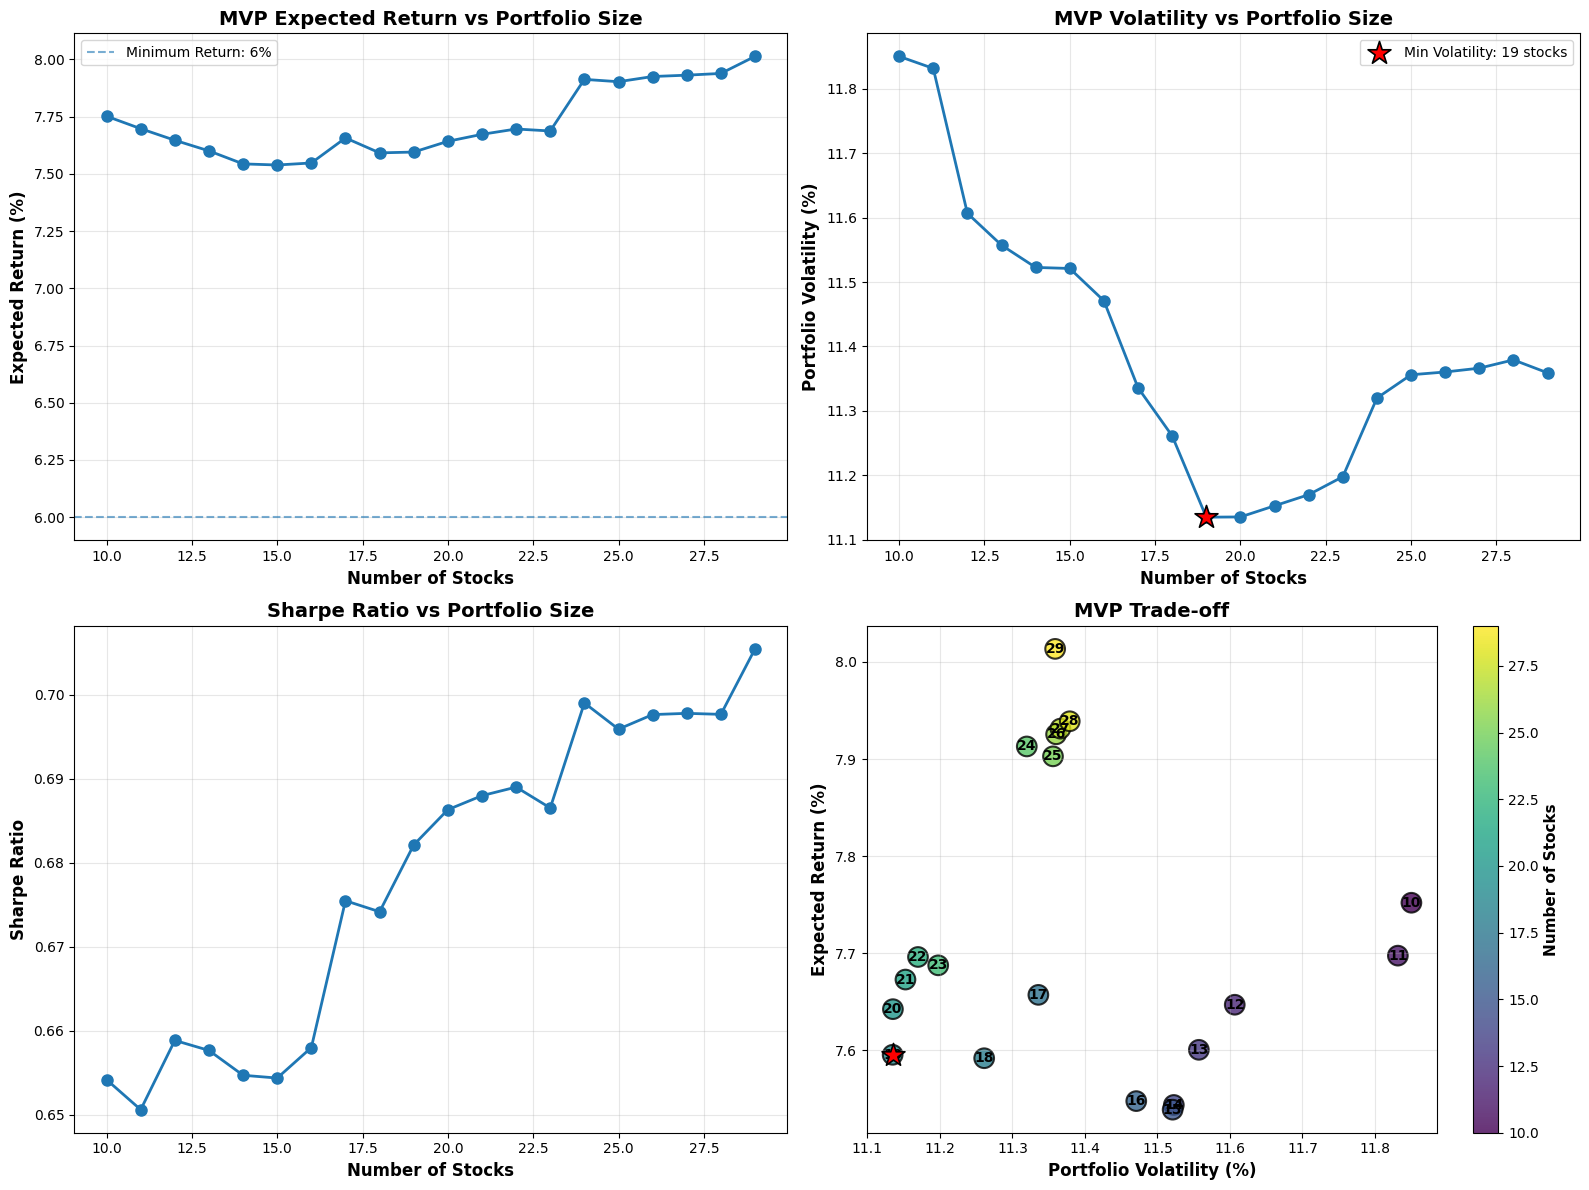

In [ ]:
# Rename metrics for optimisation without overwriting the original screening dataframe
mvp_metrics_for_optimisation = mvp_metrics_df.rename(columns={
    'expected_return_%': 'geometric_mean',
    'volatility_%': 'std_dev'
}).copy()

# Reduce universe after applying MVP screening rules
eligible_for_mvp = mvp_metrics_for_optimisation[
    (mvp_metrics_for_optimisation['std_dev'] < VOLATILITY_THRESHOLD) &
    (mvp_metrics_for_optimisation['geometric_mean'] >= MINIMUM_RETURN)
].copy()

# Reduce universe: keep top 3 lowest-volatility stocks per sector
mvp_metrics_for_optimisation_filtered = (
    eligible_for_mvp
    .sort_values(['sector', 'std_dev'])
    .groupby('sector')
    .head(3)
    .reset_index(drop=True)
)

print(f"Original eligible stocks: {len(eligible_for_mvp)}")
print(f"Reduced universe: {len(mvp_metrics_for_optimisation_filtered)} stocks")
print("\nStocks per sector:")
print(mvp_metrics_for_optimisation_filtered['sector'].value_counts())

# Portfolio sizes to test
max_n = len(mvp_metrics_for_optimisation_filtered)

portfolio_sizes = list(range(10, max_n + 1))

print('Starting MVP portfolio size optimisation...')

mvp_results, mvp_results_df = optimise_mvp_portfolio_size(
    mvp_metrics_for_optimisation_filtered,
    df_train,
    portfolio_sizes,
    volatility_threshold=VOLATILITY_THRESHOLD,
    minimum_return=MINIMUM_RETURN
)

display(mvp_results_df)

plot_mvp_size_optimisation_results(mvp_results_df)

mvp_results_df.to_csv('mvp_portfolio_size_optimisation_results.csv', index=False)


In [ ]:
optimal_mvp_stocks, optimal_mvp_weights, optimal_mvp_metrics = find_optimal_mvp_portfolio(
    mvp_results,
    mvp_results_df
)

mvp_portfolio_df, mvp_sector_allocation = display_optimal_mvp_portfolio(
    optimal_mvp_stocks,
    optimal_mvp_weights,
    initial_capital=INITIAL_CAPITAL
)

mvp_portfolio_df.to_csv('optimal_mvp_portfolio_composition.csv', index=False)
mvp_sector_allocation.to_csv('optimal_mvp_sector_allocation.csv')



MVP OPTIMAL PORTFOLIO RECOMMENDATION

MINIMUM VARIANCE PORTFOLIO:
   Optimal Candidate Stocks: 19
   Expected Annual Return:   7.60%
   Portfolio Volatility:     11.13%
   Sharpe Ratio:             0.682

RECOMMENDATION: Use the feasible portfolio with the LOWEST VOLATILITY
                (19 candidate stocks)

OPTIMAL MINIMUM VARIANCE PORTFOLIO COMPOSITION
Candidate stocks optimised: 19
----------------------------------------------------------------------------------------------------------------------------------
Rank   Ticker       Sector                         Name                                Weight %     AUD Allocation    
----------------------------------------------------------------------------------------------------------------------------------
1      GIS          Consumer Staples               General Mills, Inc.                      10.00% AUD    10,000.00
2      WEC          Utilities                      WEC Energy Group, Inc.                   10.00% AUD    10,0

## Equal-Weight Benchmark

This section creates an equal-weight benchmark using the same candidate stocks as the final MVP. The benchmark helps evaluate whether optimal MVP weights improve risk-adjusted performance compared with a simple equal allocation.

In [ ]:
def backtest_mvp_portfolio(portfolio_stocks, portfolio_weights, df_data, initial_investment, period_name=None):
    """Backtest a fixed-weight portfolio by buying shares at the first test-period price and holding them."""

    stock_cols = portfolio_stocks['bloomberg_col'].tolist()
    portfolio_prices = df_data[stock_cols].copy().dropna()

    portfolio_weights = np.array(portfolio_weights)
    dollar_allocations = initial_investment * portfolio_weights

    shares = {}

    for i, col in enumerate(stock_cols):
        first_price = portfolio_prices[col].iloc[0]
        shares[col] = dollar_allocations[i] / first_price

    portfolio_value = pd.DataFrame(index=portfolio_prices.index)

    for col in stock_cols:
        portfolio_value[col] = portfolio_prices[col] * shares[col]

    portfolio_value['Total'] = portfolio_value[stock_cols].sum(axis=1)
    portfolio_value['Daily_Return'] = portfolio_value['Total'].pct_change()
    portfolio_value['Cumulative_Return'] = (1 + portfolio_value['Daily_Return']).cumprod() - 1

    if period_name is not None:
        portfolio_value['Period'] = period_name

    return portfolio_value, shares


def calculate_strategy_performance(portfolio_value, strategy_name, initial_capital=100000):
    """Calculate performance metrics for one portfolio strategy."""

    start_value = portfolio_value['Total'].iloc[0]
    end_value = portfolio_value['Total'].iloc[-1]

    total_return = ((end_value - start_value) / start_value) * 100
    daily_returns = portfolio_value['Total'].pct_change().dropna()
    years = len(portfolio_value) / 252

    annualized_return = ((end_value / start_value) ** (1 / years) - 1) * 100
    annualized_volatility = daily_returns.std() * np.sqrt(252) * 100
    sharpe_ratio = annualized_return / annualized_volatility if annualized_volatility > 0 else 0

    rolling_max = portfolio_value['Total'].cummax()
    drawdown = (portfolio_value['Total'] - rolling_max) / rolling_max
    max_drawdown = drawdown.min() * 100

    return {
        'Strategy': strategy_name,
        'Final Value AUD': end_value,
        'Profit/Loss AUD': end_value - initial_capital,
        'Total Return %': total_return,
        'Annualized Return %': annualized_return,
        'Annualized Volatility %': annualized_volatility,
        'Sharpe Ratio': sharpe_ratio,
        'Maximum Drawdown %': max_drawdown
    }


In [ ]:
df_test = df.loc[TEST_START:TEST_END].copy()

n_assets = len(optimal_mvp_stocks)
equal_weights = np.ones(n_assets) / n_assets

# Equal-weight benchmark
equal_weight_value, equal_weight_shares = backtest_mvp_portfolio(
    optimal_mvp_stocks,
    equal_weights,
    df_test,
    INITIAL_CAPITAL,
    period_name='Equal Weight'
)

# Optimal MVP-weight portfolio
optimal_weight_value, optimal_weight_shares = backtest_mvp_portfolio(
    optimal_mvp_stocks,
    optimal_mvp_weights,
    df_test,
    INITIAL_CAPITAL,
    period_name='Optimal MVP Weight'
)


## Equal Weight vs MVP Optimal Weight Backtest vs Dynamic Performance

This section compares the equal-weight benchmark and the optimal MVP-weight portfolio over the out-of-sample test period.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# DYNAMIC WEIGHT BENCHMARK: INVERSE-VOLATILITY REBALANCING
# ═══════════════════════════════════════════════════════════════

def backtest_dynamic_inverse_volatility(
    portfolio_stocks,
    df_test,
    initial_capital=100000,
    lookback=15,
    rebalance_freq=15
):
    """
    Dynamic inverse-volatility strategy.

    Weights are recalculated every rebalance_freq days using the previous
    lookback days of returns. Lower-volatility stocks receive higher weights.
    """

    stock_cols = portfolio_stocks['bloomberg_col'].tolist()

    prices = df_test[stock_cols].copy()
    prices = prices.dropna()

    returns = prices.pct_change().dropna()

    n_assets = len(stock_cols)

    # Start with equal weights
    current_weights = np.ones(n_assets) / n_assets

    dynamic_portfolio_value = []
    dynamic_weights = []

    portfolio_value = initial_capital

    for t in range(len(returns)):

        # Recalculate weights every rebalance_freq days
        if t >= lookback and t % rebalance_freq == 0:

            recent_returns = returns.iloc[t - lookback:t]

            recent_volatility = recent_returns.std()
            recent_volatility = recent_volatility.replace(0, np.nan)

            inverse_volatility = 1 / recent_volatility
            inverse_volatility = inverse_volatility.fillna(0)

            if inverse_volatility.sum() > 0:
                current_weights = (inverse_volatility / inverse_volatility.sum()).values
            else:
                current_weights = np.ones(n_assets) / n_assets

        # Calculate daily portfolio return using current weights
        daily_return = np.sum(current_weights * returns.iloc[t].values)

        portfolio_value = portfolio_value * (1 + daily_return)

        dynamic_portfolio_value.append(portfolio_value)
        dynamic_weights.append(current_weights.copy())

    dynamic_value_df = pd.DataFrame(
        {
            'Total': dynamic_portfolio_value
        },
        index=returns.index
    )

    dynamic_value_df['Daily_Return'] = dynamic_value_df['Total'].pct_change()

    dynamic_value_df['Cumulative_Return'] = (
        1 + dynamic_value_df['Daily_Return']
    ).cumprod() - 1

    dynamic_weights_df = pd.DataFrame(
        dynamic_weights,
        index=returns.index,
        columns=stock_cols
    )

    return dynamic_value_df, dynamic_weights_df

In [ ]:
dynamic_weight_value, dynamic_weights_df = backtest_dynamic_inverse_volatility(
    optimal_mvp_stocks,
    df_test,
    initial_capital=100000,
    lookback=15,
    rebalance_freq=15
)

print("Dynamic inverse-volatility strategy completed.")
display(dynamic_weights_df.head())

Dynamic inverse-volatility strategy completed.


,GIS US Equity,WEC US Equity,SO US Equity,D US Equity,JNJ US Equity,KMB US Equity,PG US Equity,BF/B US Equity,ECL US Equity,MMM US Equity,XOM US Equity,MCD US Equity,ABT US Equity,ADP US Equity,CVX US Equity,GD US Equity,WELL US Equity,NOC US Equity,AJG US Equity
Date,,,,,,,,,,,,,,,,,,,
2013-01-03,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632
2013-01-04,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632
2013-01-05,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632
2013-01-06,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632
2013-01-07,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632,0.052632


Dynamic inverse-volatility portfolio created successfully.


,Strategy,Final Value AUD,Profit/Loss AUD,Total Return %,Annualized Return %,Annualized Volatility %,Sharpe Ratio,Maximum Drawdown %
0,Equal Weight Portfolio,249626.239248,149626.239248,149.626239,10.072984,9.235800,1.090646,-13.989308
1,Optimal MVP Weight Portfolio,245708.685832,145708.685832,145.708686,9.890467,8.996313,1.099391,-11.971690
2,Dynamic Inverse-Volatility Portfolio,237270.710546,137270.710546,137.238665,9.490910,8.950144,1.060420,-11.381338


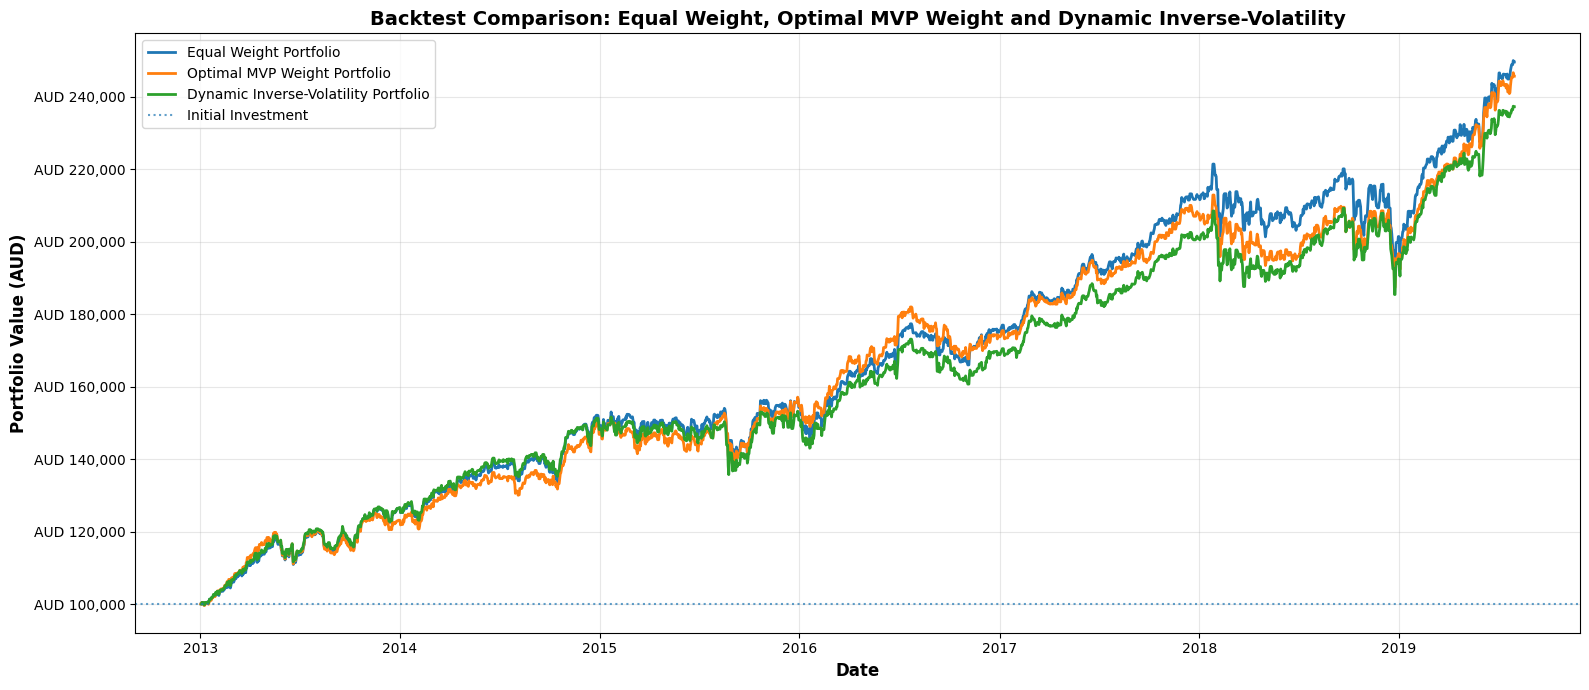

In [ ]:
performance_comparison = pd.DataFrame([
    calculate_strategy_performance(
        equal_weight_value,
        'Equal Weight Portfolio',
        INITIAL_CAPITAL
    ),
    calculate_strategy_performance(
        optimal_weight_value,
        'Optimal MVP Weight Portfolio',
        INITIAL_CAPITAL
    )
])


# Run dynamic inverse-volatility strategy
dynamic_weight_value, dynamic_weights_df = backtest_dynamic_inverse_volatility(
    optimal_mvp_stocks,
    df_test,
    initial_capital=INITIAL_CAPITAL,
    lookback=15,
    rebalance_freq=15
)

print("Dynamic inverse-volatility portfolio created successfully.")

dynamic_performance = calculate_strategy_performance(
    dynamic_weight_value,
    'Dynamic Inverse-Volatility Portfolio',
    INITIAL_CAPITAL
)

performance_comparison = pd.concat(
    [
        performance_comparison,
        pd.DataFrame([dynamic_performance])
    ],
    ignore_index=True
)

display(performance_comparison)

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    equal_weight_value.index,
    equal_weight_value['Total'],
    linewidth=2,
    label='Equal Weight Portfolio'
)

ax.plot(
    optimal_weight_value.index,
    optimal_weight_value['Total'],
    linewidth=2,
    label='Optimal MVP Weight Portfolio'
)

ax.plot(
    dynamic_weight_value.index,
    dynamic_weight_value['Total'],
    linewidth=2,
    label='Dynamic Inverse-Volatility Portfolio'
)

ax.axhline(
    y=INITIAL_CAPITAL,
    linestyle=':',
    linewidth=1.5,
    alpha=0.7,
    label='Initial Investment'
)

ax.set_title('Backtest Comparison: Equal Weight, Optimal MVP Weight and Dynamic Inverse-Volatility',fontsize=14,fontweight='bold')
ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Portfolio Value (AUD)', fontsize=12, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'AUD {x:,.0f}'))
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig('mvp_weight_strategy_comparison_backtest.png', dpi=300, bbox_inches='tight')
plt.show()


## Efficient Frontier / Risk-Return Visualisation

This section creates a Monte Carlo risk-return plot using the final selected stocks. It highlights the equal-weight portfolio and the optimal MVP portfolio.

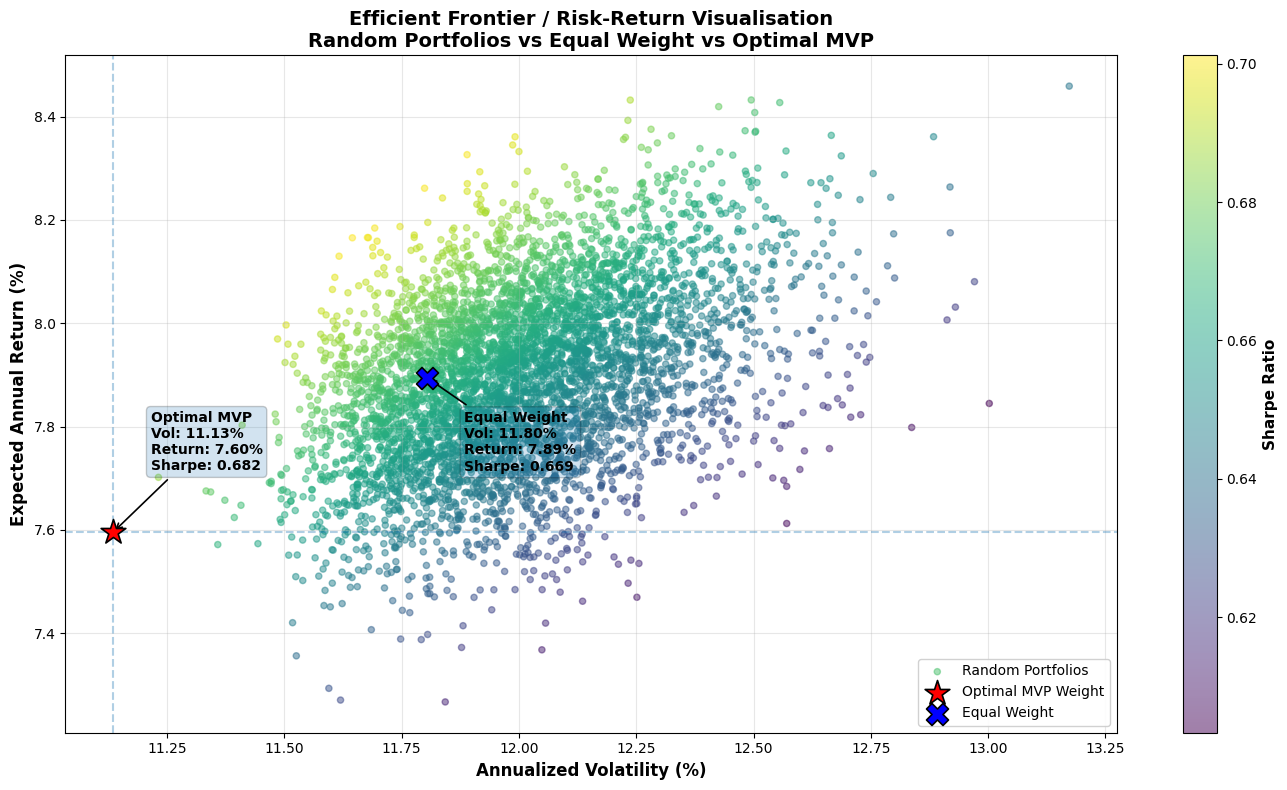

,Portfolio,Expected Return %,Volatility %,Sharpe Ratio
0,Optimal MVP Weight,7.595405,11.134877,0.682127
1,Equal Weight,7.894839,11.803556,0.668853


In [ ]:
def plot_efficient_frontier_monte_carlo(
    selected_stocks,
    optimal_weights,
    equal_weights,
    df_train,
    n_portfolios=5000
):
    """
    Generate random portfolios to visualise the risk-return trade-off.

    This compares:
    - Random simulated portfolios
    - Equal-weight portfolio
    - Optimal MVP-weight portfolio
    """

    returns_df = get_selected_returns(selected_stocks, df_train)

    expected_returns = []

    for col in returns_df.columns:
        stock_returns = returns_df[col]
        geometric_return = (1 + stock_returns).prod() ** (252 / len(stock_returns)) - 1
        expected_returns.append(geometric_return)

    expected_returns = np.array(expected_returns)

    covariance_matrix = returns_df.cov().values * 252

    n_assets = len(returns_df.columns)

    portfolio_returns = []
    portfolio_volatilities = []
    portfolio_sharpes = []

    np.random.seed(42)

    for _ in range(n_portfolios):

        weights = np.random.random(n_assets)
        weights = weights / weights.sum()

        ret = portfolio_return(weights, expected_returns) * 100
        vol = portfolio_volatility(weights, covariance_matrix) * 100

        sharpe = ret / vol if vol > 0 else 0

        portfolio_returns.append(ret)
        portfolio_volatilities.append(vol)
        portfolio_sharpes.append(sharpe)

    frontier_df = pd.DataFrame({
        'Return %': portfolio_returns,
        'Volatility %': portfolio_volatilities,
        'Sharpe Ratio': portfolio_sharpes
    })

    # Calculate optimal MVP metrics
    optimal_weights = np.array(optimal_weights)

    optimal_return = portfolio_return(optimal_weights, expected_returns) * 100
    optimal_volatility = portfolio_volatility(optimal_weights, covariance_matrix) * 100
    optimal_sharpe = optimal_return / optimal_volatility if optimal_volatility > 0 else 0

    # Calculate equal-weight metrics
    equal_weights = np.array(equal_weights)

    equal_return = portfolio_return(equal_weights, expected_returns) * 100
    equal_volatility = portfolio_volatility(equal_weights, covariance_matrix) * 100
    equal_sharpe = equal_return / equal_volatility if equal_volatility > 0 else 0

    # Plot efficient frontier
    fig, ax = plt.subplots(figsize=(14, 8))

    scatter = ax.scatter(
        frontier_df['Volatility %'],
        frontier_df['Return %'],
        c=frontier_df['Sharpe Ratio'],
        cmap='viridis',
        alpha=0.5,
        s=20,
        label='Random Portfolios'
    )

    # Optimal MVP point
    ax.scatter(
        optimal_volatility,
        optimal_return,
        marker='*',
        s=350,
        color='red',
        edgecolors='black',
        linewidth=1.2,
        zorder=5,
        label='Optimal MVP Weight'
    )

    # Equal-weight point
    ax.scatter(
        equal_volatility,
        equal_return,
        marker='X',
        s=250,
        color='blue',
        edgecolors='black',
        linewidth=1.2,
        zorder=5,
        label='Equal Weight'
    )

    # Guide lines for optimal MVP
    ax.axvline(
        x=optimal_volatility,
        linestyle='--',
        alpha=0.35
    )

    ax.axhline(
        y=optimal_return,
        linestyle='--',
        alpha=0.35
    )

    # Annotation for optimal MVP
    ax.annotate(
        f"Optimal MVP\nVol: {optimal_volatility:.2f}%\nReturn: {optimal_return:.2f}%\nSharpe: {optimal_sharpe:.3f}",
        xy=(optimal_volatility, optimal_return),
        xytext=(optimal_volatility + 0.08, optimal_return + 0.12),
        arrowprops=dict(
            arrowstyle='->',
            linewidth=1.2
        ),
        fontsize=10,
        fontweight='bold',
        bbox=dict(
            boxstyle='round,pad=0.3',
            alpha=0.2
        )
    )

    # Annotation for equal weight
    ax.annotate(
        f"Equal Weight\nVol: {equal_volatility:.2f}%\nReturn: {equal_return:.2f}%\nSharpe: {equal_sharpe:.3f}",
        xy=(equal_volatility, equal_return),
        xytext=(equal_volatility + 0.08, equal_return - 0.18),
        arrowprops=dict(
            arrowstyle='->',
            linewidth=1.2
        ),
        fontsize=10,
        fontweight='bold',
        bbox=dict(
            boxstyle='round,pad=0.3',
            alpha=0.2
        )
    )

    ax.set_title(
        'Efficient Frontier / Risk-Return Visualisation\nRandom Portfolios vs Equal Weight vs Optimal MVP',
        fontsize=14,
        fontweight='bold'
    )

    ax.set_xlabel(
        'Annualized Volatility (%)',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_ylabel(
        'Expected Annual Return (%)',
        fontsize=12,
        fontweight='bold'
    )

    ax.grid(True, alpha=0.3)

    ax.legend(
        loc='best',
        fontsize=10,
        framealpha=0.9
    )

    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Sharpe Ratio', fontsize=11, fontweight='bold')

    plt.tight_layout()

    plt.savefig(
        'mvp_efficient_frontier.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    # Summary table
    frontier_summary = pd.DataFrame([
        {
            'Portfolio': 'Optimal MVP Weight',
            'Expected Return %': optimal_return,
            'Volatility %': optimal_volatility,
            'Sharpe Ratio': optimal_sharpe
        },
        {
            'Portfolio': 'Equal Weight',
            'Expected Return %': equal_return,
            'Volatility %': equal_volatility,
            'Sharpe Ratio': equal_sharpe
        }
    ])

    display(frontier_summary)

    return frontier_df, frontier_summary

frontier_df, frontier_summary = plot_efficient_frontier_monte_carlo(
    selected_stocks=optimal_mvp_stocks,
    optimal_weights=optimal_mvp_weights,
    equal_weights=equal_weights,
    df_train=df_train,
    n_portfolios=5000
)

## Optional ML Dynamic Strategy (Classification model)

This optional section uses classification models to dynamically decide whether to hold the MVP portfolio or stay in cash. The features are standardised using `StandardScaler`. This is an extension and should be interpreted as a dynamic exposure strategy rather than a pure dynamic stock-weight optimiser.

In [ ]:
portfolio_stocks = optimal_mvp_stocks.copy()
portfolio_weights = optimal_mvp_weights.copy()

def create_features_from_mvp_portfolio(portfolio_stocks, portfolio_weights, df_data):
    """
    Create ML features based on MVP portfolio stocks and MVP weights.

    Features include:
    - weighted portfolio return
    - weighted volatility
    - momentum
    - number of positive return stocks
    - max and min stock returns
    """

    stock_cols = portfolio_stocks['bloomberg_col'].tolist()

    portfolio_weights = np.array(portfolio_weights)

    returns_df = pd.DataFrame()

    for col in stock_cols:
        if col in df_data.columns:
            returns_df[col] = df_data[col].pct_change()

    returns_df = returns_df.dropna()

    features = pd.DataFrame(index=returns_df.index)

    # Weighted MVP return
    features['weighted_return'] = returns_df.dot(portfolio_weights)

    # Cross-sectional volatility across stocks
    features['stock_volatility'] = returns_df.std(axis=1)

    # Momentum features based on MVP weighted return
    features['momentum_5d'] = features['weighted_return'].rolling(5).mean()
    features['momentum_10d'] = features['weighted_return'].rolling(10).mean()
    features['momentum_20d'] = features['weighted_return'].rolling(20).mean()

    # Rolling volatility based on MVP weighted return
    features['volatility_5d'] = features['weighted_return'].rolling(5).std()
    features['volatility_10d'] = features['weighted_return'].rolling(10).std()
    features['volatility_20d'] = features['weighted_return'].rolling(20).std()

    # Number of stocks with positive return each day
    features['num_positive'] = (returns_df > 0).sum(axis=1)

    # Maximum and minimum stock return each day
    features['max_return'] = returns_df.max(axis=1)
    features['min_return'] = returns_df.min(axis=1)

    features = features.dropna()

    return features


In [ ]:
def prepare_mvp_train_test_data(
    portfolio_stocks,
    portfolio_weights,
    df_train,
    df_test,
    portfolio_value_train,
    portfolio_value_test
):
    """
    Prepare training and testing datasets for MVP-based ML prediction.
    """

    print("\n" + "="*100)
    print("PREPARING MVP MACHINE LEARNING DATA")
    print("="*100)

    # Create MVP-based features
    features_train = create_features_from_mvp_portfolio(
        portfolio_stocks,
        portfolio_weights,
        df_train
    )

    features_test = create_features_from_mvp_portfolio(
        portfolio_stocks,
        portfolio_weights,
        df_test
    )

    # Align with portfolio value index
    features_train = features_train.loc[
        features_train.index.isin(portfolio_value_train.index)
    ]

    features_test = features_test.loc[
        features_test.index.isin(portfolio_value_test.index)
    ]

    # Create target variable
    target_train = create_target_variable(portfolio_value_train, horizon=1)
    target_test = create_target_variable(portfolio_value_test, horizon=1)

    # Align target with features
    target_train = target_train.loc[features_train.index]
    target_test = target_test.loc[features_test.index]

    # Remove last row because it has no future value
    features_train = features_train.iloc[:-1]
    target_train = target_train.iloc[:-1]

    features_test = features_test.iloc[:-1]
    target_test = target_test.iloc[:-1]

    print(f"\nTraining samples: {len(features_train)}")
    print(f"Test samples: {len(features_test)}")
    print(f"Number of features: {features_train.shape[1]}")
    print(f"Target distribution Train - Up: {target_train.sum()}, Down: {(target_train == 0).sum()}")
    print(f"Target distribution Test  - Up: {target_test.sum()}, Down: {(target_test == 0).sum()}")

    return features_train, target_train, features_test, target_test


In [ ]:
def create_target_variable(portfolio_value, horizon=1):
    """
    Create binary target variable.

    Target = 1 if portfolio value increases after 'horizon' days.
    Target = 0 if portfolio value decreases or stays the same.
    """

    future_value = portfolio_value['Total'].shift(-horizon)

    current_value = portfolio_value['Total']

    target = (future_value > current_value).astype(int)

    return target


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def train_models(X_train, y_train):
    """
    Train Random Forest and Logistic Regression models.
    """

    print("\n" + "="*100)
    print("TRAINING MACHINE LEARNING MODELS")
    print("="*100)

    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # Train Random Forest
    print("\nTraining Random Forest...")

    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        class_weight='balanced'
    )

    rf_model.fit(X_train_scaled, y_train)

    # Train Logistic Regression
    print("Training Logistic Regression...")

    lr_model = LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    )

    lr_model.fit(X_train_scaled, y_train)

    print("\nModels trained successfully!")

    return rf_model, lr_model, scaler


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

def predict_and_evaluate(rf_model, lr_model, scaler, X_test, y_test):
    """
    Make predictions and evaluate Random Forest and Logistic Regression.
    """

    # Scale test data using the same scaler from training
    X_test_scaled = scaler.transform(X_test)

    # Make class predictions
    rf_predictions = rf_model.predict(X_test_scaled)
    lr_predictions = lr_model.predict(X_test_scaled)

    # Prediction probabilities for class 1 = Up
    rf_proba = rf_model.predict_proba(X_test_scaled)[:, 1]
    lr_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

    print("\n" + "="*100)
    print("MODEL EVALUATION")
    print("="*100)

    print("\n--- RANDOM FOREST ---")
    print(f"Accuracy: {accuracy_score(y_test, rf_predictions):.4f}")
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        rf_predictions,
        target_names=['Down', 'Up']
    ))

    print("\n--- LOGISTIC REGRESSION ---")
    print(f"Accuracy: {accuracy_score(y_test, lr_predictions):.4f}")
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        lr_predictions,
        target_names=['Down', 'Up']
    ))

    return rf_predictions, lr_predictions, rf_proba, lr_proba


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_confusion_matrices(y_test, rf_predictions, lr_predictions):
    """
    Plot confusion matrices for Random Forest and Logistic Regression.
    """

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Random Forest confusion matrix
    rf_cm = confusion_matrix(y_test, rf_predictions)

    sns.heatmap(
        rf_cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[0],
        xticklabels=['Down', 'Up'],
        yticklabels=['Down', 'Up']
    )

    axes[0].set_title(
        'Random Forest Confusion Matrix',
        fontsize=14,
        fontweight='bold'
    )
    axes[0].set_ylabel('Actual', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Predicted', fontsize=12, fontweight='bold')

    # Logistic Regression confusion matrix
    lr_cm = confusion_matrix(y_test, lr_predictions)

    sns.heatmap(
        lr_cm,
        annot=True,
        fmt='d',
        cmap='Greens',
        ax=axes[1],
        xticklabels=['Down', 'Up'],
        yticklabels=['Down', 'Up']
    )

    axes[1].set_title(
        'Logistic Regression Confusion Matrix',
        fontsize=14,
        fontweight='bold'
    )
    axes[1].set_ylabel('Actual', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Predicted', fontsize=12, fontweight='bold')

    plt.tight_layout()

    plt.savefig(
        'mvp_ml_confusion_matrices.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    return fig, axes


In [ ]:
def simulate_portfolio_with_predictions(
    portfolio_value_test,
    rf_predictions,
    lr_predictions,
    X_test,
    initial_investment=100000
):
    """
    Simulate portfolio performance using ML predictions.

    If the model predicts Up = 1, the strategy holds the MVP portfolio for that day.
    If the model predicts Down = 0, the strategy stays in cash for that day.
    """

    test_dates = X_test.index

    # Get actual MVP daily returns
    actual_returns = (
        portfolio_value_test
        .loc[test_dates, 'Daily_Return']
        .dropna()
        .values
    )

    # Make sure arrays have the same length
    min_len = min(
        len(actual_returns),
        len(rf_predictions),
        len(lr_predictions),
        len(test_dates)
    )

    actual_returns = actual_returns[:min_len]
    rf_predictions = rf_predictions[:min_len]
    lr_predictions = lr_predictions[:min_len]
    test_dates = test_dates[:min_len]

    # Start portfolio values
    actual_portfolio = [initial_investment]
    rf_portfolio = [initial_investment]
    lr_portfolio = [initial_investment]

    for i in range(min_len):

        # Buy-and-hold MVP portfolio
        actual_value = actual_portfolio[-1] * (1 + actual_returns[i])
        actual_portfolio.append(actual_value)

        # Random Forest strategy
        if rf_predictions[i] == 1:
            rf_value = rf_portfolio[-1] * (1 + actual_returns[i])
        else:
            rf_value = rf_portfolio[-1]

        rf_portfolio.append(rf_value)

        # Logistic Regression strategy
        if lr_predictions[i] == 1:
            lr_value = lr_portfolio[-1] * (1 + actual_returns[i])
        else:
            lr_value = lr_portfolio[-1]

        lr_portfolio.append(lr_value)

    simulation_df = pd.DataFrame({
        'Date': test_dates,
        'Actual_MVP_Buy_Hold': actual_portfolio[1:],
        'Random_Forest_Strategy': rf_portfolio[1:],
        'Logistic_Regression_Strategy': lr_portfolio[1:]
    })

    simulation_df.set_index('Date', inplace=True)

    return simulation_df


In [ ]:
def plot_portfolio_comparison(simulation_df, initial_investment=100000):
    """
    Plot MVP buy-and-hold portfolio versus ML prediction strategies.
    """

    fig, axes = plt.subplots(2, 1, figsize=(16, 12))

    # Plot 1: Portfolio value
    axes[0].plot(
        simulation_df.index,
        simulation_df['Actual_MVP_Buy_Hold'],
        linewidth=2.5,
        label='Actual MVP Buy & Hold'
    )

    axes[0].plot(
        simulation_df.index,
        simulation_df['Random_Forest_Strategy'],
        linewidth=2,
        linestyle='--',
        label='Random Forest Strategy'
    )

    axes[0].plot(
        simulation_df.index,
        simulation_df['Logistic_Regression_Strategy'],
        linewidth=2,
        linestyle='--',
        label='Logistic Regression Strategy'
    )

    axes[0].axhline(
        y=initial_investment,
        linestyle=':',
        linewidth=1.5,
        alpha=0.7,
        label='Initial Investment'
    )

    axes[0].set_title(
        'MVP Portfolio Performance: Buy-and-Hold vs ML Strategies',
        fontsize=14,
        fontweight='bold'
    )

    axes[0].set_xlabel('Date', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Portfolio Value ($)', fontsize=12, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[0].yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, p: f'$ {x:,.0f}')
    )

    # Plot 2: Cumulative return
    for col in simulation_df.columns:

        cumulative_return = (
            (simulation_df[col] - initial_investment)
            / initial_investment
        ) * 100

        axes[1].plot(
            simulation_df.index,
            cumulative_return,
            linewidth=2,
            label=col.replace('_', ' ')
        )

    axes[1].axhline(
        y=0,
        linestyle=':',
        linewidth=1.5,
        alpha=0.7
    )

    axes[1].set_title(
        'Cumulative Returns: MVP vs ML Strategies',
        fontsize=14,
        fontweight='bold'
    )

    axes[1].set_xlabel('Date', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Cumulative Return (%)', fontsize=12, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()

    plt.savefig(
        'mvp_ml_portfolio_comparison.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    return fig, axes


In [ ]:
def calculate_performance_metrics(simulation_df, initial_investment=100000):
    """
    Calculate performance metrics for MVP buy-and-hold and ML strategies.
    """

    print("\n" + "="*100)
    print("MVP PORTFOLIO PERFORMANCE COMPARISON")
    print("="*100)

    results = []

    for strategy in simulation_df.columns:

        start_value = simulation_df[strategy].iloc[0]
        end_value = simulation_df[strategy].iloc[-1]

        total_return = ((end_value - start_value) / start_value) * 100

        daily_returns = simulation_df[strategy].pct_change().dropna()

        annualized_volatility = daily_returns.std() * np.sqrt(252) * 100

        years = len(simulation_df) / 252

        if years > 0:
            annualized_return = ((end_value / start_value) ** (1 / years) - 1) * 100
        else:
            annualized_return = 0

        if annualized_volatility > 0:
            sharpe_ratio = annualized_return / annualized_volatility
        else:
            sharpe_ratio = 0

        rolling_max = simulation_df[strategy].cummax()
        drawdown = (simulation_df[strategy] - rolling_max) / rolling_max
        max_drawdown = drawdown.min() * 100

        profit_loss = end_value - initial_investment

        print(f"\n{strategy.replace('_', ' ').upper()}:")
        print(f"  Final Value:            $ {end_value:,.2f}")
        print(f"  Profit / Loss:          $ {profit_loss:,.2f}")
        print(f"  Total Return:           {total_return:.2f}%")
        print(f"  Annualized Return:      {annualized_return:.2f}%")
        print(f"  Annualized Volatility:  {annualized_volatility:.2f}%")
        print(f"  Sharpe Ratio:           {sharpe_ratio:.3f}")
        print(f"  Maximum Drawdown:       {max_drawdown:.2f}%")

        results.append({
            'Strategy': strategy,
            'Final Value': end_value,
            'Profit/Loss': profit_loss,
            'Total Return %': total_return,
            'Annualized Return %': annualized_return,
            'Annualized Volatility %': annualized_volatility,
            'Sharpe Ratio': sharpe_ratio,
            'Maximum Drawdown %': max_drawdown
        })

    print("="*100)

    performance_df = pd.DataFrame(results)

    return performance_df



MVP MACHINE LEARNING PORTFOLIO PREDICTION

PREPARING MVP MACHINE LEARNING DATA

Training samples: 7036
Test samples: 2381
Number of features: 11
Target distribution Train - Up: 2603, Down: 4433
Target distribution Test  - Up: 898, Down: 1483

TRAINING MACHINE LEARNING MODELS

Training Random Forest...
Training Logistic Regression...

Models trained successfully!

MODEL EVALUATION

--- RANDOM FOREST ---
Accuracy: 0.5930

Classification Report:
              precision    recall  f1-score   support

        Down       0.68      0.66      0.67      1483
          Up       0.46      0.48      0.47       898

    accuracy                           0.59      2381
   macro avg       0.57      0.57      0.57      2381
weighted avg       0.60      0.59      0.59      2381


--- LOGISTIC REGRESSION ---
Accuracy: 0.5582

Classification Report:
              precision    recall  f1-score   support

        Down       0.70      0.50      0.59      1483
          Up       0.44      0.65      0.53   

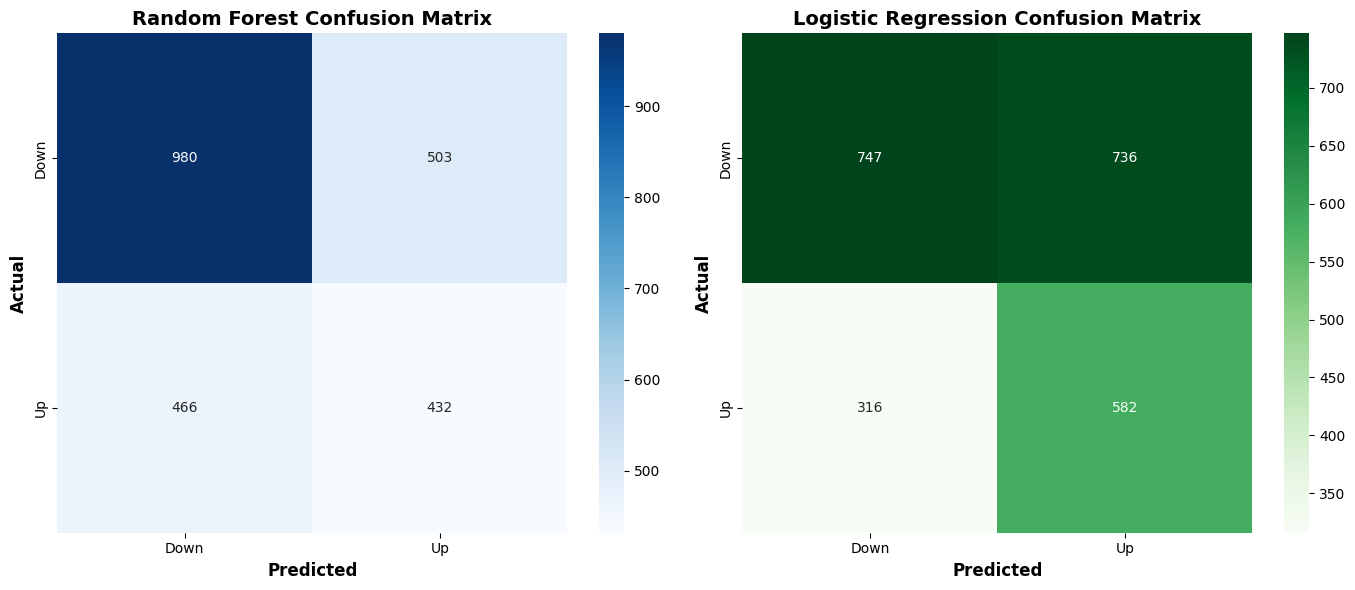

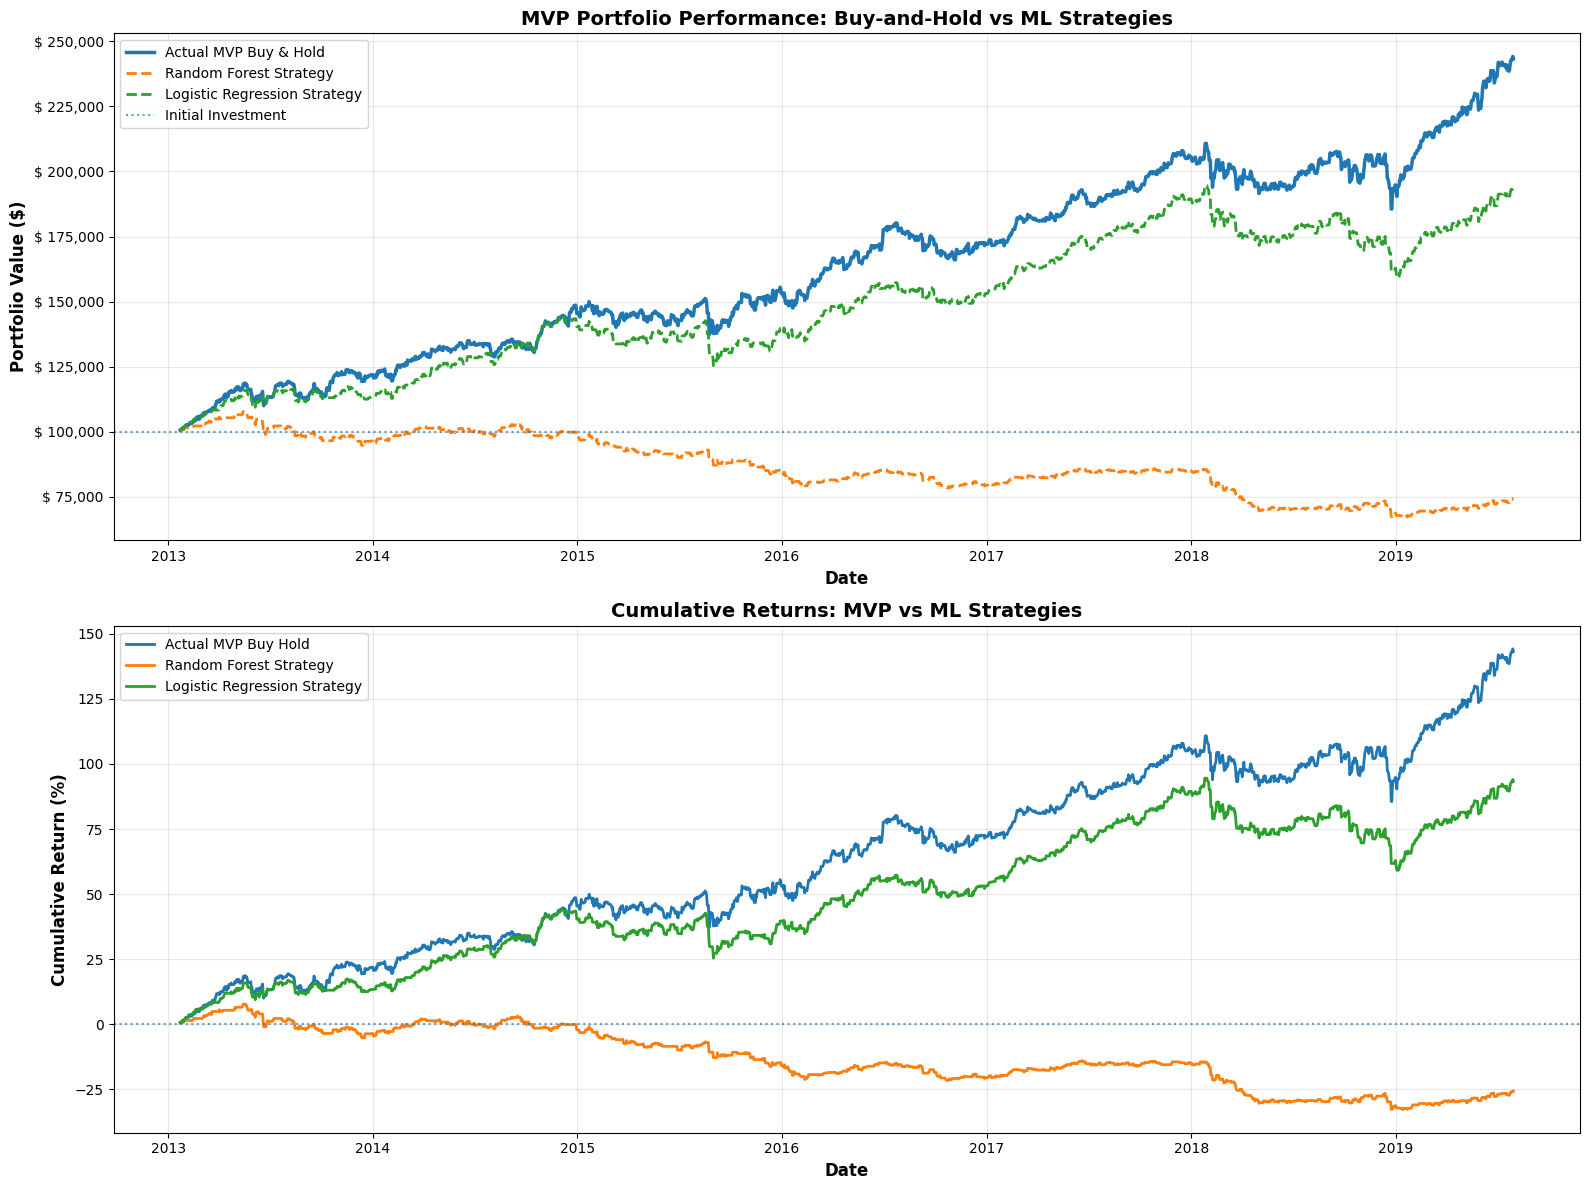


MVP PORTFOLIO PERFORMANCE COMPARISON

ACTUAL MVP BUY HOLD:
  Final Value:            $ 243,273.54
  Profit / Loss:          $ 143,273.54
  Total Return:           141.87%
  Annualized Return:      9.80%
  Annualized Volatility:  9.02%
  Sharpe Ratio:           1.086
  Maximum Drawdown:       -11.97%

RANDOM FOREST STRATEGY:
  Final Value:            $ 74,324.25
  Profit / Loss:          $ -25,675.75
  Total Return:           -26.11%
  Annualized Return:      -3.15%
  Annualized Volatility:  6.34%
  Sharpe Ratio:           -0.497
  Maximum Drawdown:       -37.66%

LOGISTIC REGRESSION STRATEGY:
  Final Value:            $ 193,303.99
  Profit / Loss:          $ 93,303.99
  Total Return:           92.19%
  Annualized Return:      7.16%
  Annualized Volatility:  7.33%
  Sharpe Ratio:           0.977
  Maximum Drawdown:       -18.19%


,Strategy,Final Value,Profit/Loss,Total Return %,Annualized Return %,Annualized Volatility %,Sharpe Ratio,Maximum Drawdown %
0,Actual_MVP_Buy_Hold,243273.539995,143273.539995,141.866308,9.798601,9.024028,1.085834,-11.971690
1,Random_Forest_Strategy,74324.253496,-25675.746504,-26.105680,-3.151238,6.335889,-0.497363,-37.661162
2,Logistic_Regression_Strategy,193303.987478,93303.987478,92.185808,7.158953,7.330687,0.976573,-18.185252


In [ ]:
# ═══════════════════════════════════════════════════════════════
# MAIN EXECUTION: MVP + MACHINE LEARNING PREDICTION
# ═══════════════════════════════════════════════════════════════

print("\n" + "="*100)
print("MVP MACHINE LEARNING PORTFOLIO PREDICTION")
print("="*100)

# Step 1: Use the optimised MVP portfolio
portfolio_stocks = optimal_mvp_stocks.copy()
portfolio_weights = optimal_mvp_weights.copy()

# Step 2: Define train and test periods
df_train = df.loc['1993-09-07':'2013-01-01']
df_test = df.loc['2013-01-02':'2019-07-31']

# Step 3: Initial investment
initial_investment = 100000

# Step 4: Backtest MVP portfolio for train period
portfolio_value_train, shares_train = backtest_mvp_portfolio(
    portfolio_stocks,
    portfolio_weights,
    df_train,
    initial_investment,
    period_name='Train'
)

# Step 5: Backtest MVP portfolio for test period
portfolio_value_test, shares_test = backtest_mvp_portfolio(
    portfolio_stocks,
    portfolio_weights,
    df_test,
    initial_investment,
    period_name='Test'
)

# Step 6: Prepare MVP ML data
X_train, y_train, X_test, y_test = prepare_mvp_train_test_data(
    portfolio_stocks,
    portfolio_weights,
    df_train,
    df_test,
    portfolio_value_train[portfolio_value_train['Period'] == 'Train'],
    portfolio_value_test[portfolio_value_test['Period'] == 'Test']
)

# Step 7: Train ML models
rf_model, lr_model, scaler = train_models(
    X_train,
    y_train
)

# Step 8: Make predictions and evaluate
rf_predictions, lr_predictions, rf_proba, lr_proba = predict_and_evaluate(
    rf_model,
    lr_model,
    scaler,
    X_test,
    y_test
)

# Step 9: Plot confusion matrices
plot_confusion_matrices(
    y_test,
    rf_predictions,
    lr_predictions
)

# Step 10: Simulate MVP portfolio with ML predictions
simulation_df = simulate_portfolio_with_predictions(
    portfolio_value_test[portfolio_value_test['Period'] == 'Test'],
    rf_predictions,
    lr_predictions,
    X_test,
    initial_investment
)

# Step 11: Plot portfolio comparison
plot_portfolio_comparison(
    simulation_df,
    initial_investment
)

# Step 12: Calculate performance metrics
calculate_performance_metrics(
    simulation_df,
    initial_investment
)


## Final Performance Comparison and Interpretation

Use this section to summarise the final findings from the MVP analysis.

In [ ]:
print("="*100)
print("FINAL MVP SUMMARY")
print("="*100)

print("Training period:", TRAIN_START, "to", TRAIN_END)
print("Testing period:", TEST_START, "to", TEST_END)
print("Volatility screening threshold:", f"{VOLATILITY_THRESHOLD}%")
print("Minimum expected return:", f"{MINIMUM_RETURN}%")
print("Maximum stock allocation:", f"{MAX_STOCK_WEIGHT*100:.0f}%")
print("Maximum sector allocation:", f"{MAX_SECTOR_WEIGHT*100:.0f}%")

print("\nOptimal MVP candidate size:", int(optimal_mvp_metrics['n_stocks']))


print("\nPerformance comparison:")
display(performance_comparison)

print("\nSuggested interpretation:")
print("The optimal MVP was selected based on the lowest feasible annualized volatility during the training period.")
print("The equal-weight benchmark provides a simple comparison to evaluate whether optimisation improved risk-adjusted performance.")
print("The out-of-sample backtest should be assessed using total return, annualized volatility, Sharpe ratio, and maximum drawdown.")


FINAL MVP SUMMARY
Training period: 1993-09-07 to 2013-01-01
Testing period: 2013-01-02 to 2019-07-31
Volatility screening threshold: 25%
Minimum expected return: 6%
Maximum stock allocation: 10%
Maximum sector allocation: 30%

Optimal MVP candidate size: 19

Performance comparison:


,Strategy,Final Value AUD,Profit/Loss AUD,Total Return %,Annualized Return %,Annualized Volatility %,Sharpe Ratio,Maximum Drawdown %
0,Equal Weight Portfolio,249626.239248,149626.239248,149.626239,10.072984,9.235800,1.090646,-13.989308
1,Optimal MVP Weight Portfolio,245708.685832,145708.685832,145.708686,9.890467,8.996313,1.099391,-11.971690
2,Dynamic Inverse-Volatility Portfolio,237270.710546,137270.710546,137.238665,9.490910,8.950144,1.060420,-11.381338



Suggested interpretation:
The optimal MVP was selected based on the lowest feasible annualized volatility during the training period.
The equal-weight benchmark provides a simple comparison to evaluate whether optimisation improved risk-adjusted performance.
The out-of-sample backtest should be assessed using total return, annualized volatility, Sharpe ratio, and maximum drawdown.


## Portfolio simulation and Evaluation

In [ ]:
# ═══════════════════════════════════════════════════════════════
# Regression model: RANDOM FOREST VS LINEAR REGRESSION
# ═══════════════════════════════════════════════════════════════

# Create training-period portfolio values for each weight type

equal_weight_train_value, _ = backtest_mvp_portfolio(
    optimal_mvp_stocks,
    equal_weights,
    df_train,
    INITIAL_CAPITAL,
    period_name='Equal Weight Train'
)

optimal_weight_train_value, _ = backtest_mvp_portfolio(
    optimal_mvp_stocks,
    optimal_mvp_weights,
    df_train,
    INITIAL_CAPITAL,
    period_name='Optimal MVP Weight Train'
)

dynamic_weight_train_value, dynamic_train_weights_df = backtest_dynamic_inverse_volatility(
    optimal_mvp_stocks,
    df_train,
    initial_capital=INITIAL_CAPITAL,
    lookback=15,
    rebalance_freq=15
)

print("Training portfolio values created successfully.")

Training portfolio values created successfully.


In [ ]:
def create_ml_features_from_portfolio_value(portfolio_value):
    """
    Create ML features from a portfolio value series.

    Features are based on past returns only.
    Target is the current day's portfolio return.
    """

    returns = portfolio_value['Total'].pct_change()

    features = pd.DataFrame(index=portfolio_value.index)

    # Lagged returns
    features['return_lag_1'] = returns.shift(1)
    features['return_lag_2'] = returns.shift(2)
    features['return_lag_3'] = returns.shift(3)

    # Rolling average returns
    features['return_mean_5'] = returns.rolling(5).mean().shift(1)
    features['return_mean_10'] = returns.rolling(10).mean().shift(1)
    features['return_mean_20'] = returns.rolling(20).mean().shift(1)

    # Rolling volatility
    features['volatility_5'] = returns.rolling(5).std().shift(1)
    features['volatility_10'] = returns.rolling(10).std().shift(1)
    features['volatility_20'] = returns.rolling(20).std().shift(1)

    # Momentum
    features['momentum_5'] = returns.rolling(5).sum().shift(1)
    features['momentum_10'] = returns.rolling(10).sum().shift(1)
    features['momentum_20'] = returns.rolling(20).sum().shift(1)

    # Target: current day return in percentage
    target = returns * 100

    # Remove missing values
    features = features.dropna()
    target = target.loc[features.index]

    return features, target

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def train_and_evaluate_ml_models(
    train_value,
    test_value,
    strategy_name
):
    """
    Train Random Forest and Linear Regression models for one portfolio strategy.
    """

    print("\n" + "="*100)
    print(f"ML RETURN PREDICTION FOR: {strategy_name.upper()}")
    print("="*100)

    # Create features and target
    X_train, y_train = create_ml_features_from_portfolio_value(train_value)
    X_test, y_test = create_ml_features_from_portfolio_value(test_value)

    # Standardize features
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Random Forest Regressor
    rf_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train_scaled, y_train)

    rf_pred = rf_model.predict(X_test_scaled)

    # Linear Regression
    lr_model = LinearRegression()

    lr_model.fit(X_train_scaled, y_train)

    lr_pred = lr_model.predict(X_test_scaled)

    # Evaluation metrics
    rf_mse = mean_squared_error(y_test, rf_pred)
    rf_rmse = np.sqrt(rf_mse)
    rf_mae = mean_absolute_error(y_test, rf_pred)
    rf_r2 = r2_score(y_test, rf_pred)

    lr_mse = mean_squared_error(y_test, lr_pred)
    lr_rmse = np.sqrt(lr_mse)
    lr_mae = mean_absolute_error(y_test, lr_pred)
    lr_r2 = r2_score(y_test, lr_pred)

    # Directional accuracy
    actual_direction = (y_test > 0).astype(int)

    rf_direction = (rf_pred > 0).astype(int)
    lr_direction = (lr_pred > 0).astype(int)

    rf_direction_accuracy = (actual_direction == rf_direction).mean()
    lr_direction_accuracy = (actual_direction == lr_direction).mean()

    results = pd.DataFrame([
        {
            'Strategy': strategy_name,
            'Model': 'Random Forest',
            'MSE': rf_mse,
            'RMSE': rf_rmse,
            'MAE': rf_mae,
            'R2': rf_r2,
            'Directional Accuracy': rf_direction_accuracy
        },
        {
            'Strategy': strategy_name,
            'Model': 'Linear Regression',
            'MSE': lr_mse,
            'RMSE': lr_rmse,
            'MAE': lr_mae,
            'R2': lr_r2,
            'Directional Accuracy': lr_direction_accuracy
        }
    ])

    display(results)

    predictions_df = pd.DataFrame(
        {
            'Actual Return %': y_test,
            'Random Forest Prediction %': rf_pred,
            'Linear Regression Prediction %': lr_pred
        },
        index=y_test.index
    )

    return results, predictions_df

In [ ]:
def simulate_ml_strategy(
    test_value,
    predictions_df,
    prediction_column,
    initial_capital=100000
):
    """
    Simulate ML-based dynamic allocation.

    If predicted return is positive, hold the portfolio.
    If predicted return is negative or zero, stay in cash.
    """

    test_returns = test_value['Total'].pct_change()

    # Align returns with prediction dates
    test_returns = test_returns.loc[predictions_df.index]

    portfolio_values = []

    portfolio_value = initial_capital

    for date in predictions_df.index:

        predicted_return = predictions_df.loc[date, prediction_column]
        actual_return = test_returns.loc[date]

        if predicted_return > 0:
            portfolio_value = portfolio_value * (1 + actual_return)
        else:
            portfolio_value = portfolio_value

        portfolio_values.append(portfolio_value)

    strategy_value = pd.DataFrame(
        {
            'Total': portfolio_values
        },
        index=predictions_df.index
    )

    strategy_value['Daily_Return'] = strategy_value['Total'].pct_change()

    strategy_value['Cumulative_Return'] = (
        1 + strategy_value['Daily_Return']
    ).cumprod() - 1

    return strategy_value

In [ ]:
def plot_ml_strategy_result(
    strategy_name,
    buy_hold_value,
    rf_strategy_value,
    lr_strategy_value,
    predictions_df,
    initial_capital=100000
):
    """
    Plot buy-and-hold vs ML strategies for one portfolio weight type.
    """

    fig, axes = plt.subplots(3, 1, figsize=(16, 14))

    # Plot 1: Portfolio value
    axes[0].plot(
        buy_hold_value.index,
        buy_hold_value['Total'],
        linewidth=2,
        label='Actual Buy & Hold'
    )

    axes[0].plot(
        rf_strategy_value.index,
        rf_strategy_value['Total'],
        linestyle='--',
        linewidth=2,
        label='Random Forest Strategy'
    )

    axes[0].plot(
        lr_strategy_value.index,
        lr_strategy_value['Total'],
        linestyle='--',
        linewidth=2,
        label='Linear Regression Strategy'
    )

    axes[0].axhline(
        y=initial_capital,
        linestyle=':',
        linewidth=1.5,
        alpha=0.7,
        label='Initial Investment'
    )

    axes[0].set_title(
        f'[{strategy_name}] Portfolio Performance',
        fontsize=14,
        fontweight='bold'
    )

    axes[0].set_ylabel('Portfolio Value (AUD)', fontsize=12, fontweight='bold')

    axes[0].yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, p: f'AUD {x:,.0f}')
    )

    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Plot 2: Predicted vs actual daily returns
    axes[1].plot(
        predictions_df.index,
        predictions_df['Actual Return %'],
        linewidth=1,
        label='Actual Return'
    )

    axes[1].plot(
        predictions_df.index,
        predictions_df['Random Forest Prediction %'],
        linestyle='--',
        linewidth=1.5,
        label='RF Prediction'
    )

    axes[1].plot(
        predictions_df.index,
        predictions_df['Linear Regression Prediction %'],
        linestyle='--',
        linewidth=1.5,
        label='LR Prediction'
    )

    axes[1].axhline(
        y=0,
        linestyle=':',
        linewidth=1.2,
        alpha=0.7
    )

    axes[1].set_title(
        'Predicted vs Actual Daily Returns',
        fontsize=13,
        fontweight='bold'
    )

    axes[1].set_ylabel('Daily Return (%)', fontsize=12, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    # Plot 3: Cumulative return
    buy_hold_cumulative = (
        (buy_hold_value['Total'] / buy_hold_value['Total'].iloc[0]) - 1
    ) * 100

    rf_cumulative = (
        (rf_strategy_value['Total'] / rf_strategy_value['Total'].iloc[0]) - 1
    ) * 100

    lr_cumulative = (
        (lr_strategy_value['Total'] / lr_strategy_value['Total'].iloc[0]) - 1
    ) * 100

    axes[2].plot(
        buy_hold_cumulative.index,
        buy_hold_cumulative,
        linewidth=2,
        label='Actual Buy & Hold'
    )

    axes[2].plot(
        rf_cumulative.index,
        rf_cumulative,
        linestyle='--',
        linewidth=2,
        label='Random Forest Strategy'
    )

    axes[2].plot(
        lr_cumulative.index,
        lr_cumulative,
        linestyle='--',
        linewidth=2,
        label='Linear Regression Strategy'
    )

    axes[2].axhline(
        y=0,
        linestyle=':',
        linewidth=1.2,
        alpha=0.7
    )

    axes[2].set_title(
        'Cumulative Returns',
        fontsize=13,
        fontweight='bold'
    )

    axes[2].set_xlabel('Date', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Cumulative Return (%)', fontsize=12, fontweight='bold')
    axes[2].grid(True, alpha=0.3)
    axes[2].legend()

    plt.tight_layout()

    filename = strategy_name.lower().replace(' ', '_').replace('-', '_')
    plt.savefig(
        f'{filename}_ml_strategy_comparison.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    return fig, axes


ML RETURN PREDICTION FOR: EQUAL WEIGHT


,Strategy,Model,MSE,RMSE,MAE,R2,Directional Accuracy
0,Equal Weight,Random Forest,0.359150,0.599292,0.380495,-0.054915,0.511550
1,Equal Weight,Linear Regression,0.342727,0.585429,0.365960,-0.006677,0.450231


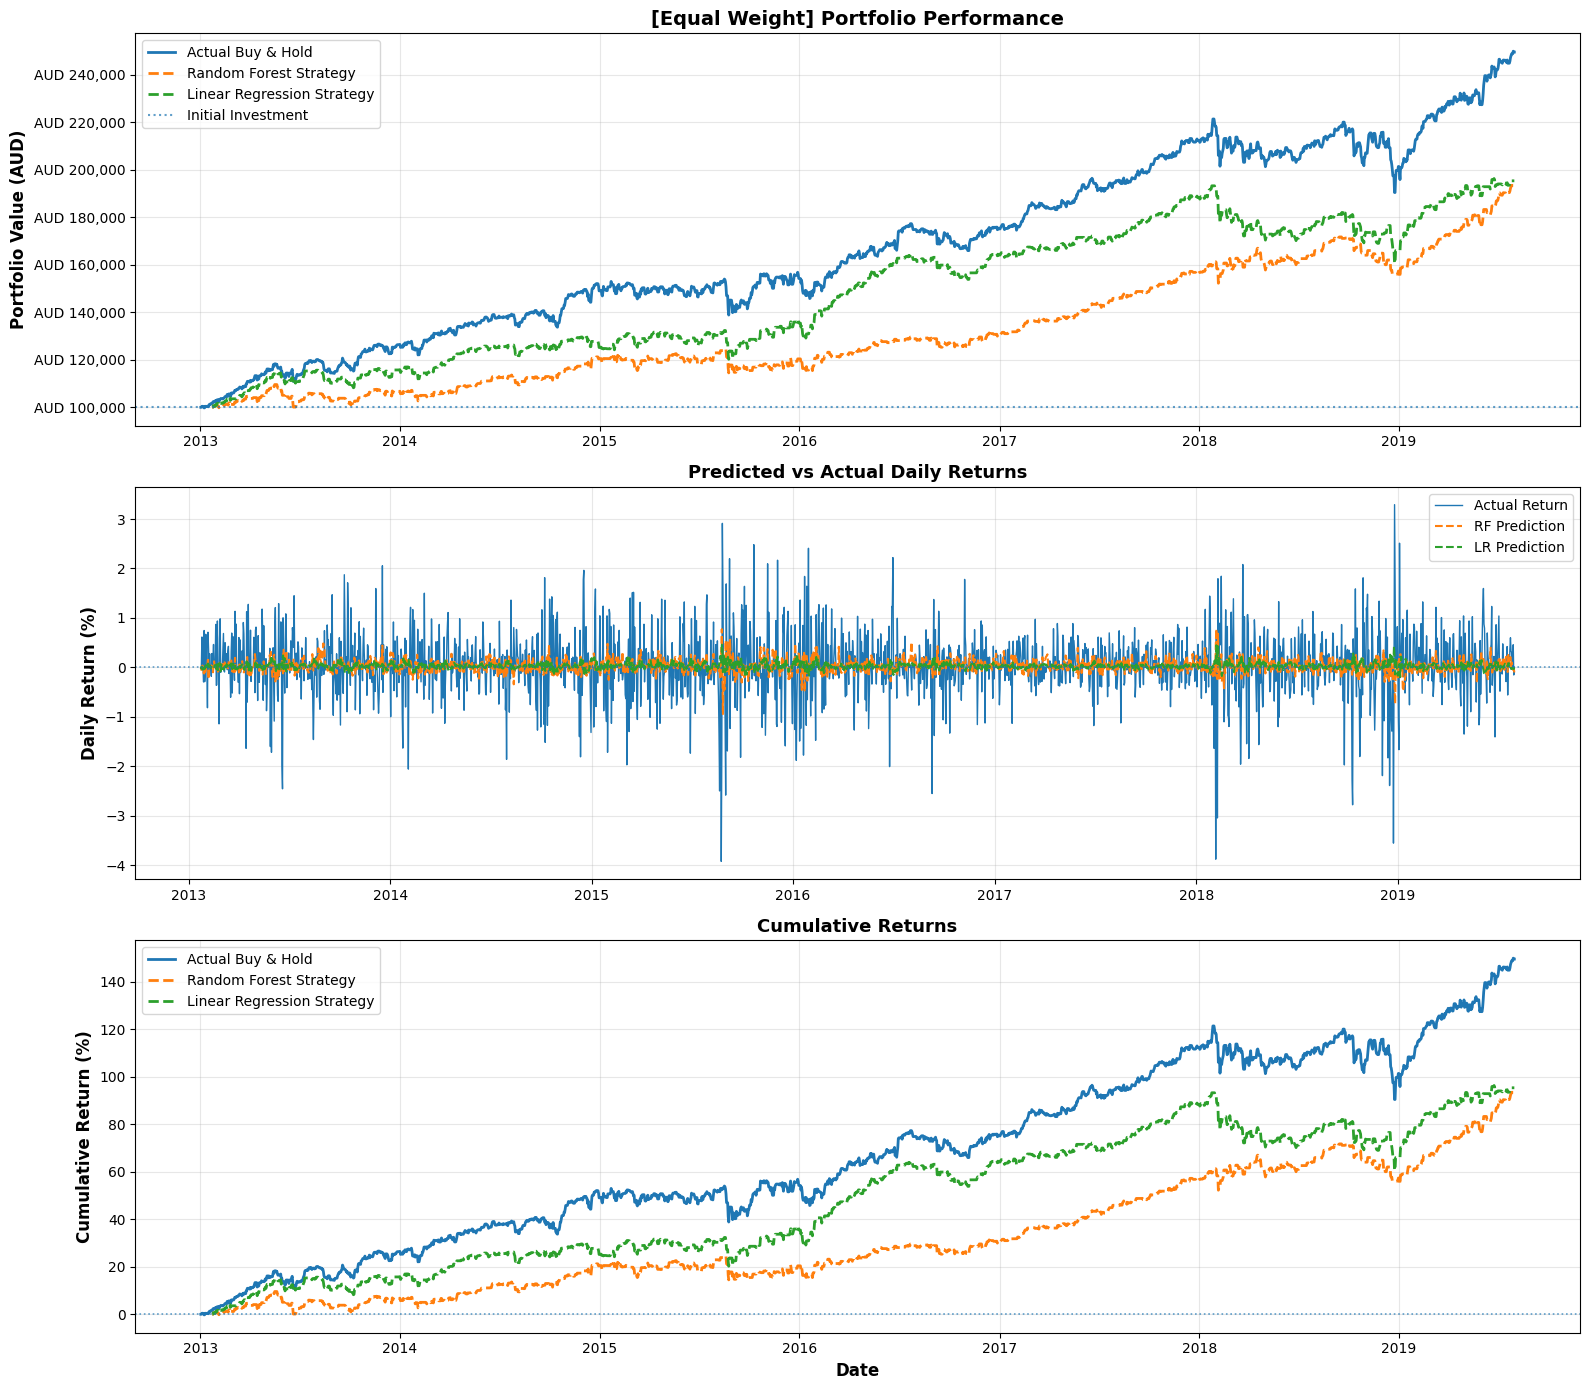


ML RETURN PREDICTION FOR: OPTIMAL MVP WEIGHT


,Strategy,Model,MSE,RMSE,MAE,R2,Directional Accuracy
0,Optimal MVP Weight,Random Forest,0.347201,0.589238,0.377978,-0.075338,0.474171
1,Optimal MVP Weight,Linear Regression,0.324398,0.569559,0.360351,-0.004712,0.453591


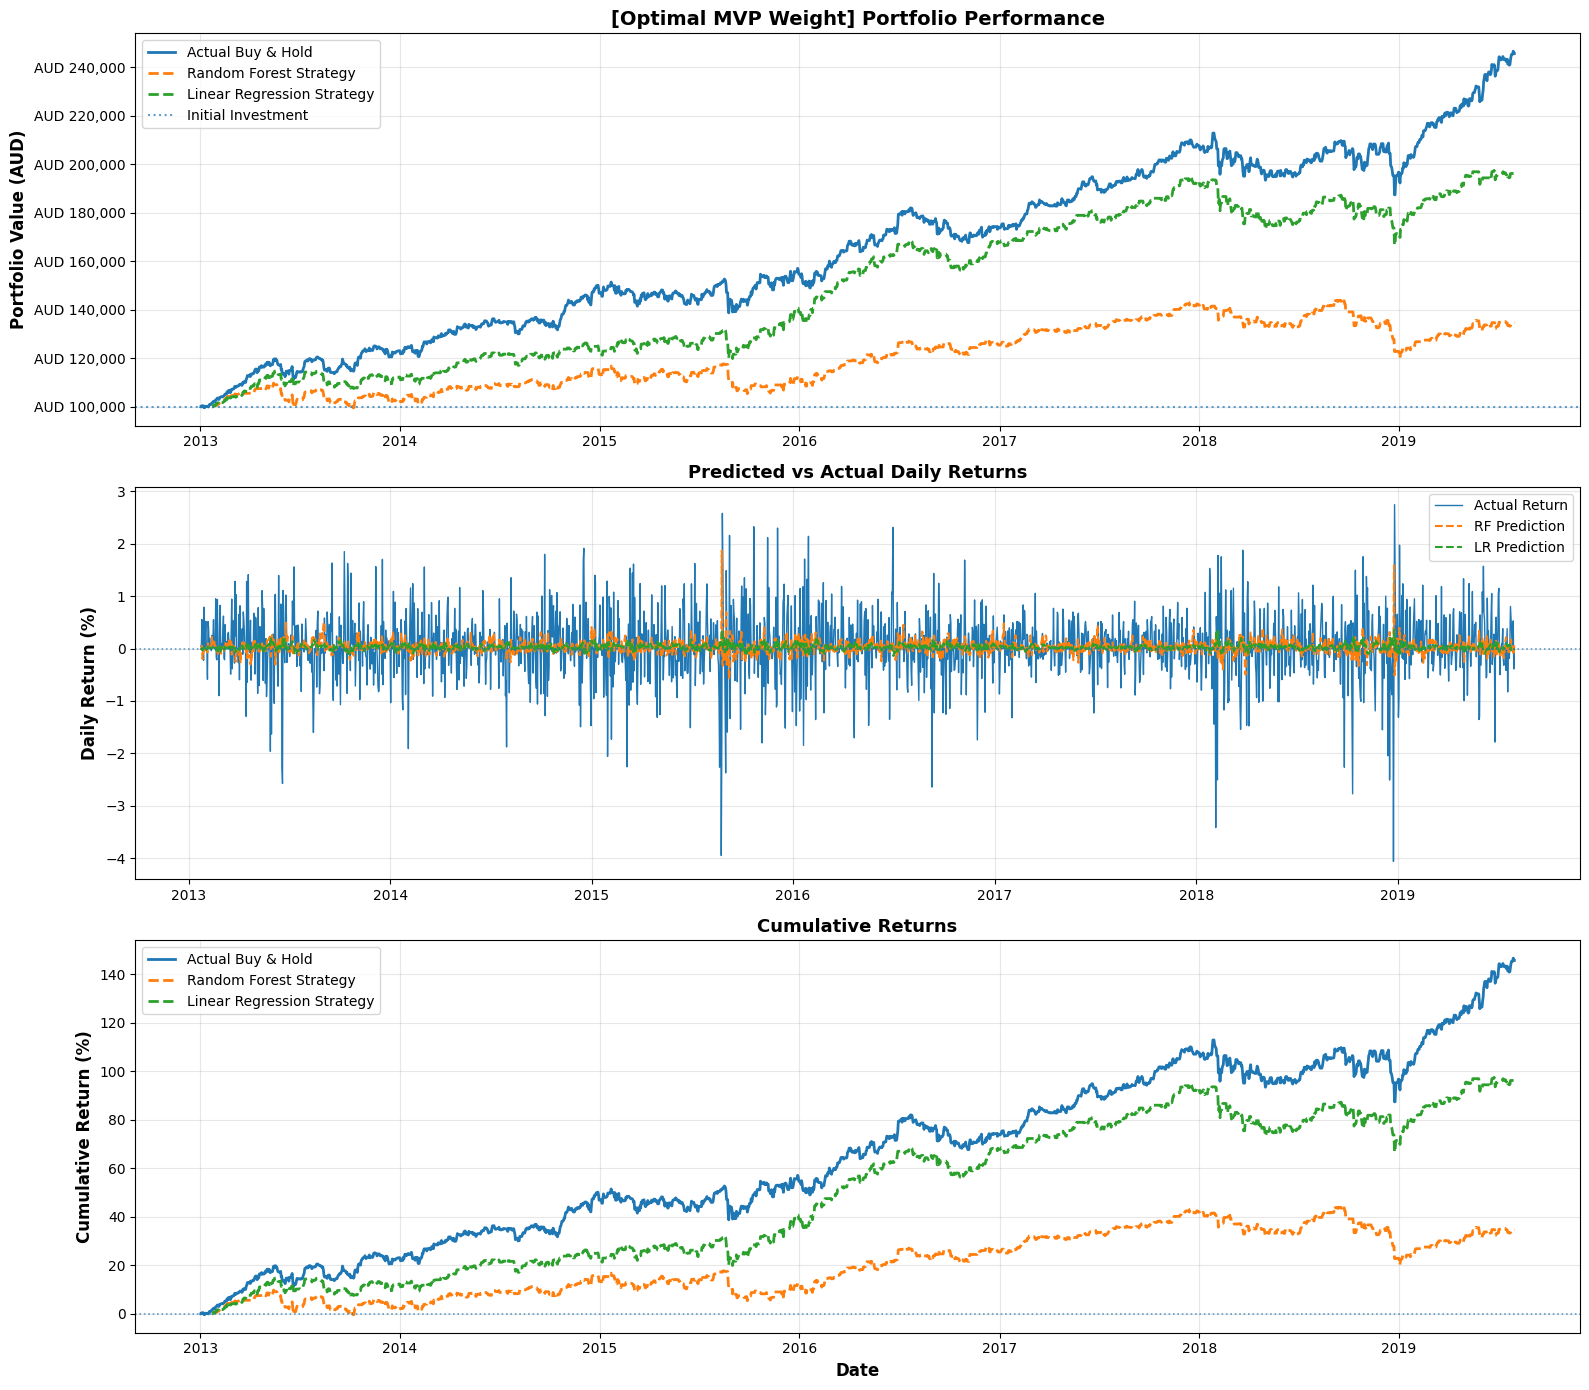


ML RETURN PREDICTION FOR: DYNAMIC INVERSE-VOLATILITY


,Strategy,Model,MSE,RMSE,MAE,R2,Directional Accuracy
0,Dynamic Inverse-Volatility,Random Forest,0.334908,0.578712,0.366248,-0.047716,0.481513
1,Dynamic Inverse-Volatility,Linear Regression,0.321161,0.566711,0.354166,-0.004710,0.421849


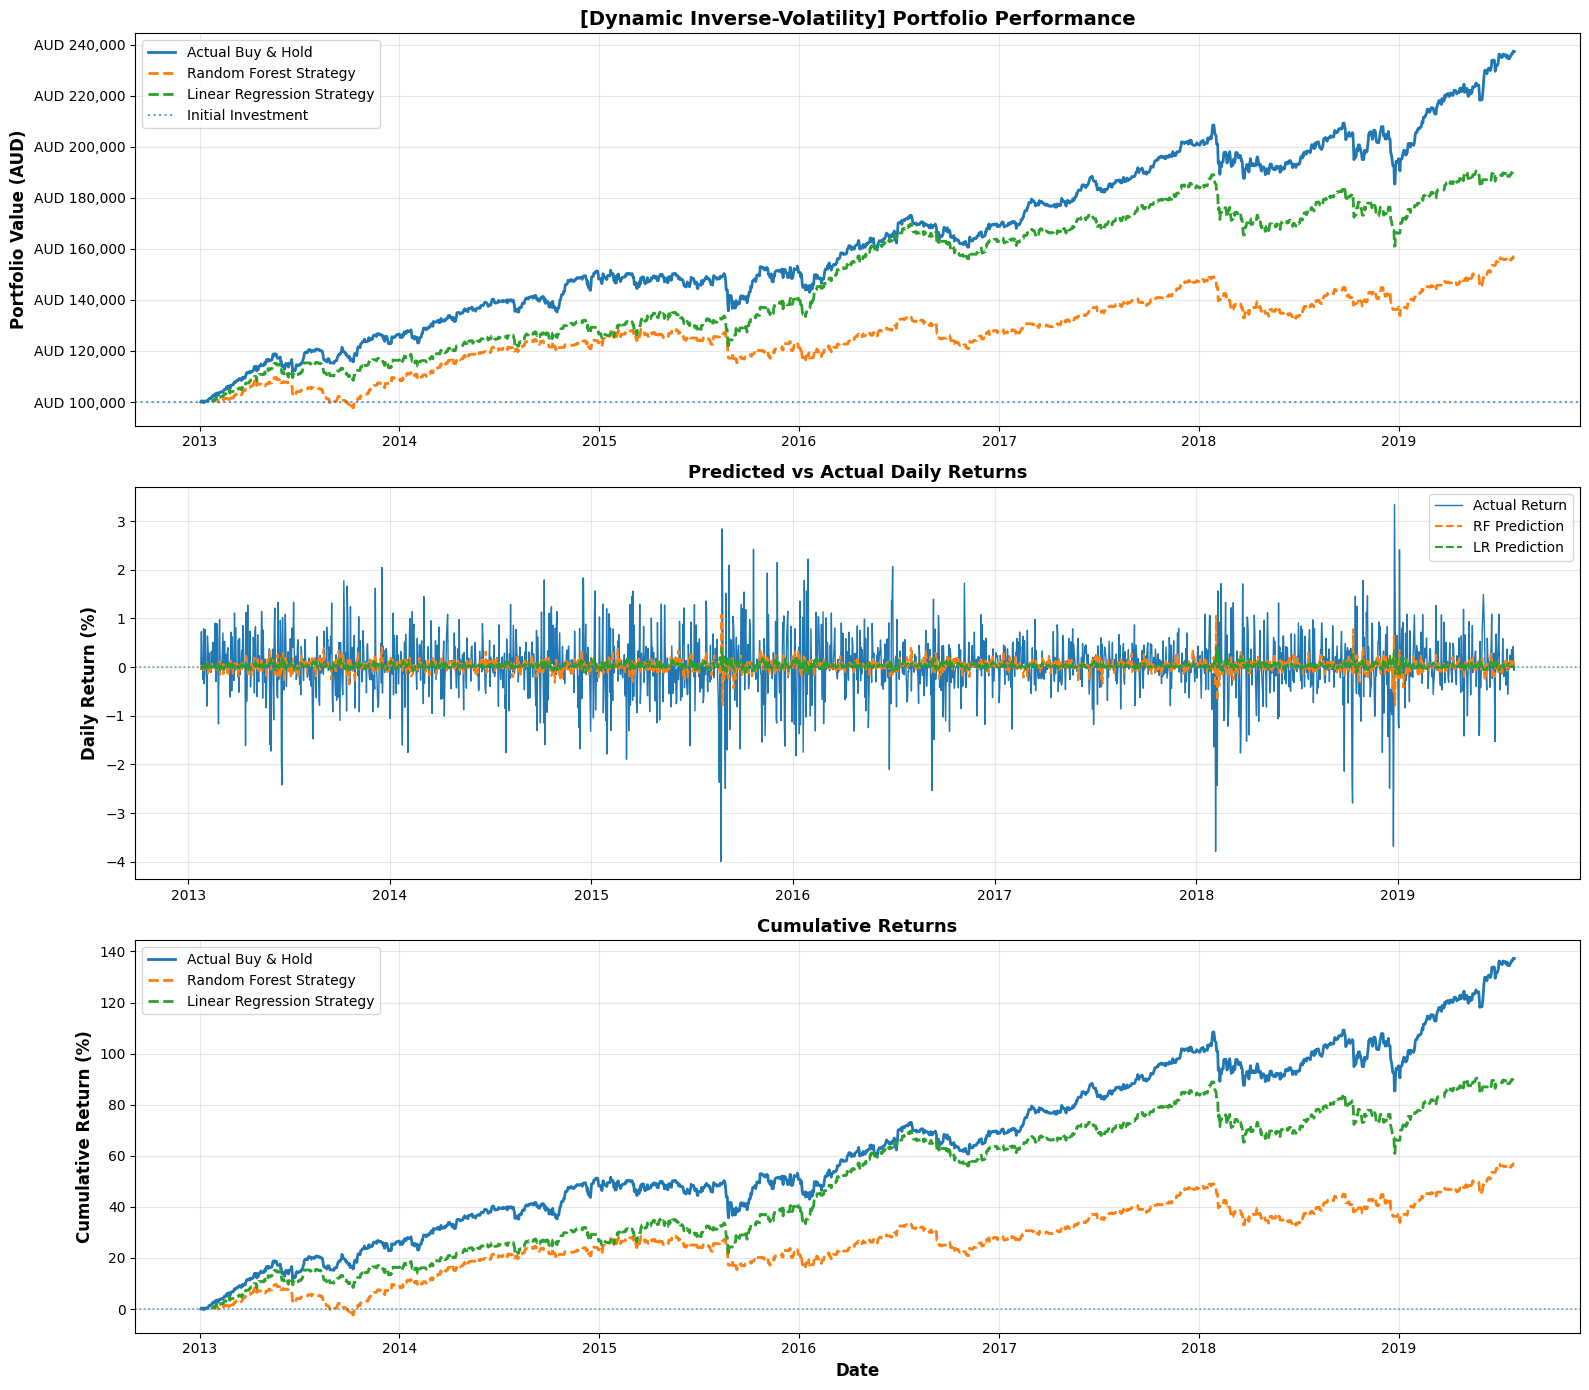


ML Model Evaluation Summary:


,Strategy,Model,MSE,RMSE,MAE,R2,Directional Accuracy
0,Equal Weight,Random Forest,0.359150,0.599292,0.380495,-0.054915,0.511550
1,Equal Weight,Linear Regression,0.342727,0.585429,0.365960,-0.006677,0.450231
2,Optimal MVP Weight,Random Forest,0.347201,0.589238,0.377978,-0.075338,0.474171
3,Optimal MVP Weight,Linear Regression,0.324398,0.569559,0.360351,-0.004712,0.453591
4,Dynamic Inverse-Volatility,Random Forest,0.334908,0.578712,0.366248,-0.047716,0.481513
5,Dynamic Inverse-Volatility,Linear Regression,0.321161,0.566711,0.354166,-0.004710,0.421849



ML Strategy Portfolio Performance Summary:


,Strategy,Final Value AUD,Profit/Loss AUD,Total Return %,Annualized Return %,Annualized Volatility %,Sharpe Ratio,Maximum Drawdown %
0,Equal Weight Buy & Hold,249626.239248,149626.239248,149.626239,10.072984,9.235800,1.090646,-13.989308
1,Equal Weight RF Strategy,193484.066361,93484.066361,93.484066,7.235337,7.494317,0.965443,-9.977988
2,Equal Weight LR Strategy,195405.080009,95405.080009,95.405080,7.347525,8.003942,0.917988,-16.866364
3,Optimal MVP Weight Buy & Hold,245708.685832,145708.685832,145.708686,9.890467,8.996313,1.099391,-11.971690
4,Optimal MVP Weight RF Strategy,134616.840914,34616.840914,34.616841,3.196177,7.366237,0.433895,-16.811046
5,Optimal MVP Weight LR Strategy,196221.080386,96221.080386,96.221080,7.394881,7.824575,0.945084,-14.395490
6,Dynamic Inverse-Volatility Buy & Hold,237270.710546,137270.710546,137.238665,9.490910,8.950144,1.060420,-11.381338
7,Dynamic Inverse-Volatility RF Strategy,156811.526566,56811.526566,56.811527,4.878648,7.141964,0.683096,-10.936378
8,Dynamic Inverse-Volatility LR Strategy,190576.857925,90576.857925,90.464118,7.060009,7.934897,0.889742,-14.794814


In [ ]:
# Store all results
all_ml_results = []
all_ml_performance = []

strategies = {
    'Equal Weight': {
        'train_value': equal_weight_train_value,
        'test_value': equal_weight_value
    },
    'Optimal MVP Weight': {
        'train_value': optimal_weight_train_value,
        'test_value': optimal_weight_value
    },
    'Dynamic Inverse-Volatility': {
        'train_value': dynamic_weight_train_value,
        'test_value': dynamic_weight_value
    }
}

for strategy_name, data in strategies.items():

    ml_results, predictions_df = train_and_evaluate_ml_models(
        data['train_value'],
        data['test_value'],
        strategy_name
    )

    all_ml_results.append(ml_results)

    rf_strategy_value = simulate_ml_strategy(
        data['test_value'],
        predictions_df,
        'Random Forest Prediction %',
        initial_capital=INITIAL_CAPITAL
    )

    lr_strategy_value = simulate_ml_strategy(
        data['test_value'],
        predictions_df,
        'Linear Regression Prediction %',
        initial_capital=INITIAL_CAPITAL
    )

    # Plot result
    plot_ml_strategy_result(
        strategy_name,
        data['test_value'],
        rf_strategy_value,
        lr_strategy_value,
        predictions_df,
        initial_capital=INITIAL_CAPITAL
    )

    # Add performance comparison
    all_ml_performance.append(
        calculate_strategy_performance(
            data['test_value'],
            f'{strategy_name} Buy & Hold',
            INITIAL_CAPITAL
        )
    )

    all_ml_performance.append(
        calculate_strategy_performance(
            rf_strategy_value,
            f'{strategy_name} RF Strategy',
            INITIAL_CAPITAL
        )
    )

    all_ml_performance.append(
        calculate_strategy_performance(
            lr_strategy_value,
            f'{strategy_name} LR Strategy',
            INITIAL_CAPITAL
        )
    )

# Combine ML model evaluation results
ml_model_evaluation_df = pd.concat(
    all_ml_results,
    ignore_index=True
)

# Combine portfolio performance results
ml_strategy_performance_df = pd.DataFrame(all_ml_performance)

print("\nML Model Evaluation Summary:")
display(ml_model_evaluation_df)

print("\nML Strategy Portfolio Performance Summary:")
display(ml_strategy_performance_df)

I constructed a fixed Minimum Variance Portfolio using optimal weights derived from historical training data from 1993-09-07 to 2013-01-01, and then tested its performance over the out-of-sample period from 2013-01-02 to 2019-07-31. The portfolio weights were estimated during the training period and then applied to the test period as a buy-and-hold benchmark.

As an optional machine learning extension, I overlaid a daily market-timing signal using Random Forest and Linear Regression models. These models were trained to predict the next-day portfolio return based on historical portfolio features. If the model predicted a positive return, the strategy invested in the fixed-weight portfolio for that day and captured the actual portfolio return. If the model predicted a negative return, the strategy exited the portfolio and held cash for that day.

This means the machine learning model did not select individual stocks or recalculate stock weights daily. Instead, it acted as an all-or-nothing market-timing filter on top of the pre-built MVP portfolio, deciding whether to be invested in the portfolio or remain in cash. The aim was to test whether machine learning could improve the buy-and-hold MVP strategy by capturing positive-return days and avoiding negative-return days.

In addition, a dynamic inverse-volatility portfolio was tested as a true dynamic-weight benchmark. Unlike the ML market-timing strategy, this method recalculates stock weights periodically based on recent volatility, assigning higher weights to lower-volatility stocks and lower weights to higher-volatility stocks.

# 3.2 Maximum return portfolio

####Finding optimum number of stocks in a portfolio
####by using annual volatility threshold of 25% and 35%. Ended up with 35% to maximise return while keeping portfolio volatility under acceptable limit.

In [ ]:

def calculate_stock_metrics(df_original, lookup_df):
    """
    Calculate geometric mean and standard deviation for each stock.

    Parameters:
    - df_original: DataFrame with Date index and stock columns
    - lookup_df: DataFrame with sector classifications

    Returns:
    - metrics_df: DataFrame with stock metrics
    """

    # Filter only resolved stocks
    resolved = lookup_df[lookup_df['ticker'] != 'UNRESOLVED'].copy()

    metrics = []

    for _, row in resolved.iterrows():
        bloomberg_col = row['bloomberg_col']
        sector = row['sector']
        ticker = row['ticker']

        if bloomberg_col in df_original.columns:
            prices = df_original[bloomberg_col].dropna()

            if len(prices) > 1:
                # Calculate returns
                returns = prices.pct_change().dropna()

                # Geometric mean of returns (annualized)
                # Add 1 to returns, take geometric mean, subtract 1, annualize
                if len(returns) > 0 and (returns + 1).prod() > 0:
                    geometric_mean = (returns + 1).prod() ** (252 / len(returns)) - 1
                    geometric_mean_pct = geometric_mean * 100  # Convert to percentage
                else:
                    geometric_mean_pct = np.nan

                # Standard deviation of returns (annualized)
                std_dev = returns.std() * np.sqrt(252) * 100  # Convert to percentage

                metrics.append({
                    'bloomberg_col': bloomberg_col,
                    'ticker': ticker,
                    'sector': sector,
                    'name': row['name'],
                    'geometric_mean': geometric_mean_pct,
                    'std_dev': std_dev
                })

    metrics_df = pd.DataFrame(metrics)

    # Remove any rows with NaN values
    metrics_df = metrics_df.dropna(subset=['geometric_mean', 'std_dev'])

    return metrics_df


def plot_risk_return_scatterplot(metrics_df):
    """
    Create scatterplot with standard deviation (X) vs geometric mean (Y).
    """

    fig, ax = plt.subplots(figsize=(16, 10))

    # Define colors for each sector
    sector_colors = {
        'Communication Services': '#E69F00',
        'Consumer Discretionary': '#56B4E9',
        'Consumer Staples': '#009E73',
        'Energy': '#F0E442',
        'Financials': '#0072B2',
        'Health Care': '#D55E00',
        'Industrials': '#CC79A7',
        'Information Technology': '#000000',
        'Materials': '#E8743B',
        'Real Estate': '#999999',
        'Utilities': '#00D9A3'
    }

    # Plot each sector
    for sector in metrics_df['sector'].unique():
        sector_data = metrics_df[metrics_df['sector'] == sector]

        ax.scatter(
            sector_data['std_dev'],
            sector_data['geometric_mean'],
            c=sector_colors.get(sector, '#000000'),
            label=sector,
            alpha=0.6,
            s=80,
            edgecolors='black',
            linewidth=0.5
        )

    ax.set_xlabel('Standard Deviation (Volatility) %', fontsize=14, fontweight='bold')
    ax.set_ylabel('Geometric Mean Return %', fontsize=14, fontweight='bold')
    ax.set_title('Risk-Return Profile by Industry', fontsize=16, fontweight='bold', pad=20)

    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax.axhline(y=0, color='red', linestyle='-', linewidth=1, alpha=0.3)
    ax.axvline(x=25, color='blue', linestyle='--', linewidth=1.5, alpha=0.5, label='25% Volatility Threshold')

    ax.legend(loc='best', fontsize=10, framealpha=0.9, edgecolor='black')

    plt.tight_layout()
    plt.savefig('risk_return_scatterplot.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, ax


def get_top_stocks_by_industry(metrics_df, volatility_threshold, top_n=10):
    """
    Get top N stocks from each industry with volatility less than threshold.
    Ranked by geometric mean (highest return).
    """

    # Filter by volatility threshold
    low_vol = metrics_df[metrics_df['std_dev'] < volatility_threshold].copy()

    results = {}

    for sector in sorted(low_vol['sector'].unique()):
        sector_stocks = low_vol[low_vol['sector'] == sector].copy()

        # Sort by geometric mean (descending)
        sector_stocks = sector_stocks.sort_values('geometric_mean', ascending=False)

        # Take top N
        top_stocks = sector_stocks.head(top_n)

        results[sector] = top_stocks

    return results


def display_top_stocks(top_stocks_dict,volatility_threshold):
    """
    Display the top stocks for each industry.
    """

    print("\n" + "="*100)
    print("TOP 10 STOCKS PER INDUSTRY (Volatility < ",volatility_threshold,"%)")
    print("="*100)

    for sector in sorted(top_stocks_dict.keys()):
        stocks = top_stocks_dict[sector]

        if len(stocks) == 0:
            print(f"\n{sector}: No stocks with volatility < ",volatility_threshold,"%")
            continue

        print(f"\n{sector} ({len(stocks)} stocks)")
        print("-"*100)
        print(f"{'Rank':<6} {'Ticker':<12} {'Name':<35} {'Geo Mean %':<15} {'Std Dev %':<12}")
        print("-"*100)

        for rank, (_, row) in enumerate(stocks.iterrows(), 1):
            print(f"{rank:<6} {row['ticker']:<12} {row['name'][:34]:<35} {row['geometric_mean']:>13.2f} {row['std_dev']:>11.2f}")

    print("="*100)


def create_summary_statistics(metrics_df, top_stocks_dict):
    """
    Create summary statistics table.
    """

    summary = []

    for sector in sorted(metrics_df['sector'].unique()):
        sector_data = metrics_df[metrics_df['sector'] == sector]
        low_vol_data = sector_data[sector_data['std_dev'] < 15]

        # Safely get best stock and return
        if len(low_vol_data) > 0:
            best_stock_row = low_vol_data.nlargest(1, 'geometric_mean')
            best_stock = best_stock_row['ticker'].values[0]
            best_return = best_stock_row['geometric_mean'].values[0]
        else:
            best_stock = 'N/A'
            best_return = np.nan

        summary.append({
            'Sector': sector,
            'Total Stocks': len(sector_data),
            'Low Vol Stocks': len(low_vol_data),})


# Main execution
df_filtered = df.loc['1993-09-07':'2013-01-01']
volatility_threshold = 25
print("\nCalculating stock metrics...")
metrics_df = calculate_stock_metrics(df_filtered, lookup_df)

print(f"Calculated metrics for {len(metrics_df)} stocks across {metrics_df['sector'].nunique()} sectors")

print("\nCreating scatterplot...")
fig, ax = plot_risk_return_scatterplot(metrics_df)

print("\nFinding top stocks per industry (volatility < ",volatility_threshold,"%)...")
top_stocks_dict = get_top_stocks_by_industry(metrics_df, volatility_threshold, top_n=10)

display_top_stocks(top_stocks_dict,volatility_threshold)

summary_df = create_summary_statistics(metrics_df, top_stocks_dict)

"""
# Save results
metrics_df.to_csv('stock_risk_return_metrics.csv', index=False)

# Save top stocks to CSV
all_top_stocks = pd.concat([df.assign(Sector=sector) for sector, df in top_stocks_dict.items()])
all_top_stocks.to_csv('top_stocks_low_volatility.csv', index=False)

print("\nFiles saved:")
print("  - risk_return_scatterplot.png")
print("  - stock_risk_return_metrics.csv")
print("  - top_stocks_low_volatility.csv")
"""

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def select_top_stocks_by_return(metrics_df, n_stocks, volatility_threshold):
    """
    Select top N stocks with highest geometric mean and volatility < threshold.
    """
    # Filter by volatility
    eligible = metrics_df[metrics_df['std_dev'] < volatility_threshold].copy()

    # Sort by geometric mean (descending)
    eligible = eligible.sort_values('geometric_mean', ascending=False)

    # Select top N
    selected = eligible.head(n_stocks)

    return selected


def calculate_portfolio_metrics(selected_stocks, df_original):
    """
    Calculate portfolio return and volatility using equal weights.
    """
    # Get returns for selected stocks
    returns_list = []

    for _, stock in selected_stocks.iterrows():
        bloomberg_col = stock['bloomberg_col']
        if bloomberg_col in df_original.columns:
            prices = df_original[bloomberg_col].dropna()
            returns = prices.pct_change().dropna()
            returns_list.append(returns)

    # Align all returns to same dates
    returns_df = pd.DataFrame({i: ret for i, ret in enumerate(returns_list)})
    returns_df = returns_df.dropna()

    if len(returns_df) == 0:
        return np.nan, np.nan, np.nan

    # Equal weights
    n_stocks = len(returns_list)
    weights = np.array([1/n_stocks] * n_stocks)

    # Portfolio returns
    portfolio_returns = (returns_df * weights).sum(axis=1)

    # Annualized metrics
    portfolio_geo_mean = ((1 + portfolio_returns).prod() ** (252 / len(portfolio_returns)) - 1) * 100
    portfolio_std = portfolio_returns.std() * np.sqrt(252) * 100
    sharpe_ratio = portfolio_geo_mean / portfolio_std if portfolio_std > 0 else 0

    return portfolio_geo_mean, portfolio_std, sharpe_ratio


def optimize_portfolio_size(metrics_df, df_original, portfolio_sizes, volatility_threshold):
    """
    Test different portfolio sizes and find optimal number of stocks.
    """
    results = []

    print("\n" + "="*100)
    print("PORTFOLIO SIZE OPTIMIZATION")
    print("="*100)
    print(f"{'N Stocks':<12} {'Portfolio Return %':<20} {'Portfolio Volatility %':<22} {'Sharpe Ratio':<15}")
    print("-"*100)

    for n in portfolio_sizes:
        # Select top N stocks
        selected = select_top_stocks_by_return(metrics_df, n, volatility_threshold)

        if len(selected) < n:
            print(f"{n:<12} Not enough eligible stocks (only {len(selected)} available)")
            continue

        # Calculate portfolio metrics
        port_return, port_vol, sharpe = calculate_portfolio_metrics(selected, df_original)

        if pd.notna(port_return):
            results.append({
                'n_stocks': n,
                'portfolio_return': port_return,
                'portfolio_volatility': port_vol,
                'sharpe_ratio': sharpe,
                'selected_stocks': selected
            })

            print(f"{n:<12} {port_return:>18.2f} {port_vol:>20.2f} {sharpe:>14.3f}")

    print("="*100)

    results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'selected_stocks'}
                               for r in results])

    return results, results_df


def plot_optimization_results(results_df):
    """
    Plot the results of portfolio size optimization.
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Plot 1: Portfolio Return vs Number of Stocks
    ax1 = axes[0, 0]
    ax1.plot(results_df['n_stocks'], results_df['portfolio_return'],
             marker='o', linewidth=2, markersize=8, color='green')
    ax1.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Portfolio Return vs Portfolio Size', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)

    # Highlight maximum
    max_return_idx = results_df['portfolio_return'].idxmax()
    max_return_n = results_df.loc[max_return_idx, 'n_stocks']
    max_return_val = results_df.loc[max_return_idx, 'portfolio_return']
    ax1.scatter([max_return_n], [max_return_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Return: {max_return_n} stocks')
    ax1.legend()

    # Plot 2: Portfolio Volatility vs Number of Stocks
    ax2 = axes[0, 1]
    ax2.plot(results_df['n_stocks'], results_df['portfolio_volatility'],
             marker='o', linewidth=2, markersize=8, color='orange')
    ax2.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Portfolio Volatility vs Portfolio Size', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(y=25, color='red', linestyle='--', alpha=0.5, label='25% Threshold')
    ax2.legend()

    # Plot 3: Sharpe Ratio vs Number of Stocks
    ax3 = axes[1, 0]
    ax3.plot(results_df['n_stocks'], results_df['sharpe_ratio'],
             marker='o', linewidth=2, markersize=8, color='blue')
    ax3.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Sharpe Ratio', fontsize=12, fontweight='bold')
    ax3.set_title('Sharpe Ratio vs Portfolio Size', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)

    # Highlight maximum
    max_sharpe_idx = results_df['sharpe_ratio'].idxmax()
    max_sharpe_n = results_df.loc[max_sharpe_idx, 'n_stocks']
    max_sharpe_val = results_df.loc[max_sharpe_idx, 'sharpe_ratio']
    ax3.scatter([max_sharpe_n], [max_sharpe_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Sharpe: {max_sharpe_n} stocks')
    ax3.legend()

    # Plot 4: Return vs Volatility (Efficient Frontier)
    ax4 = axes[1, 1]
    scatter = ax4.scatter(results_df['portfolio_volatility'], results_df['portfolio_return'],
                         c=results_df['n_stocks'], s=200, cmap='viridis',
                         edgecolors='black', linewidth=1.5, alpha=0.8)

    # Add labels for each point
    for _, row in results_df.iterrows():
        ax4.annotate(f"{int(row['n_stocks'])}",
                    (row['portfolio_volatility'], row['portfolio_return']),
                    fontsize=10, ha='center', va='center', fontweight='bold')

    ax4.set_xlabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax4.set_title('Efficient Frontier', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, ax=ax4)
    cbar.set_label('Number of Stocks', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig('portfolio_size_optimization.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, axes


def find_optimal_portfolio(results, results_df):
    """
    Determine the optimal portfolio size based on various criteria.
    """
    print("\n" + "="*100)
    print("OPTIMAL PORTFOLIO RECOMMENDATIONS")
    print("="*100)

    # Criterion 1: Maximum Sharpe Ratio
    max_sharpe_idx = results_df['sharpe_ratio'].idxmax()
    optimal_sharpe = results_df.loc[max_sharpe_idx]

    print(f"\n1. MAXIMUM SHARPE RATIO (Best Risk-Adjusted Return):")
    print(f"   Optimal Number of Stocks: {int(optimal_sharpe['n_stocks'])}")
    print(f"   Portfolio Return: {optimal_sharpe['portfolio_return']:.2f}%")
    print(f"   Portfolio Volatility: {optimal_sharpe['portfolio_volatility']:.2f}%")
    print(f"   Sharpe Ratio: {optimal_sharpe['sharpe_ratio']:.3f}")

    # Criterion 2: Maximum Return
    max_return_idx = results_df['portfolio_return'].idxmax()
    optimal_return = results_df.loc[max_return_idx]

    print(f"\n2. MAXIMUM RETURN:")
    print(f"   Optimal Number of Stocks: {int(optimal_return['n_stocks'])}")
    print(f"   Portfolio Return: {optimal_return['portfolio_return']:.2f}%")
    print(f"   Portfolio Volatility: {optimal_return['portfolio_volatility']:.2f}%")
    print(f"   Sharpe Ratio: {optimal_return['sharpe_ratio']:.3f}")

    # Criterion 3: Elbow method (marginal benefit analysis)
    results_df_sorted = results_df.sort_values('n_stocks')
    marginal_returns = results_df_sorted['portfolio_return'].diff()

    # Find where marginal benefit drops significantly
    if len(marginal_returns) > 2:
        avg_marginal = marginal_returns.mean()
        threshold = avg_marginal * 0.3  # Less than 30% of average marginal benefit

        elbow_candidates = results_df_sorted[marginal_returns < threshold]
        if len(elbow_candidates) > 0:
            elbow_idx = elbow_candidates.index[0] - 1
            if elbow_idx in results_df_sorted.index:
                optimal_elbow = results_df_sorted.loc[elbow_idx]

                print(f"\n3. ELBOW METHOD (Diminishing Returns):")
                print(f"   Optimal Number of Stocks: {int(optimal_elbow['n_stocks'])}")
                print(f"   Portfolio Return: {optimal_elbow['portfolio_return']:.2f}%")
                print(f"   Portfolio Volatility: {optimal_elbow['portfolio_volatility']:.2f}%")
                print(f"   Sharpe Ratio: {optimal_elbow['sharpe_ratio']:.3f}")

    print("\n" + "="*100)
    print("RECOMMENDATION: Use the portfolio with the MAXIMUM SHARPE RATIO")
    print(f"                ({int(optimal_sharpe['n_stocks'])} stocks)")
    print("="*100)

    # Return the optimal portfolio
    optimal_portfolio_idx = max_sharpe_idx
    optimal_stocks = results[optimal_portfolio_idx]['selected_stocks']

    return optimal_stocks, optimal_sharpe


def display_optimal_portfolio(optimal_stocks):
    """
    Display the stocks in the optimal portfolio.
    """
    print("\n" + "="*120)
    print("OPTIMAL PORTFOLIO COMPOSITION")
    print("="*120)
    print(f"{'Rank':<6} {'Ticker':<12} {'Sector':<30} {'Name':<35} {'Geo Mean %':<15} {'Std Dev %':<12}")
    print("-"*120)

    for rank, (_, stock) in enumerate(optimal_stocks.iterrows(), 1):
        print(f"{rank:<6} {stock['ticker']:<12} {stock['sector']:<30} "
              f"{stock['name'][:34]:<35} {stock['geometric_mean']:>13.2f} {stock['std_dev']:>11.2f}")

    print("="*120)

    # Sector distribution
    sector_counts = optimal_stocks['sector'].value_counts()
    print("\nSECTOR DISTRIBUTION:")
    print("-"*60)
    for sector, count in sector_counts.items():
        pct = (count / len(optimal_stocks)) * 100
        print(f"  {sector:<40} {count:>3} stocks ({pct:>5.1f}%)")
    print("-"*60)


# Main execution
df_filtered = df.loc['1993-09-07':'2013-01-01']
print("\nStarting portfolio size optimization...")

# Define portfolio sizes to test
portfolio_sizes = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# Run optimization
results, results_df = optimize_portfolio_size(metrics_df, df_filtered, portfolio_sizes, volatility_threshold=25)

# Plot results
plot_optimization_results(results_df)

# Find optimal portfolio
optimal_stocks, optimal_metrics = find_optimal_portfolio(results, results_df)

# Display optimal portfolio
display_optimal_portfolio(optimal_stocks)


#####Data Visualisation:
Using constraint:
1. Individual equity volatility cannot exceed 25%.
2. Each stock cannot represent more than 10% of the portfolio.
3. Each market sector cannot represent more than 30% of the portfolio.

Our optimum number of stocks in a portfolio is 15.
The stocks that have higher geometric mean return than other stocks in the same market sector are chosen.
But portfolio volatility is way below the threshold we set, we can try to increase our volatility threshold for individual stock to maximise return.


So we try volatility threshold=35:

In [ ]:
volatility_threshold = 35
print("\nFinding top stocks per industry (volatility < ",volatility_threshold,"%)...")
top_stocks_dict = get_top_stocks_by_industry(metrics_df, volatility_threshold, top_n=10)

display_top_stocks(top_stocks_dict,volatility_threshold)

summary_df = create_summary_statistics(metrics_df, top_stocks_dict)

In [ ]:
def plot_optimization_results(results_df):
    """
    Plot the results of portfolio size optimization.
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Plot 1: Portfolio Return vs Number of Stocks
    ax1 = axes[0, 0]
    ax1.plot(results_df['n_stocks'], results_df['portfolio_return'],
             marker='o', linewidth=2, markersize=8, color='green')
    ax1.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Portfolio Return vs Portfolio Size', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)

    # Highlight maximum
    max_return_idx = results_df['portfolio_return'].idxmax()
    max_return_n = results_df.loc[max_return_idx, 'n_stocks']
    max_return_val = results_df.loc[max_return_idx, 'portfolio_return']
    ax1.scatter([max_return_n], [max_return_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Return: {max_return_n} stocks')
    ax1.legend()

    # Plot 2: Portfolio Volatility vs Number of Stocks
    ax2 = axes[0, 1]
    ax2.plot(results_df['n_stocks'], results_df['portfolio_volatility'],
             marker='o', linewidth=2, markersize=8, color='orange')
    ax2.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Portfolio Volatility vs Portfolio Size', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(y=25, color='red', linestyle='--', alpha=0.5, label='35% Threshold')
    ax2.legend()

    # Plot 3: Sharpe Ratio vs Number of Stocks
    ax3 = axes[1, 0]
    ax3.plot(results_df['n_stocks'], results_df['sharpe_ratio'],
             marker='o', linewidth=2, markersize=8, color='blue')
    ax3.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Sharpe Ratio', fontsize=12, fontweight='bold')
    ax3.set_title('Sharpe Ratio vs Portfolio Size', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)

    # Highlight maximum
    max_sharpe_idx = results_df['sharpe_ratio'].idxmax()
    max_sharpe_n = results_df.loc[max_sharpe_idx, 'n_stocks']
    max_sharpe_val = results_df.loc[max_sharpe_idx, 'sharpe_ratio']
    ax3.scatter([max_sharpe_n], [max_sharpe_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Sharpe: {max_sharpe_n} stocks')
    ax3.legend()

    # Plot 4: Return vs Volatility (Efficient Frontier)
    ax4 = axes[1, 1]
    scatter = ax4.scatter(results_df['portfolio_volatility'], results_df['portfolio_return'],
                         c=results_df['n_stocks'], s=200, cmap='viridis',
                         edgecolors='black', linewidth=1.5, alpha=0.8)

    # Add labels for each point
    for _, row in results_df.iterrows():
        ax4.annotate(f"{int(row['n_stocks'])}",
                    (row['portfolio_volatility'], row['portfolio_return']),
                    fontsize=10, ha='center', va='center', fontweight='bold')

    ax4.set_xlabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax4.set_title('Efficient Frontier', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, ax=ax4)
    cbar.set_label('Number of Stocks', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig('portfolio_size_optimization.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, axes

In [ ]:
print("\nStarting portfolio size optimization...")
volatility_threshold = 35
# Define portfolio sizes to test
portfolio_sizes = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# Run optimization
results, results_df = optimize_portfolio_size(metrics_df, df_filtered, portfolio_sizes, volatility_threshold)

# Plot results
plot_optimization_results(results_df)

# Find optimal portfolio
optimal_stocks, optimal_metrics = find_optimal_portfolio(results, results_df)

# Display optimal portfolio
display_optimal_portfolio(optimal_stocks)

#####Data Visualisation:
Even though having 5 stocks has the highest return and sharpe ratio, but it goes against the constraint of a combination of stocks in a market sector must not exceed 30% of the portfolio.

The portfolio with 10 stocks is suitable in this case.

From the figure that shows the geo mean return to stock volatility, increasing stock volatility from 35% onwards does not show any significant increase in geo mean return, so futher volatility threshold is ignored.

In [ ]:
# Main execution
volatility_threshold = 35
print("\nStarting portfolio size optimization...")

# Define portfolio sizes to test
portfolio_sizes = [10, 20, 25, 30, 35, 40, 45, 50]

# Run optimization
results, results_df = optimize_portfolio_size(metrics_df, df_filtered, portfolio_sizes, volatility_threshold)

# Plot results
plot_optimization_results(results_df)

# Find optimal portfolio
optimal_stocks, optimal_metrics = find_optimal_portfolio(results, results_df)

# Display optimal portfolio
display_optimal_portfolio(optimal_stocks)

Given individual volatility of each stock is less than 35%, we choose the number of stocks with max return, in this case is 10.

In [ ]:
def create_fixed_portfolio(metrics_df, n_stocks, volatility_threshold=35):
    """
    Create a portfolio with top N stocks by geometric mean return.
    """
    # Filter by volatility
    eligible = metrics_df[metrics_df['std_dev'] < volatility_threshold].copy()

    # Sort by geometric mean (descending)
    eligible = eligible.sort_values('geometric_mean', ascending=False)

    # Select top N
    selected = eligible.head(n_stocks)

    print("\n" + "="*120)
    print(f"SELECTED PORTFOLIO: TOP {n_stocks} STOCKS BY GEOMETRIC MEAN (Volatility < {volatility_threshold}%)")
    print("="*120)
    print(f"{'Rank':<6} {'Ticker':<12} {'Sector':<30} {'Geo Mean %':<15} {'Std Dev %':<12}")
    print("-"*120)

    for rank, (_, stock) in enumerate(selected.iterrows(), 1):
        print(f"{rank:<6} {stock['ticker']:<12} {stock['sector']:<30} "
              f"{stock['geometric_mean']:>13.2f} {stock['std_dev']:>11.2f}")

    print("="*120)

    return selected


def backtest_portfolio(portfolio_stocks, df_data, initial_investment, period_name=None):
    """
    Backtest portfolio on a single dataset.

    Parameters:
    - portfolio_stocks: DataFrame with selected stocks
    - df_data: Price dataframe for ONE period
    - initial_investment: Starting capital
    - period_name: Optional label ('Train', 'Test', etc.)

    Returns:
    - portfolio_value: DataFrame with portfolio performance
    - shares: Dictionary of shares held
    """

    # Get stock columns
    stock_cols = portfolio_stocks['bloomberg_col'].tolist()

    # Extract prices
    portfolio_prices = df_data[stock_cols].copy()

    # Equal weighting
    n_stocks = len(stock_cols)
    weight_per_stock = 1 / n_stocks
    investment_per_stock = initial_investment * weight_per_stock

    # Buy shares at first available price
    shares = {}

    for col in stock_cols:
        first_price = portfolio_prices[col].dropna().iloc[0]
        shares[col] = investment_per_stock / first_price

    # Portfolio values
    portfolio_value = pd.DataFrame(index=portfolio_prices.index)

    for col in stock_cols:
        portfolio_value[col] = portfolio_prices[col] * shares[col]

    # Total portfolio value
    portfolio_value['Total'] = portfolio_value[stock_cols].sum(axis=1)

    # Daily returns
    portfolio_value['Daily_Return'] = portfolio_value['Total'].pct_change()

    # Cumulative return
    portfolio_value['Cumulative_Return'] = (
        1 + portfolio_value['Daily_Return']
    ).cumprod() - 1

    # Optional period label
    if period_name is not None:
        portfolio_value['Period'] = period_name

    return portfolio_value, shares

In [ ]:
portfolio_stocks = create_fixed_portfolio(metrics_df, n_stocks=10, volatility_threshold=35)
stock_cols = portfolio_stocks['bloomberg_col'].tolist()

df_train = df.loc['1993-09-07':'2013-01-01']
df_test  = df.loc['2013-01-01':'2019-07-31']

stock_cols = optimal_stocks['bloomberg_col'].tolist()[:10]

# Keep only selected stocks
price_data = df_train[stock_cols].copy()

# Remove rows with missing values
price_data = price_data.dropna()

print(f"Training period shape: {price_data.shape}")



####Initialisation of equal weights and relative weights distribution.

In [ ]:

# Daily returns
returns = price_data.pct_change().dropna()

def portfolio_return(weights, expected_returns):
    """
    Portfolio expected annual return.
    """
    return np.sum(weights * expected_returns)


def portfolio_volatility(weights, covariance_matrix):
    """
    Portfolio annualized volatility.
    """
    return np.sqrt(weights.T @ covariance_matrix @ weights)


def negative_sharpe_ratio(weights, expected_returns, covariance_matrix, risk_free_rate=0):
    """
    Negative Sharpe Ratio (for minimization).
    """
    port_return = portfolio_return(weights, expected_returns)

    port_vol = portfolio_volatility(weights, covariance_matrix)

    sharpe = (port_return - risk_free_rate) / port_vol

    return -sharpe

# Annualized geometric mean return
geo_returns = []

for col in returns.columns:

    compounded_growth = (1 + returns[col]).prod()

    n_years = len(returns) / 252

    geometric_return = compounded_growth**(1 / n_years) - 1

    geo_returns.append(geometric_return)

# Convert to numpy array
geo_returns =np.array(geo_returns)

# Covariance matrix (annualized)
cov_matrix = returns.cov().values * 252


#OPTIMIZATION CONSTRAINTS
n_assets = len(stock_cols)

# Initial equal weights
initial_weights = np.ones(n_assets) / n_assets

# Constraint: weights sum to 1
weight_constraint = {
    'type': 'eq',
    'fun': lambda w: np.sum(w) - 1
}

# Constraint: portfolio volatility <= 25%
volatility_constraint = {
    'type': 'ineq',
    'fun': lambda w: 0.25 - portfolio_volatility(w, cov_matrix)
}

constraints = [weight_constraint, volatility_constraint]

# Long-only portfolio bounds
# Minimum 1% allocation
# Maximum 25% allocation

min_weight = 0.05
max_weight = 0.25

bounds = tuple((min_weight, max_weight) for _ in range(n_assets))

# STEP 5: MAXIMUM SHARPE RATIO OPTIMIZATION

optimal_result = minimize(
    negative_sharpe_ratio,
    initial_weights,
    args=(geo_returns, cov_matrix, 0),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# Optimal weights
optimal_weights = optimal_result.x


In [ ]:
returns_train = df_train[stock_cols].pct_change()
returns_test  = df_test[stock_cols].pct_change()

# ── EQUAL WEIGHTS ────────────────────────────────────────────
equal_weights = np.array([1 / len(stock_cols)] * len(stock_cols))

portfolio_return_train_eq = returns_train.dot(equal_weights)
portfolio_return_test_eq  = returns_test.dot(equal_weights)

# ── OPTIMISED WEIGHTS ────────────────────────────────────────
portfolio_return_train_opt = returns_train.dot(optimal_weights)
portfolio_return_test_opt  = returns_test.dot(optimal_weights)


####Effecient frontier of using optimal weights

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import minimize

# ── helpers ────────────────────────────────────────────────────────────────────
def portfolio_return_val(weights, geo_returns):
    return np.dot(weights, geo_returns)

def portfolio_vol(weights, cov_matrix):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

def negative_sharpe(weights, geo_returns, cov_matrix, rf=0):
    r = portfolio_return_val(weights, geo_returns)
    v = portfolio_vol(weights, cov_matrix)
    return -(r - rf) / v if v > 1e-8 else 0

# ── inputs (plug in your own) ──────────────────────────────────────────────────
# geo_returns  : np.array of shape (n_assets,)  — annualised geometric returns
# cov_matrix   : np.array of shape (n_assets, n_assets) — already annualised (*252)
# n_assets, bounds, initial_weights — same as your existing setup

# ── 1. efficient frontier sweep ────────────────────────────────────────────────
target_returns = np.linspace(geo_returns.min(), geo_returns.max() * 0.95, 300)

frontier_vols, frontier_rets, frontier_weights = [], [], []
failed = 0

for target in target_returns:
    cons = [
        {'type': 'eq',  'fun': lambda w:       np.sum(w) - 1},
        {'type': 'eq',  'fun': lambda w, t=target: np.dot(w, geo_returns) - t},
    ]
    res = minimize(
        portfolio_vol,
        initial_weights,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=cons,
        options={'ftol': 1e-9, 'maxiter': 1000}
    )
    if res.success:
        frontier_vols.append(portfolio_vol(res.x, cov_matrix))
        frontier_rets.append(np.dot(res.x, geo_returns))
        frontier_weights.append(res.x)
    else:
        failed += 1

print(f"Frontier points: {len(frontier_vols)}  |  Failed: {failed}/{len(target_returns)}")

frontier_vols = np.array(frontier_vols)
frontier_rets = np.array(frontier_rets)

# ── 2. key portfolios ──────────────────────────────────────────────────────────
base_cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]

# minimum variance
res_minvol = minimize(portfolio_vol, initial_weights,
                      args=(cov_matrix,), method='SLSQP',
                      bounds=bounds, constraints=base_cons)
minvol_vol = portfolio_vol(res_minvol.x, cov_matrix)
minvol_ret = portfolio_return_val(res_minvol.x, geo_returns)

# maximum Sharpe
res_sharpe = minimize(negative_sharpe, initial_weights,
                      args=(geo_returns, cov_matrix, 0), method='SLSQP',
                      bounds=bounds, constraints=base_cons)
sharpe_vol = portfolio_vol(res_sharpe.x, cov_matrix)
sharpe_ret = portfolio_return_val(res_sharpe.x, geo_returns)

# equal weight
eq_w   = np.array([1 / n_assets] * n_assets)
eq_vol = portfolio_vol(eq_w, cov_matrix)
eq_ret = portfolio_return_val(eq_w, geo_returns)

# max return within vol cap
min_achievable_vol = frontier_vols.min()
vol_cap = min_achievable_vol * 1.10
valid_mask = frontier_vols <= vol_cap

if valid_mask.any():
    best_idx   = frontier_rets[valid_mask].argmax()
    best_vol   = frontier_vols[valid_mask][best_idx]
    best_ret   = frontier_rets[valid_mask][best_idx]
    best_w     = frontier_weights[np.where(valid_mask)[0][best_idx]]
    print(f"\nMax-return portfolio  vol={best_vol*100:.2f}%  ret={best_ret*100:.2f}%")
    print(f"Weights: {np.round(best_w, 4)}")

    # ── weight breakdown by stock ──────────────────────────────────────────────────
    print("\n--- Max Return (Vol ≤ Cap) Weight Breakdown ---")
    weight_df = pd.DataFrame({
        'Stock':  stock_cols,
        'Weight': best_w,
        'Weight %': best_w * 100
    }).sort_values('Weight', ascending=False).reset_index(drop=True)

    for _, row in weight_df.iterrows():
        print(f"  {row['Stock']:<6}  {row['Weight %']:>6.2f}%")

    print(f"\n  Total: {best_w.sum()*100:.2f}%")
else:
    print("No valid points under vol cap — widen the cap.")
    best_vol = best_ret = None

# ── 3. plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor('#f9f9f9')
fig.patch.set_facecolor('#ffffff')

# split frontier into efficient (upper) and inefficient (lower) halves
# the efficient portion starts at the minimum-variance point
minvol_idx = frontier_vols.argmin()
eff_vols = frontier_vols[minvol_idx:]
eff_rets = frontier_rets[minvol_idx:]
ineff_vols = frontier_vols[:minvol_idx]
ineff_rets = frontier_rets[:minvol_idx]

ax.plot(eff_vols * 100,   eff_rets * 100,   color='#1a73e8', linewidth=2.5, label='Efficient frontier')
ax.plot(ineff_vols * 100, ineff_rets * 100, color='#1a73e8', linewidth=1.2,
        linestyle='--', alpha=0.4, label='Inefficient (dominated)')

# vol cap line
ax.axvline(vol_cap * 100, color='#e53935', linewidth=1.2, linestyle='--',
           label=f'Vol cap ({vol_cap*100:.1f}%)')

# key portfolio dots
ax.scatter(minvol_vol * 100, minvol_ret * 100, s=90, color='#43a047',
           zorder=5, label=f'Min variance  ({minvol_vol*100:.1f}% vol, {minvol_ret*100:.1f}% ret)')
ax.scatter(sharpe_vol * 100, sharpe_ret * 100, s=90, color='#fb8c00',
           zorder=5, label=f'Max Sharpe    ({sharpe_vol*100:.1f}% vol, {sharpe_ret*100:.1f}% ret)')
ax.scatter(eq_vol * 100,     eq_ret * 100,     s=90, color='#8e24aa',
           zorder=5, label=f'Equal weight  ({eq_vol*100:.1f}% vol, {eq_ret*100:.1f}% ret)')

if best_vol is not None:
    ax.scatter(best_vol * 100, best_ret * 100, s=120, color='#1a73e8', edgecolors='white',
               linewidths=1.5, zorder=6,
               label=f'Max return (vol≤cap)  ({best_vol*100:.1f}% vol, {best_ret*100:.1f}% ret)')

# annotations
offset = {'min': (8, -12), 'sharpe': (8, 6), 'eq': (8, 6), 'best': (8, -14)}
for (x, y, lbl, off) in [
    (minvol_vol, minvol_ret, 'Min variance',       offset['min']),
    (sharpe_vol, sharpe_ret, 'Max Sharpe',          offset['sharpe']),
    (eq_vol,     eq_ret,     'Equal weight',        offset['eq']),
]:
    ax.annotate(lbl, xy=(x*100, y*100),
                xytext=(x*100 + off[0]/10, y*100 + off[1]/100),
                fontsize=8.5, color='#333333')

if best_vol is not None:
    ax.annotate('Max return\n(vol ≤ cap)', xy=(best_vol*100, best_ret*100),
                xytext=(best_vol*100 + 0.5, best_ret*100 - 0.015),
                fontsize=8.5, color='#1a73e8',
                arrowprops=dict(arrowstyle='->', color='#1a73e8', lw=0.8))

ax.set_xlabel('Annualised Volatility (%)', fontsize=11)
ax.set_ylabel('Annualised Return (%)',     fontsize=11)
ax.set_title('Efficient Frontier', fontsize=13, fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.4)
ax.tick_params(labelsize=9)

plt.tight_layout()
plt.savefig('efficient_frontier.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# your current max-Sharpe weights
current_ret = portfolio_return_val(optimal_weights, geo_returns)
current_vol = portfolio_vol(optimal_weights, cov_matrix)
current_sharpe = current_ret / current_vol

# new max-return-within-vol-cap weights
best_ret_val = portfolio_return_val(best_w, geo_returns)
best_vol_val = portfolio_vol(best_w, cov_matrix)
best_sharpe  = best_ret_val / best_vol_val

print("                  Return     Vol     Sharpe")
print(f"Max Sharpe (old): {current_ret*100:.2f}%    {current_vol*100:.2f}%   {current_sharpe:.3f}")
print(f"Max Return (new): {best_ret_val*100:.2f}%    {best_vol_val*100:.2f}%   {best_sharpe:.3f}")

####The max return weight distribution does not outperform optimal weights, thus we stick with using optimal weigths

####Initiation of dynamic weights based on 15 days momentum

In [ ]:
lookback = 15
rebalance_freq = 15

dynamic_weights_matrix = pd.DataFrame(
    index=returns_test.index,
    columns=stock_cols,
    dtype=float
)

current_weights = equal_weights.copy()

for t in range(len(returns_test)):
    if t % rebalance_freq == 0 and t >= lookback:
        recent = returns_test.iloc[t - lookback:t]

        # volatility per stock over lookback window
        recent_vol = recent.std()

        # avoid division by zero
        recent_vol = recent_vol.replace(0, np.nan)
        inv_vol = 1 / recent_vol

        # stocks with NaN vol (zero variance) get zero allocation
        inv_vol = inv_vol.fillna(0)

        if inv_vol.sum() > 0:
            current_weights = (inv_vol / inv_vol.sum()).values
        else:
            current_weights = equal_weights.copy()

    dynamic_weights_matrix.iloc[t] = current_weights

portfolio_return_test_dynamic = (returns_test * dynamic_weights_matrix).sum(axis=1)

#####Dynamic-weight portfolio daily return

In [ ]:
# element-wise multiply each day's returns by that day's weights
portfolio_return_test_dynamic = (returns_test * dynamic_weights_matrix).sum(axis=1)
portfolio_return_train_dynamic = None  # weights are test-only; train stays fixed

print(f"\nDynamic portfolio daily return stats:")
print(f"  Mean:  {portfolio_return_test_dynamic.mean()*100:.4f}%")
print(f"  Std:   {portfolio_return_test_dynamic.std()*100:.4f}%")
print(f"  Sharpe: {portfolio_return_test_dynamic.mean() / portfolio_return_test_dynamic.std() * np.sqrt(252):.3f}")

####Features initialising, in total 10

In [ ]:
def cross_sectional(returns, index):
    cs = pd.DataFrame(index=index)
    cs['pct_positive']  = (returns > 0).sum(axis=1).shift(1) / len(stock_cols)
    cs['max_return']    = returns.max(axis=1).shift(1)
    cs['min_return']    = returns.min(axis=1).shift(1)
    cs['return_spread'] = (returns.max(axis=1) - returns.min(axis=1)).shift(1)
    return cs


#Equal weights training
features_train_eq = pd.DataFrame(index=df_train.index)
features_train_eq['avg_return_1d']  = portfolio_return_train_eq.shift(1)
features_train_eq['avg_return_5d']  = portfolio_return_train_eq.rolling(5).mean().shift(1)
features_train_eq['avg_return_10d'] = portfolio_return_train_eq.rolling(10).mean().shift(1)
features_train_eq['avg_return_20d'] = portfolio_return_train_eq.rolling(20).mean().shift(1)
features_train_eq['volatility_5d']  = portfolio_return_train_eq.rolling(5).std().shift(1)
features_train_eq['volatility_10d'] = portfolio_return_train_eq.rolling(10).std().shift(1)
features_train_eq['volatility_20d'] = portfolio_return_train_eq.rolling(20).std().shift(1)
features_train_eq['momentum_5d']    = portfolio_return_train_eq.rolling(5).sum().shift(1)
features_train_eq['momentum_10d']   = portfolio_return_train_eq.rolling(10).sum().shift(1)
features_train_eq['momentum_20d']   = portfolio_return_train_eq.rolling(20).sum().shift(1)
features_train_eq = features_train_eq.join(cross_sectional(returns_train, df_train.index))

#testing set
features_test_eq = pd.DataFrame(index=df_test.index)
features_test_eq['avg_return_1d']  = portfolio_return_test_eq.shift(1)
features_test_eq['avg_return_5d']  = portfolio_return_test_eq.rolling(5).mean().shift(1)
features_test_eq['avg_return_10d'] = portfolio_return_test_eq.rolling(10).mean().shift(1)
features_test_eq['avg_return_20d'] = portfolio_return_test_eq.rolling(20).mean().shift(1)
features_test_eq['volatility_5d']  = portfolio_return_test_eq.rolling(5).std().shift(1)
features_test_eq['volatility_10d'] = portfolio_return_test_eq.rolling(10).std().shift(1)
features_test_eq['volatility_20d'] = portfolio_return_test_eq.rolling(20).std().shift(1)
features_test_eq['momentum_5d']    = portfolio_return_test_eq.rolling(5).sum().shift(1)
features_test_eq['momentum_10d']   = portfolio_return_test_eq.rolling(10).sum().shift(1)
features_test_eq['momentum_20d']   = portfolio_return_test_eq.rolling(20).sum().shift(1)
features_test_eq = features_test_eq.join(cross_sectional(returns_test, df_test.index))

# Optimised weights training set
features_train_opt = pd.DataFrame(index=df_train.index)
features_train_opt['avg_return_1d']  = portfolio_return_train_opt.shift(1)
features_train_opt['avg_return_5d']  = portfolio_return_train_opt.rolling(5).mean().shift(1)
features_train_opt['avg_return_10d'] = portfolio_return_train_opt.rolling(10).mean().shift(1)
features_train_opt['avg_return_20d'] = portfolio_return_train_opt.rolling(20).mean().shift(1)
features_train_opt['volatility_5d']  = portfolio_return_train_opt.rolling(5).std().shift(1)
features_train_opt['volatility_10d'] = portfolio_return_train_opt.rolling(10).std().shift(1)
features_train_opt['volatility_20d'] = portfolio_return_train_opt.rolling(20).std().shift(1)
features_train_opt['momentum_5d']    = portfolio_return_train_opt.rolling(5).sum().shift(1)
features_train_opt['momentum_10d']   = portfolio_return_train_opt.rolling(10).sum().shift(1)
features_train_opt['momentum_20d']   = portfolio_return_train_opt.rolling(20).sum().shift(1)
features_train_opt = features_train_opt.join(cross_sectional(returns_train, df_train.index))

#Testing set
features_test_opt = pd.DataFrame(index=df_test.index)
features_test_opt['avg_return_1d']  = portfolio_return_test_opt.shift(1)
features_test_opt['avg_return_5d']  = portfolio_return_test_opt.rolling(5).mean().shift(1)
features_test_opt['avg_return_10d'] = portfolio_return_test_opt.rolling(10).mean().shift(1)
features_test_opt['avg_return_20d'] = portfolio_return_test_opt.rolling(20).mean().shift(1)
features_test_opt['volatility_5d']  = portfolio_return_test_opt.rolling(5).std().shift(1)
features_test_opt['volatility_10d'] = portfolio_return_test_opt.rolling(10).std().shift(1)
features_test_opt['volatility_20d'] = portfolio_return_test_opt.rolling(20).std().shift(1)
features_test_opt['momentum_5d']    = portfolio_return_test_opt.rolling(5).sum().shift(1)
features_test_opt['momentum_10d']   = portfolio_return_test_opt.rolling(10).sum().shift(1)
features_test_opt['momentum_20d']   = portfolio_return_test_opt.rolling(20).sum().shift(1)
features_test_opt = features_test_opt.join(cross_sectional(returns_test, df_test.index))

# ── DYNAMIC WEIGHTS TEST SET ─────────────────────────────────
features_test_dynamic = pd.DataFrame(index=df_test.index)
features_test_dynamic['avg_return_1d']  = portfolio_return_test_dynamic.shift(1)
features_test_dynamic['avg_return_5d']  = portfolio_return_test_dynamic.rolling(5).mean().shift(1)
features_test_dynamic['avg_return_10d'] = portfolio_return_test_dynamic.rolling(10).mean().shift(1)
features_test_dynamic['avg_return_20d'] = portfolio_return_test_dynamic.rolling(20).mean().shift(1)
features_test_dynamic['volatility_5d']  = portfolio_return_test_dynamic.rolling(5).std().shift(1)
features_test_dynamic['volatility_10d'] = portfolio_return_test_dynamic.rolling(10).std().shift(1)
features_test_dynamic['volatility_20d'] = portfolio_return_test_dynamic.rolling(20).std().shift(1)
features_test_dynamic['momentum_5d']    = portfolio_return_test_dynamic.rolling(5).sum().shift(1)
features_test_dynamic['momentum_10d']   = portfolio_return_test_dynamic.rolling(10).sum().shift(1)
features_test_dynamic['momentum_20d']   = portfolio_return_test_dynamic.rolling(20).sum().shift(1)
features_test_dynamic = features_test_dynamic.join(cross_sectional(returns_test, df_test.index))


####KNNImputer and StandardScaler

In [ ]:
# ── EQUAL WEIGHTS ────────────────────────────────────────────
imputer_eq          = KNNImputer(n_neighbors=10, weights='distance')
X_train_eq_imputed  = imputer_eq.fit_transform(features_train_eq)
X_test_eq_imputed   = imputer_eq.transform(features_test_eq)

# Align targets
target_train_eq = portfolio_return_train_eq.loc[features_train_eq.index] * 100
target_test_eq  = portfolio_return_test_eq.loc[features_test_eq.index]   * 100

# Drop NaN from target, then match X to the same clean index
train_valid_idx     = target_train_eq.dropna().index
target_train_eq     = target_train_eq.loc[train_valid_idx]
X_train_eq_imputed  = X_train_eq_imputed[features_train_eq.index.isin(train_valid_idx)]

test_valid_idx      = target_test_eq.dropna().index
target_test_eq      = target_test_eq.loc[test_valid_idx] #slicing and only leaving rows with non Nan values
X_test_eq_imputed   = X_test_eq_imputed[features_test_eq.index.isin(test_valid_idx)]

scaler_eq         = StandardScaler()
X_train_eq_scaled = scaler_eq.fit_transform(X_train_eq_imputed)
X_test_eq_scaled  = scaler_eq.transform(X_test_eq_imputed)

# ── OPTIMISED WEIGHTS ────────────────────────────────────────
imputer_opt          = KNNImputer(n_neighbors=10, weights='distance')
X_train_opt_imputed  = imputer_opt.fit_transform(features_train_opt)
X_test_opt_imputed   = imputer_opt.transform(features_test_opt)

target_train_opt = portfolio_return_train_opt.loc[features_train_opt.index] * 100
target_test_opt  = portfolio_return_test_opt.loc[features_test_opt.index]   * 100

train_valid_idx      = target_train_opt.dropna().index
target_train_opt     = target_train_opt.loc[train_valid_idx]
X_train_opt_imputed  = X_train_opt_imputed[features_train_opt.index.isin(train_valid_idx)]

test_valid_idx       = target_test_opt.dropna().index
target_test_opt      = target_test_opt.loc[test_valid_idx]
X_test_opt_imputed   = X_test_opt_imputed[features_test_opt.index.isin(test_valid_idx)]

scaler_opt         = StandardScaler()
X_train_opt_scaled = scaler_opt.fit_transform(X_train_opt_imputed)
X_test_opt_scaled  = scaler_opt.transform(X_test_opt_imputed)

# ── DYNAMIC WEIGHTS ──────────────────────────────────────────
# train features and imputer are REUSED from optimised weights
# since the train period is identical — only test differs
imputer_dynamic         = KNNImputer(n_neighbors=10, weights='distance')
X_train_dynamic_imputed = imputer_dynamic.fit_transform(features_train_opt)  # same train features
X_test_dynamic_imputed  = imputer_dynamic.transform(features_test_dynamic)   # new dynamic test features

target_train_dynamic = portfolio_return_train_opt.loc[features_train_opt.index] * 100
target_test_dynamic  = portfolio_return_test_dynamic.loc[features_test_dynamic.index] * 100

train_valid_idx          = target_train_dynamic.dropna().index
target_train_dynamic     = target_train_dynamic.loc[train_valid_idx]
X_train_dynamic_imputed  = X_train_dynamic_imputed[features_train_opt.index.isin(train_valid_idx)]

test_valid_idx           = target_test_dynamic.dropna().index
target_test_dynamic      = target_test_dynamic.loc[test_valid_idx]
X_test_dynamic_imputed   = X_test_dynamic_imputed[features_test_dynamic.index.isin(test_valid_idx)]

scaler_dynamic          = StandardScaler()
X_train_dynamic_scaled  = scaler_dynamic.fit_transform(X_train_dynamic_imputed)
X_test_dynamic_scaled   = scaler_dynamic.transform(X_test_dynamic_imputed)

####Model training using
####1. RandomForestRegressor
####2. Multi-variable Linear Regression
####3. GradientBoosterRegressor
####4. AdaBoostRegressor

In [ ]:
# ── EQUAL WEIGHTS ────────────────────────────────────────────
rf_eq = RandomForestRegressor(
    n_estimators=200, max_depth=6,
    min_samples_split=20, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_eq.fit(X_train_eq_scaled, target_train_eq)
rf_pred_eq = rf_eq.predict(X_test_eq_scaled)

lr_eq = LinearRegression()
lr_eq.fit(X_train_eq_scaled, target_train_eq)
lr_pred_eq = lr_eq.predict(X_test_eq_scaled)

gb_eq = GradientBoostingRegressor(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb_eq.fit(X_train_eq_scaled, target_train_eq)
gb_pred_eq = gb_eq.predict(X_test_eq_scaled)

ada_eq = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200, learning_rate=0.05,
    random_state=42
)
ada_eq.fit(X_train_eq_scaled, target_train_eq)
ada_pred_eq = ada_eq.predict(X_test_eq_scaled)

# ── OPTIMISED WEIGHTS ────────────────────────────────────────
rf_opt = RandomForestRegressor(
    n_estimators=200, max_depth=6,
    min_samples_split=20, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_opt.fit(X_train_opt_scaled, target_train_opt)
rf_pred_opt = rf_opt.predict(X_test_opt_scaled)

lr_opt = LinearRegression()
lr_opt.fit(X_train_opt_scaled, target_train_opt)
lr_pred_opt = lr_opt.predict(X_test_opt_scaled)

gb_opt = GradientBoostingRegressor(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb_opt.fit(X_train_opt_scaled, target_train_opt)
gb_pred_opt = gb_opt.predict(X_test_opt_scaled)

ada_opt = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200, learning_rate=0.05,
    random_state=42
)
ada_opt.fit(X_train_opt_scaled, target_train_opt)
ada_pred_opt = ada_opt.predict(X_test_opt_scaled)

# ── DYNAMIC WEIGHTS ──────────────────────────────────────────
rf_dynamic = RandomForestRegressor(
    n_estimators=200, max_depth=6,
    min_samples_split=20, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
rf_pred_dynamic = rf_dynamic.predict(X_test_dynamic_scaled)

lr_dynamic = LinearRegression()
lr_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
lr_pred_dynamic = lr_dynamic.predict(X_test_dynamic_scaled)

gb_dynamic = GradientBoostingRegressor(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
gb_pred_dynamic = gb_dynamic.predict(X_test_dynamic_scaled)

ada_dynamic = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200, learning_rate=0.05,
    random_state=42
)
ada_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
ada_pred_dynamic = ada_dynamic.predict(X_test_dynamic_scaled)

In [ ]:

for label, y_true, rf_pred, lr_pred, gb_pred, ada_pred  in [
    ('EQUAL WEIGHTS',     target_test_eq,  rf_pred_eq,  lr_pred_eq, gb_pred_eq, ada_pred_eq),
    ('OPTIMISED WEIGHTS', target_test_opt, rf_pred_opt, lr_pred_opt, gb_pred_opt, ada_pred_opt),
]:
    print("\n" + "="*80)
    print(label)
    print("="*80)
    for model_name, y_pred in [('Random Forest', rf_pred), ('Linear Regression', lr_pred),('Gradient Boosting Regressor', gb_pred), ('Adaptive Boosting Regressor', ada_pred)]:
        mse  = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae  = mean_absolute_error(y_true, y_pred)
        r2   = r2_score(y_true, y_pred)
        dir_acc = ((y_true > 0) == (y_pred > 0)).mean()
        print(f"\n  {model_name}")
        print(f"    MSE:                  {mse:.8f}")
        print(f"    RMSE:                 {rmse:.6f}%")
        print(f"    MAE:                  {mae:.6f}%")
        print(f"    R²:                   {r2:.6f}")
        print(f"    Directional Accuracy: {dir_acc:.4f} ({dir_acc*100:.2f}%)")

####Model evaluation

In [ ]:

for label, y_true, rf_pred, lr_pred, gb_pred, ada_pred  in [
    ('EQUAL WEIGHTS',     target_test_eq,  rf_pred_eq,  lr_pred_eq, gb_pred_eq, ada_pred_eq),
    ('OPTIMISED WEIGHTS', target_test_opt, rf_pred_opt, lr_pred_opt, gb_pred_opt, ada_pred_opt),
    ('DYNAMIC WEIGHTS', target_test_dynamic, rf_pred_dynamic, lr_pred_dynamic, gb_pred_dynamic, ada_pred_dynamic)
]:
    print("\n" + "="*80)
    print(label)
    print("="*80)
    for model_name, y_pred in [('Random Forest', rf_pred), ('Linear Regression', lr_pred),('Gradient Boosting Regressor', gb_pred), ('Adaptive Boosting Regressor', ada_pred)]:
        mse  = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae  = mean_absolute_error(y_true, y_pred)
        r2   = r2_score(y_true, y_pred)
        dir_acc = ((y_true > 0) == (y_pred > 0)).mean()
        print(f"\n  {model_name}")
        print(f"    MSE:                  {mse:.8f}")
        print(f"    RMSE:                 {rmse:.6f}%")
        print(f"    MAE:                  {mae:.6f}%")
        print(f"    R²:                   {r2:.6f}")
        print(f"    Directional Accuracy: {dir_acc:.4f} ({dir_acc*100:.2f}%)")

####Portfolio simulation and Evaluation

In [ ]:
initial_investment = 100_000

for label, actual_returns, rf_pred, lr_pred, gb_pred, ada_pred, test_index in [
    ('EQUAL WEIGHTS',     target_test_eq.values      / 100, rf_pred_eq,      lr_pred_eq,      gb_pred_eq,      ada_pred_eq,      features_test_eq.index),
    ('OPTIMISED WEIGHTS', target_test_opt.values      / 100, rf_pred_opt,     lr_pred_opt,     gb_pred_opt,     ada_pred_opt,     features_test_opt.index),
    ('DYNAMIC WEIGHTS',   target_test_dynamic.values  / 100, rf_pred_dynamic, lr_pred_dynamic, gb_pred_dynamic, ada_pred_dynamic, features_test_dynamic.index),
]:

    # Align index to actual_returns length — guards against imputation misalignment
    test_index = test_index[:len(actual_returns)]

    actual_portfolio = [initial_investment]
    rf_portfolio     = [initial_investment]
    lr_portfolio     = [initial_investment]
    gb_portfolio     = [initial_investment]
    ada_portfolio    = [initial_investment]

    for i, r in enumerate(actual_returns):
        actual_portfolio.append(actual_portfolio[-1] * (1 + r))
        rf_portfolio.append(rf_portfolio[-1]   * (1 + r) if rf_pred[i]  > 0 else rf_portfolio[-1])
        lr_portfolio.append(lr_portfolio[-1]   * (1 + r) if lr_pred[i]  > 0 else lr_portfolio[-1])
        gb_portfolio.append(gb_portfolio[-1]   * (1 + r) if gb_pred[i]  > 0 else gb_portfolio[-1])
        ada_portfolio.append(ada_portfolio[-1] * (1 + r) if ada_pred[i] > 0 else ada_portfolio[-1])

    portfolio_df = pd.DataFrame({
        'Actual':             actual_portfolio[:-1],
        'Random_Forest':      rf_portfolio[:-1],
        'Linear_Regression':  lr_portfolio[:-1],
        'Gradient_Boosting':  gb_portfolio[:-1],
        'AdaBoost':           ada_portfolio[:-1],
    }, index=test_index)

    # ── Plot ─────────────────────────────────────────────────
    fig, axes = plt.subplots(3, 1, figsize=(16, 14))

    plot_series = [
        ('Actual',            'Actual (Buy & Hold)', 'blue',   '-',  2.5),
        ('Random_Forest',     'Random Forest',       'green',  '--', 2.0),
        ('Linear_Regression', 'Linear Regression',   'red',    '--', 2.0),
        ('Gradient_Boosting', 'Gradient Boosting',   'purple', ':',  2.0),
        ('AdaBoost',          'AdaBoost',            'orange', '-.', 2.0),
    ]

    for col, lbl, color, style, lw in plot_series:
        axes[0].plot(portfolio_df.index, portfolio_df[col],
                     linewidth=lw, label=lbl, color=color, linestyle=style)
    axes[0].axhline(y=initial_investment, color='gray', linestyle=':', alpha=0.5)
    axes[0].set_ylabel('Portfolio Value ($)', fontsize=12, fontweight='bold')
    axes[0].set_title(f'[{label}] Portfolio Performance (2013–2019)', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

    pred_series = [
        (actual_returns * 100, 'Actual Return',  'blue',   '-',  1.5, 0.7),
        (rf_pred,              'RF Prediction',  'green',  '--', 1.0, 0.6),
        (lr_pred,              'LR Prediction',  'red',    ':',  1.0, 0.6),
        (gb_pred,              'GB Prediction',  'purple', '--', 1.0, 0.6),
        (ada_pred,             'ADA Prediction', 'orange', '-.', 1.0, 0.6),
    ]

    for data, lbl, color, style, lw, alpha in pred_series:
        axes[1].plot(test_index, data, linewidth=lw, alpha=alpha,
                     label=lbl, color=color, linestyle=style)
    axes[1].axhline(y=0, color='gray', linestyle=':', alpha=0.5)
    axes[1].set_ylabel('Daily Return (%)', fontsize=12, fontweight='bold')
    axes[1].set_title('Predicted vs Actual Returns', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    for col, lbl, color, style, lw in plot_series:
        cum = ((portfolio_df[col] - initial_investment) / initial_investment) * 100
        axes[2].plot(portfolio_df.index, cum, linewidth=lw,
                     label=lbl, color=color, linestyle=style)
    axes[2].axhline(y=0, color='gray', linestyle=':', alpha=0.5)
    axes[2].set_xlabel('Date', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Cumulative Return (%)', fontsize=12, fontweight='bold')
    axes[2].set_title('Cumulative Returns', fontsize=14, fontweight='bold')
    axes[2].legend(fontsize=11)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'portfolio_{label.lower().replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ── Metrics ──────────────────────────────────────────────
    print("\n" + "="*80)
    print(f"PORTFOLIO PERFORMANCE — {label}")
    print("="*80)

    for strategy in ['Actual', 'Random_Forest', 'Linear_Regression', 'Gradient_Boosting', 'AdaBoost']:
        start_val  = portfolio_df[strategy].iloc[0]
        end_val    = portfolio_df[strategy].iloc[-1]
        total_ret  = (end_val - start_val) / start_val * 100
        daily_ret  = portfolio_df[strategy].pct_change().dropna()
        volatility = daily_ret.std() * np.sqrt(252) * 100
        years      = len(portfolio_df) / 252
        ann_ret    = ((end_val / start_val) ** (1 / years) - 1) * 100
        sharpe     = ann_ret / volatility if volatility > 0 else 0

        print(f"\n  {strategy.replace('_', ' ')}")
        print(f"    Final Value:       ${end_val:,.2f}")
        print(f"    Total Return:      {total_ret:.2f}%")
        print(f"    Annualized Return: {ann_ret:.2f}%")
        print(f"    Volatility:        {volatility:.2f}%")
        print(f"    Sharpe Ratio:      {sharpe:.4f}")
        print(f"    Profit/Loss:       ${end_val - initial_investment:,.2f}")

###I construct a fixed portfolio of 10 stocks using pre-optimised weights derived from historical data between 1993 and 2013, and simulate its performance over the out-of-sample test period from 2013 to 2019. Rather than passively holding the portfolio throughout the entire period, I overlay a daily market timing signal generated by my machine learning models — a Random Forest and a Linear Regression — which are trained to predict the next day's portfolio return. Each day, if my model predicts a positive return, I invest my entire capital into the fixed-weight portfolio and capture that day's actual return; if the model predicts a negative return, I exit the portfolio entirely and hold cash, avoiding that day's loss. This means I am not selecting individual stocks on a daily basis, but instead making a single all-or-nothing decision each day on whether to be invested in my pre-built portfolio or to sit in cash, with the goal of capturing the upside days while sidestepping the downside — effectively using my machine learning models as a market timing filter over a buy-and-hold foundation.